# mN2H allele pairwise test QC analysis and data upload

In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable, update_column

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from scipy.stats import pearsonr, spearmanr, shapiro, ttest_ind, ttest_rel

In [3]:
import glob
import xlrd

## Load data

### N2H WT pairwise test data

In [4]:
import warnings
warnings.simplefilter("ignore")

sheets = [f'Feuil{i}' for i in range (1, 22)]

wt_res = {'Exp1_1':dict(), 'Exp1_2':dict(), 'Exp2_1':dict(), 'Exp2_2':dict()}

for file_name in glob.glob('wt_data/*'):
     if 'N2H' in file_name:
        file_name = file_name.replace('~$','')
        print(file_name)
        xp = f'{file_name.split("_")[-1][:-7]}_{file_name.split("_")[-1][-6]}'
        print(xp)

        for sheet in sheets:

            df =  pd.read_excel(file_name, sheet_name=sheet)
            df.rename(columns={c:c.lower() for c in df}, inplace=True)

            for dest_pla, dest_well, RawData, NA in zip(df.dest_pla, df['dest_well.1'], df['raw data'], df['unnamed: 13']):
                if NA != 1:
                    wt_res[xp][(dest_pla,dest_well)] = RawData
                else:
                    wt_res[xp][(dest_pla,dest_well)] = np.nan

wt_data/N2H_VUS_WT_PWT_Exp1-1.xlsx
Exp1_1
wt_data/N2H_VUS_WT_PWT_Exp1-2.xlsx
Exp1_2
wt_data/N2H_VUS_WT_PWT_Exp2-1.xlsx
Exp2_1
wt_data/N2H_VUS_WT_PWT_Exp2-2.xlsx
Exp2_2


#### Retest table

In [5]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch']

query = f'select {", ".join(c for c in col)} from vus.retest where standard_batch = "N2HVUSWT";'


wt_df = GetDFv2(query, col=col)

for xp in wt_res:
    wt_df[xp] = [wt_res[xp][(pla, pos)] for pla, pos in zip(wt_df.retest_pla, wt_df.retest_pos)]
    
wt_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in wt_df.columns}, inplace=True)
wt_df.rename(columns={'Exp1_1':'mN2H_xp1r1','Exp1_2':'mN2H_xp1r2','Exp2_1':'mN2H_xp2r1','Exp2_2':'mN2H_xp2r2'}, inplace=True)

wt_df['xp1'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp1r1, wt_df.mN2H_xp1r2)]
wt_df['xp2'] = [np.mean([e for e in [r1,r2] if e == e]) if r1/r2 > 0.2 and r1/r2 < 5 else np.nan for r1,r2 in zip(wt_df.mN2H_xp2r1, wt_df.mN2H_xp2r2)]

wt_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2
0,56684,VAC14,5385,WRAP53,wt,1,A01,N2HVUSWT,11699593.0,14806264.0,10515314.0,11083491.0,13252928.5,10799402.5
1,2194,TEX37,0,None,empty_N2,1,B01,N2HVUSWT,2800.0,3107.0,2751.0,2794.0,2953.5,2772.5
2,2877,RGR,0,None,empty_N2,1,C01,N2HVUSWT,430.0,534.0,546.0,583.0,482.0,564.5
3,14269,ZNF774,54082,PRPF31,wt,1,D01,N2HVUSWT,NaN,NaN,NaN,NaN,NaN,NaN
4,0,None,8768,TSTD2,empty_N1,1,F01,N2HVUSWT,6852.0,7313.0,7841.0,8375.0,7082.5,8108.0


In [6]:
wt_df[(wt_df.N1_orf_id==1108) & (wt_df.N2_orf_id==5001)]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2
660,1108,LCP2,5001,NCK1,PRS,8,H04,N2HVUSWT,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0


In [7]:
prs_rrs_symbol_to_orf_d = dict(zip(wt_df.N1_symbol, wt_df.N1_orf_id))
for s2,o2 in zip(wt_df.N2_symbol, wt_df.N2_orf_id):
    prs_rrs_symbol_to_orf_d[s2] = o2

In [8]:
#wt_df[wt_df.mN2H_xp2r1 / wt_df.mN2H_xp2r2 < 0.2]

In [9]:
#wt_df[wt_df.mN2H_xp2r1 / wt_df.mN2H_xp2r2 > 5]

In [10]:
#wt_df[wt_df.mN2H_xp1r1 / wt_df.mN2H_xp1r2 < 0.2]

In [11]:
#wt_df[wt_df.mN2H_xp1r1 / wt_df.mN2H_xp1r2 > 5]

In [12]:
wt_raw_d = {(N1_orf_id,N2_orf_id):(mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2) for i,(N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2) in wt_df.iterrows()}


#### NLR

In [13]:
empty_N1_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp1))
empty_N2_xp1_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp1))

empty_N1_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N1'].N2_orf_id, wt_df[wt_df.variant_id == 'empty_N1'].xp2))
empty_N2_xp2_d = dict(zip(wt_df[wt_df.variant_id == 'empty_N2'].N1_orf_id, wt_df[wt_df.variant_id == 'empty_N2'].xp2))

normalized_wt_df = wt_df[wt_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_wt_df['empty_N1_xp1'] = normalized_wt_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp1'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_wt_df['empty_N1_xp2'] = normalized_wt_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id], axis=1)
normalized_wt_df['empty_N2_xp2'] = normalized_wt_df.N1_orf_id.map(empty_N2_xp2_d)

normalized_wt_df['NLR_xp1'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp1, normalized_wt_df.empty_N1_xp1, normalized_wt_df.empty_N2_xp1)]
normalized_wt_df['NLR_xp2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_wt_df.xp2, normalized_wt_df.empty_N1_xp2, normalized_wt_df.empty_N2_xp2)]

df = normalized_wt_df[normalized_wt_df.variant_id == 'RRS']
normalized_wt_df['zNLR1'] = normalized_wt_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
normalized_wt_df['zNLR2'] = normalized_wt_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

normalized_wt_df['NLR'] = normalized_wt_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)

normalized_wt_df['pair'] = [tuple(sorted([n1,n2])) for n1,n2 in zip(normalized_wt_df.N1_symbol, normalized_wt_df.N2_symbol)]

normalized_wt_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,pair
0,56684,VAC14,5385,WRAP53,wt,1,A01,N2HVUSWT,11699593.0,14806264.0,10515314.0,11083491.0,13252928.5,10799402.5,72117.0,91875.5,58473.0,42441.0,7.172415,7.528965,2.155925,2.353985,7.350690,"(VAC14, WRAP53)"
3,14269,ZNF774,54082,PRPF31,wt,1,D01,N2HVUSWT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2588.0,NaN,1802.0,NaN,NaN,NaN,NaN,NaN,"(PRPF31, ZNF774)"
7,11621,MTIF3,4062,PLP1,wt,1,B02,N2HVUSWT,137890.0,147070.0,159117.0,164042.0,142480.0,161579.5,5120.5,4630.0,3893.0,4172.0,4.798331,5.275361,1.353275,1.567430,5.036846,"(MTIF3, PLP1)"
8,1868,FATE1,3535,EMD,wt,1,C02,N2HVUSWT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4531.5,NaN,3386.5,NaN,NaN,NaN,NaN,NaN,"(EMD, FATE1)"
9,9117,UNKL,5431,POLR1C,wt,1,D02,N2HVUSWT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12415.5,NaN,9425.0,NaN,NaN,NaN,NaN,NaN,"(POLR1C, UNKL)"


In [14]:
df = normalized_wt_df[normalized_wt_df.variant_id.isin(['PRS','RRS'])]

wt_prs_rrs_d = {pair:(a,b,c,d,e) for pair, a,b,c,d,e in zip(df.pair, df.NLR_xp1, df.NLR_xp2, df.zNLR1, df.zNLR2, df.NLR)}


In [15]:
normalized_wt_df.variant_id.value_counts()

wt     714
RRS     78
PRS     60
Name: variant_id, dtype: int64

In [16]:
df = normalized_wt_df[normalized_wt_df.variant_id.isin(['wt','PRS','RRS'])]

wt_d = {(n1,n2):(a,b,c,d,e) for n1,n2, a,b,c,d,e in zip(df.N1_orf_id, df.N2_orf_id, df.NLR_xp1, df.NLR_xp2, df.zNLR1, df.zNLR2, df.NLR)}


In [17]:
wt_d[(56684,5385)]

(7.172415275713879,
 7.528965167336296,
 2.155924537925588,
 2.3539847626558146,
 7.350690221525088)

In [18]:
# NLR_xp1
# NLR_xp2
# zNLR1
# zNLR2
# NLR

In [19]:
normalized_wt_df.NLR.isnull().sum(), len(normalized_wt_df)

(227, 852)

### N2H allele pairwise test data (previous, old experiment)

In [20]:
col  =  ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol','db_mut_id', 'retest_pla', 'retest_pos',
       'standard_batch', 'variant_id',
       'db_source_plate', 'db_source_well', 'ad_source_plate',
       'ad_source_well']

query = f'select {", ".join(c for c in col)} from vus.retest where standard_batch = "mN2Hapwt";'


previous_retest_df = GetDFv2(query, col=col)
previous_retest_df.sort_values(by=['retest_pla','retest_pos'],inplace=True)
previous_retest_df['db_mut_id'] = previous_retest_df.db_mut_id.apply(lambda x: x if x == x else 0)
previous_retest_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well
0,11621,MTIF3,4062,PLP1,201426.0,1,A01,mN2Hapwt,allele,N2H_mut_N2_8,E05,N2H_int_N1_2,F10
7,0,None,5222,MCMBP,0.0,1,A02,mN2Hapwt,empty_N1,yN2H_PRS_N2_2B,D08,N2H_Fragment1,F04
15,14862,GOLGA2,2920,GFAP,0.0,1,A03,mN2Hapwt,wt,N2H_DisWT_N2_3,A03,N2H_int_N1_6,H05
23,0,None,4656,SKP2,0.0,1,A04,mN2Hapwt,empty_N1,yN2H_PRS_N2_1B,A10,N2H_Fragment1,B04
31,0,None,3291,GTF2F2,0.0,1,A05,mN2Hapwt,empty_N1,yN2H_PRS_N2_2B,C11,N2H_Fragment1,E03


In [21]:
d = {'1-1':{},
     '1-2':{},
     '2-1':{},
     '2-2':{}
    }

d_empty =   {'1-1':[],
     '1-2':[],
     '2-1':[],
     '2-2':[]
    }

for sheet in ['1-1','1-2','2-1','2-2']:
    df = pd.read_excel('mN2H disease allele results.xlsx',index_col=0,sheet_name=sheet)
    d[sheet] = {(int(pla.split('_')[-1]),well):RLU  for pla, well, RLU in zip(df[~df.retest_type.isnull()].N1_plate, df[~df.retest_type.isnull()].N1_well, df[~df.retest_type.isnull()].RLU)}
    previous_retest_df[f'B{sheet[0]}R{sheet[-1]}'] =  [d[sheet][pla, pos] for pla, pos in zip(previous_retest_df.retest_pla, previous_retest_df.retest_pos)]
    
    d_empty[sheet] += df[df.retest_type.isnull()].RLU.tolist()
    
previous_retest_df['B1'] = [np.mean([r1,r2]) for r1, r2 in zip(previous_retest_df.B1R1, previous_retest_df.B1R2)]
previous_retest_df['B2'] = [np.mean([r1,r2]) for r1, r2 in zip(previous_retest_df.B2R1, previous_retest_df.B2R2)]

previous_retest_df['rlu'] = [np.mean([b1,b2]) if b1/b2 > 0.1 or b1/b2 < 10 else max([b1,b2]) for b1,b2 in zip(previous_retest_df.B1, previous_retest_df.B2)]
previous_retest_df.head()

,ad_orf_id,ad_symbol,db_orf_id,db_symbol,db_mut_id,retest_pla,retest_pos,standard_batch,variant_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,B1R1,B1R2,B2R1,B2R2,B1,B2,rlu
0,11621,MTIF3,4062,PLP1,201426.0,1,A01,mN2Hapwt,allele,N2H_mut_N2_8,E05,N2H_int_N1_2,F10,83304.0,97691.0,15995.0,14294.0,90497.5,15144.5,52821.00
7,0,None,5222,MCMBP,0.0,1,A02,mN2Hapwt,empty_N1,yN2H_PRS_N2_2B,D08,N2H_Fragment1,F04,7921.0,9757.0,2235.0,1891.0,8839.0,2063.0,5451.00
15,14862,GOLGA2,2920,GFAP,0.0,1,A03,mN2Hapwt,wt,N2H_DisWT_N2_3,A03,N2H_int_N1_6,H05,607769.0,756823.0,145897.0,110739.0,682296.0,128318.0,405307.00
23,0,None,4656,SKP2,0.0,1,A04,mN2Hapwt,empty_N1,yN2H_PRS_N2_1B,A10,N2H_Fragment1,B04,203.0,209.0,154.0,147.0,206.0,150.5,178.25
31,0,None,3291,GTF2F2,0.0,1,A05,mN2Hapwt,empty_N1,yN2H_PRS_N2_2B,C11,N2H_Fragment1,E03,135.0,196.0,147.0,154.0,165.5,150.5,158.00


In [22]:
previous_pwt_d = {(n1,n2,n2_mut_id):rlu for n1,n2,n2_mut_id,rlu in zip(previous_retest_df.ad_orf_id, previous_retest_df.db_orf_id, previous_retest_df.db_mut_id, previous_retest_df.rlu)}


### Control data ( Soon Gang Choi)

In [23]:
raw_sg_data = pd.read_excel('../../../MasterThesis_Gaspard/data/41467_2019_11809_MOESM6_ESM.xlsx',sheet_name='N2H raw data with 3 replicates',engine='openpyxl')
raw_sg_data.rename(columns={c:'_'.join(w for w in c.replace('(','').replace(')','').split()) for c in raw_sg_data.columns},inplace=True)

col = ['Category', 'Symbol_X', 'Symbol_Y',
       'MN2H_N1N2_rep1', 'MN2H_N1N2_rep2', 'MN2H_N1N2_rep3',
       'MN2H_F1N2_rep1', 'MN2H_F1N2_rep2', 'MN2H_F1N2_rep3','MN2H_N1F2_rep1', 'MN2H_N1F2_rep2', 'MN2H_N1F2_rep3']

raw_sg_data = raw_sg_data[col].copy()
sg_raw_mn2h_d = {(s1,s2):(r1,r2,r3, en1r1, en1r2, en1r3, en2r1,en2r2,en2r3) for i,(Category,s1,s2,r1,r2,r3,en1r1,en1r2,en1r3,en2r1,en2r2,en2r3) in raw_sg_data.iterrows()}

for rep in ['1','2','3']:
    raw_sg_data[f'NLR{rep}'] = [np.log2(n1n2 / max(n2, n1)) for n1n2, n2, n1 in zip(raw_sg_data[f'MN2H_N1N2_rep{rep}'], raw_sg_data[f'MN2H_F1N2_rep{rep}'], raw_sg_data[f'MN2H_N1F2_rep{rep}'])]

raw_sg_data['avg_NLR'] = [np.mean([NLR1,NLR2,NLR3]) for NLR1,NLR2,NLR3 in zip(raw_sg_data.NLR1, raw_sg_data.NLR2, raw_sg_data.NLR3)]

raw_sg_data['Symbol_Y'] = raw_sg_data.Symbol_Y.apply(lambda x: x if x != 'NUDT4' else 'NUDT4P1')
raw_sg_data['Symbol_X'] = raw_sg_data.Symbol_X.apply(lambda x: x if x != 'DEFA1' else 'DEFA3')
raw_sg_data['Symbol_X'] = raw_sg_data.Symbol_X.apply(lambda x: x if x != 'HBA2' else 'HBA1')

raw_sg_data['pair'] = [tuple(sorted([x,y])) for x,y in zip(raw_sg_data.Symbol_X, raw_sg_data.Symbol_Y)]
raw_sg_data['detected'] = raw_sg_data.avg_NLR.apply(lambda x: x > max(raw_sg_data[raw_sg_data.Category=='RRS'].avg_NLR))

sg_mn2h_d = {pair:(r1,r2,r3) for pair, r1,r2,r3 in zip(raw_sg_data.pair, raw_sg_data.NLR1,raw_sg_data.NLR2,raw_sg_data.NLR3)}

raw_sg_data.head()

,Category,Symbol_X,Symbol_Y,MN2H_N1N2_rep1,MN2H_N1N2_rep2,MN2H_N1N2_rep3,MN2H_F1N2_rep1,MN2H_F1N2_rep2,MN2H_F1N2_rep3,MN2H_N1F2_rep1,MN2H_N1F2_rep2,MN2H_N1F2_rep3,NLR1,NLR2,NLR3,avg_NLR,pair,detected
0,PRS,LCP2,NCK1,451586,599322,749721,373,427,345,284555,758302,653100,0.666293,-0.339441,0.199050,0.175301,"(LCP2, NCK1)",False
1,RRS,SHMT2,STAC3,11082,16422,22999,243,354,314,14678,41964,41271,-0.405437,-1.353522,-0.843557,-0.867506,"(SHMT2, STAC3)",False
2,RRS,EMD,ARMC1,5364,7114,7810,205,266,190,499710,1161783,1090809,-6.541638,-7.351464,-7.125860,-7.006321,"(ARMC1, EMD)",False
3,RRS,PDHB,ZC3HC1,3745,6518,6973,376,745,568,25356,67020,51386,-2.759290,-3.362090,-2.881524,-3.000968,"(PDHB, ZC3HC1)",False
4,RRS,FKBP3,NQO2,21407,23227,39366,261,287,278,34787,47024,19897,-0.700466,-1.017594,0.984399,-0.244554,"(FKBP3, NQO2)",False


In [24]:
orf_mapping = GetOrfMapping()

orf_mapping[orf_mapping.symbol == 'DEFA1']

,orf_id,ensembl_gene_id,symbol,entrez_gene_id
13884,14061,ENSG00000206047,DEFA1,1667.0


In [25]:
orf_mapping[orf_mapping.symbol == 'NUDT4']

,orf_id,ensembl_gene_id,symbol,entrez_gene_id
7152,7272,ENSG00000173598,NUDT4,11163.0
13480,13682,ENSG00000173598,NUDT4,11163.0


In [26]:
sg_raw_orf_mn2h_d = dict()
for (s1,s2),(r1,r2,r3, en1r1, en1r2, en1r3, en2r1,en2r2,en2r3) in sg_raw_mn2h_d.items():
    n1_orf = prs_rrs_symbol_to_orf_d[s1] if s1 in prs_rrs_symbol_to_orf_d else np.nan
    n2_orf = prs_rrs_symbol_to_orf_d[s2] if s2 in prs_rrs_symbol_to_orf_d else np.nan
    
    sg_raw_orf_mn2h_d[n1_orf,n2_orf] = (r1,r2,r3)
    sg_raw_orf_mn2h_d[n1_orf,0] = (en2r1,en2r2,en2r3)
    sg_raw_orf_mn2h_d[0,n2_orf] = (en1r1,en1r2,en1r3)
    
    if n1_orf != n1_orf or n2_orf != n2_orf:
        print(s1,s2,n1_orf,n2_orf)

DEFA1 TSTD2 nan 8768
NDP NUDT4 9314 nan
HBA2 HBB nan 5808


### N2H allele pairwise test data (repeated experiment)

In [27]:
xp1_mapping_d = {1:(1,1),   #plate number (1-69) (reader): retest_pla (1-23), replicate number (1-2-3)
                 2:(1,2),
                 3:(1,3),
                 4:(2,1),
                 5:(2,2),
                 6:(2,3),
                 7:(3,1),
                 8:(3,2),
                 9:(3,3),
                 10:(4,1),
                 11:(4,2),
                 12:(4,3),
                 13:(5,1),
                 14:(5,2),
                 15:(5,3),
                 16:(6,1),
                 17:(6,2),
                 18:(6,3),
                 19:(7,1),
                 20:(7,2),
                 21:(7,3),
                 22:(8,1),
                 23:(8,2),
                 24:(8,3),
                 25:(9,1),
                 26:(9,2),
                 27:(9,3),
                 28:(10,1),
                 29:(10,2),
                 30:(10,3),
                 31:(11,1),
                 32:(11,2),
                 33:(11,3),
                 34:(12,1),
                 35:(12,2),
                 36:(12,3),
                 37:(13,1),
                 38:(13,2),
                 39:(13,3),
                 40:(14,1),
                 41:(14,2),
                 42:(14,3),
                 43:(15,1),
                 44:(15,2),
                 45:(15,3),
                 46:(16,1),
                 47:(16,2),
                 48:(16,3),
                 49:(17,1),
                 50:(17,2),
                 51:(17,3),
                 52:(18,1),
                 53:(18,2),
                 54:(18,3),
                 55:(19,1),
                 56:(19,2),
                 57:(19,3),
                 58:(20,1),
                 59:(20,2),
                 60:(20,3),
                 61:(21,1),
                 62:(21,2),
                 63:(21,3),
                 64:(22,1),
                 65:(22,2),
                 66:(22,3),
                 67:(23,1),
                 68:(23,2),
                 69:(23,3)
                }

xp2_mapping_d = {1:(1,1),
                 2:(1,2),
                 3:(1,3),
                 4:(2,1),
                 5:(2,2),
                 6:(2,3),
                 7:(3,1),
                 8:(3,2),
                 9:(3,3),
                 10:(4,1),
                 11:(4,2),
                 12:(4,3),
                 13:(7,1),
                 14:(7,2),
                 15:(7,3),
                 16:(6,1),
                 17:(6,2),
                 18:(6,3),
                 19:(5,1),
                 20:(5,2),
                 21:(5,3),
                 22:(9,1),
                 23:(9,2),
                 24:(9,3),
                 25:(10,1),
                 26:(10,2),
                 27:(10,3),
                 28:(11,1),
                 29:(11,2),
                 30:(11,3),
                 31:(12,1),
                 32:(12,2),
                 33:(12,3),
                 34:(13,1),
                 35:(13,2),
                 36:(13,3),
                 37:(14,1),
                 38:(14,2),
                 39:(14,3),
                 40:(15,1),
                 41:(15,2),
                 42:(15,3),
                 43:(16,1),
                 44:(16,2),
                 45:(16,3),
                 46:(17,1),
                 47:(17,2),
                 48:(17,3),
                 49:(18,1),
                 50:(18,2),
                 51:(18,3),
                 52:(19,1),
                 53:(19,2),
                 54:(19,3),
                 55:(20,1),
                 56:(20,2),
                 57:(20,3),
                 58:(21,1),
                 59:(21,2),
                 60:(21,3),
                 61:(22,1), #plate is missing
                 62:(22,2),
                 63:(22,3),
                 64:(23,1),
                 65:(23,2),
                 66:(23,3),
                 67:(8,1),
                 68:(8,2),
                 69:(8,3)
                }

In [28]:
#xp1_mapping_d pla:pla_id,repeat
#xp2_mapping_d pla:pla_id,repeat

res = {'xp1':{1:{},2:{},3:{}},
       'xp2':{1:{},2:{},3:{}}
      }

for rep_id in ['1','2']:
    for i,elem in enumerate(glob.glob(f'2022_APWT_data/N2H_raw_replicat0{rep_id}/*')):

        pla = int(elem.split('-')[-1][1:-4])
        retest_pla, repeat = xp1_mapping_d[pla] if rep_id == '1' else xp2_mapping_d[pla]

        wb = xlrd.open_workbook(elem, encoding_override='ascii')  #ascii  #'iso-8859-1'
        df = pd.read_excel(wb, skiprows=24, skipfooter=0)
        if len(df) > 8:
            df = pd.read_excel(wb, skiprows=35, skipfooter=10)

        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')

                res[f'xp{rep_id}'][repeat][key] = value


#### Secret code analysis

In [29]:
sc_df = pd.read_csv('VUS_mN2H_APWT_secret_code.csv')
sc_df.head()

,plate_id,empty_well_1,empty_well_id1
0,1,H11,88
1,2,D03,20
2,3,B05,34
3,4,G11,87
4,5,B11,82


In [30]:
sc_set = tuple(zip(sc_df.plate_id, sc_df.empty_well_1))

In [31]:
for xp in res:
    print(xp)

    for key in sc_set:
        try:
            print(f'Plate   {key[0]}\t{key[1]}\t RLU: {res[xp][1][key]} \t {res[xp][2][key]} \t {res[xp][3][key]}')
        except:
            try:
                print(f'Plate   {key[0]}\t{key[1]}\t RLU: \t\t {res[xp][2][key]} \t {res[xp][3][key]}')
            except:
                pass

xp1
Plate   1	H11	 RLU: 4286 	 5017 	 5741
Plate   2	D03	 RLU: 111 	 104 	 123
Plate   3	B05	 RLU: 86 	 86 	 117
Plate   4	G11	 RLU: 86 	 117 	 92
Plate   5	B11	 RLU: 129 	 221 	 239
Plate   6	E02	 RLU: 117 	 129 	 141
Plate   7	B06	 RLU: 258 	 381 	 399
Plate   8	B10	 RLU: 117 	 98 	 98
Plate   9	D01	 RLU: 160 	 522 	 485
Plate   10	E07	 RLU: 111 	 129 	 154
Plate   11	B02	 RLU: 141 	 325 	 344
Plate   12	F02	 RLU: 111 	 98 	 104
Plate   13	A03	 RLU: 135 	 154 	 147
Plate   14	A06	 RLU: 362 	 491 	 510
Plate   15	E08	 RLU: 135 	 98 	 111
Plate   16	B08	 RLU: 129 	 92 	 135
Plate   17	C04	 RLU: 464782 	 601138 	 684313
Plate   18	B04	 RLU: 178 	 178 	 221
Plate   19	A11	 RLU: 172 	 178 	 190
Plate   20	C06	 RLU: 196 	 270 	 270
Plate   21	G07	 RLU: 154 	 135 	 129
Plate   22	D02	 RLU: 2665 	 3408 	 4986
Plate   23	C09	 RLU: 104 	 98 	 80
xp2
Plate   1	H11	 RLU: 123 	 92 	 104
Plate   2	D03	 RLU: 123 	 123 	 123
Plate   3	B05	 RLU: 104 	 92 	 98
Plate   4	G11	 RLU: 160 	 160 	 160
Plate

#### Retest table

In [32]:
to_look_out_N1 = pd.read_csv('mN2H_empty_well_filling/N1_pick_DNA_from.csv', index_col=0)
to_look_out_N1['dest_pla'] = to_look_out_N1.dest_pla.apply(lambda x: int(x.split('_')[-1]))

to_look_out_N2 = pd.read_csv('mN2H_empty_well_filling/N2_pick_DNA_from.csv', index_col=0)
to_look_out_N2['dest_pla'] = to_look_out_N2.dest_pla.apply(lambda x: int(x.split('_')[-1]))

potential_error_set = set(tuple(zip(to_look_out_N1.dest_pla,to_look_out_N1.dest_well))) | set(tuple(zip(to_look_out_N2.dest_pla,to_look_out_N2.dest_well)))

len(potential_error_set)

90

In [33]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch']

q = f'select {", ".join(c for c in col)} from vus.retest where standard_batch = ("mN2Hapwtv2")'

retest_df = GetDFv2(q, col)
retest_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in retest_df.columns},inplace=True)

for xp in ['xp1','xp2']:
    for rep in [1,2,3]:
        retest_df[f'mN2H_{xp}r{rep}'] = [res[xp][rep][pla,pos] if (pla,pos) in res[xp][rep] else np.nan for pla,pos in zip(retest_df.retest_pla, retest_df.retest_pos)]

#discard measure if signal is 20% of those of 2 other replicates (it's never 5 fold more than the 2 other measures)    
retest_df['mN2H_xp1r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp2r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

xp_errors = {1:{(5,'E03')},
             2:{(5,'E03'),
                (13,'A05'),
                (13,'A06'),
                (13,'D06'),
                (14,'C01'),
                (14,'B04'),
                (14,'E06'),
                (14,'H06'),
                (14,'B08'),
                (14,'A10'),
               }
            }

retest_df['error1'] = [(p,w) in [(pla,well) for pla,well in xp_errors[1]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]
retest_df['error2'] = [(p,w) in [(pla,well) for pla,well in xp_errors[2]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]

retest_df['xp1'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['xp2'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

retest_df['xp1'] = [xp1 if not error else np.nan for xp1,error in zip(retest_df.xp1, retest_df.error1)]
retest_df['xp2'] = [xp2 if not error else np.nan for xp2,error in zip(retest_df.xp2, retest_df.error2)]

#retest_df['error3'] = [(pla,pos) in potential_error_set for pla,pos in zip(retest_df.retest_pla, retest_df.retest_pos)]

retest_df['previous_apwt'] =  [previous_pwt_d[(n1,n2,n2_mut)] for n1,n2,n2_mut in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.N2_mut_id)]

#wt_raw_d = {(N1_orf_id,N2_orf_id):(mN2H_xp1r1,mN2H_xp1r2,mN2H_xp2r1,mN2H_xp2r2,xp1,xp2)
retest_df['wt_xp1r1'] = [wt_raw_d[n1,n2][0] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]
retest_df['wt_xp1r2'] = [wt_raw_d[n1,n2][1] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]
retest_df['wt_xp2r1'] = [wt_raw_d[n1,n2][2] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]
retest_df['wt_xp2r2'] = [wt_raw_d[n1,n2][3] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]
retest_df['wt_xp1'] = [wt_raw_d[n1,n2][4] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]
retest_df['wt_xp2'] = [wt_raw_d[n1,n2][5] if variant_id != 'allele' else np.nan for n1,n2,variant_id in zip(retest_df.N1_orf_id, retest_df.N2_orf_id, retest_df.variant_id)]

#SG PRS-RRS data
#sg_raw_orf_mn2h_d[n1_orf,n2_orf] = (r1,r2,r3)
retest_df['SG1'] = [sg_raw_orf_mn2h_d[N1,N2][0] if (N1,N2) in sg_raw_orf_mn2h_d else np.nan for N1,N2 in zip(retest_df.N1_orf_id, retest_df.N2_orf_id)]
retest_df['SG2'] = [sg_raw_orf_mn2h_d[N1,N2][1] if (N1,N2) in sg_raw_orf_mn2h_d else np.nan for N1,N2 in zip(retest_df.N1_orf_id, retest_df.N2_orf_id)]
retest_df['SG3'] = [sg_raw_orf_mn2h_d[N1,N2][2] if (N1,N2) in sg_raw_orf_mn2h_d else np.nan for N1,N2 in zip(retest_df.N1_orf_id, retest_df.N2_orf_id)]

retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,159608.0,102775.0,137461.0,186214.0,208374.0,229324,False,False,1.332813e+05,2.079707e+05,325.25,20545.0,21331.0,15983.0,16701.0,20938.0,16342.0,373.0,427.0,345.0
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,72620.0,89714.0,54138.0,87449.0,113606.0,116952,False,False,7.215733e+04,1.060023e+05,77064.25,84213.0,88493.0,28595.0,22338.0,86353.0,25466.5,383567.0,978929.0,911115.0
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,11537.0,9880.0,12735.0,15277.0,16560.0,18936,False,False,1.138400e+04,1.692433e+04,242.50,9603.0,11230.0,7626.0,8793.0,10416.5,8209.5,243.0,354.0,314.0


In [36]:
# retest_df.error3.value_counts()
# retest_df[retest_df.error3].xp1.plot(kind='box')
# retest_df[retest_df.error3==False].xp1.plot(kind='box')

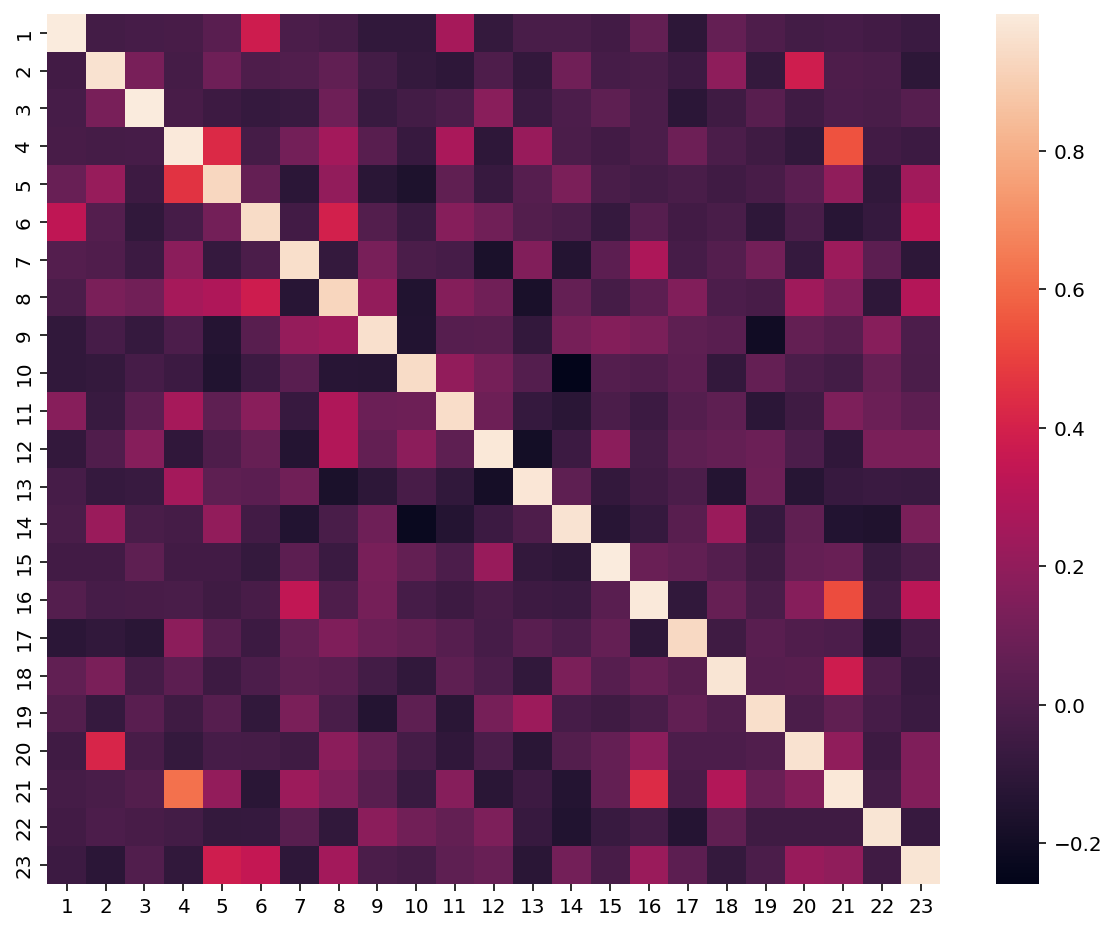

In [37]:
res = {i:{} for i in range(1,24)}

for pla_i in range(1,24):
    for pla_j in range(1,24):
   
        
        common_wells = set(retest_df[(retest_df.retest_pla == pla_i)&(~retest_df.xp1.isnull())&(~retest_df.xp2.isnull())].retest_pos)&set(retest_df[(retest_df.retest_pla == pla_j)&(~retest_df.xp1.isnull())&(~retest_df.xp2.isnull())].retest_pos)
        
        a = retest_df[(retest_df.retest_pla == pla_i)&(retest_df.retest_pos.isin(common_wells))].xp1
        b = retest_df[(retest_df.retest_pla == pla_j)&(retest_df.retest_pos.isin(common_wells))].xp2
        
        pearson_corr = pearsonr(a, b)
        #print(pla_i,pla_j,pearson_corr)
        
        res[pla_i][pla_j] = pearson_corr[0]

plt.figure(figsize=(10,8))
sns.heatmap(pd.DataFrame(res));

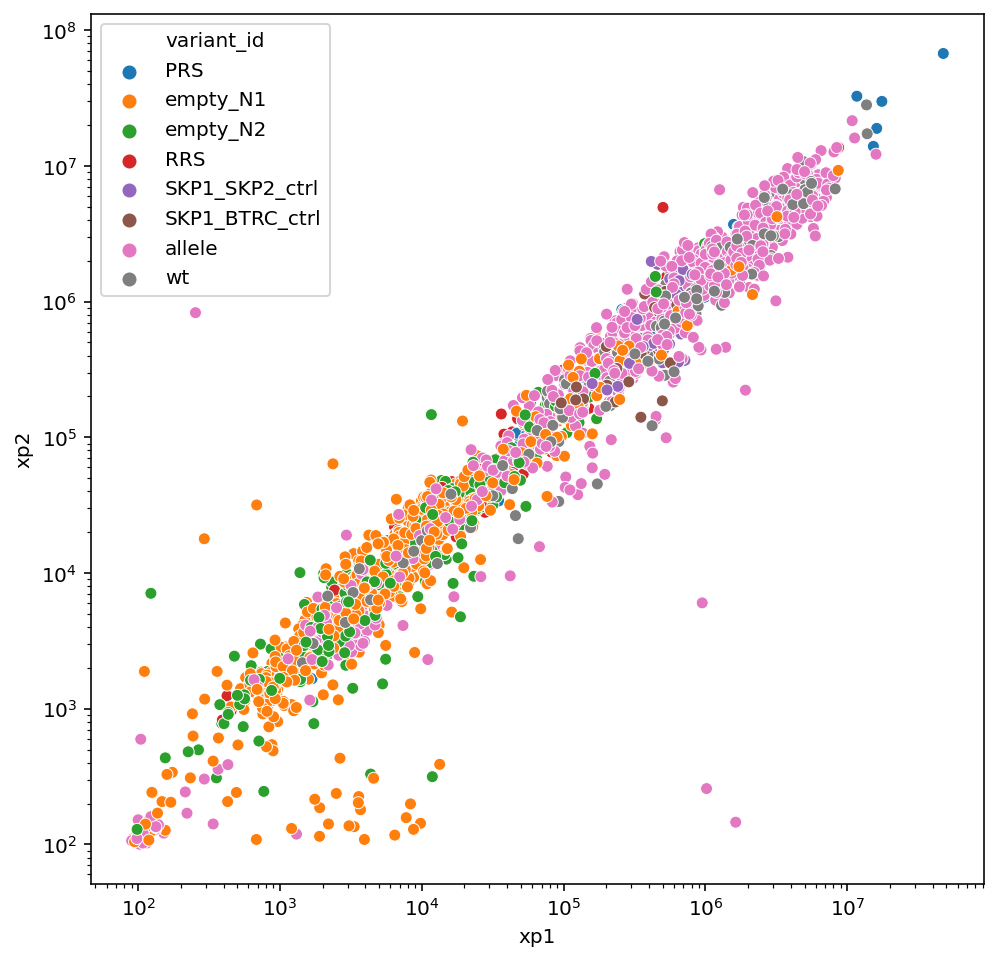

In [45]:
plt.figure(figsize=(8,8))
sns.scatterplot(data=retest_df, x='xp1',y='xp2',hue='variant_id');
plt.xscale('log')
plt.yscale('log')

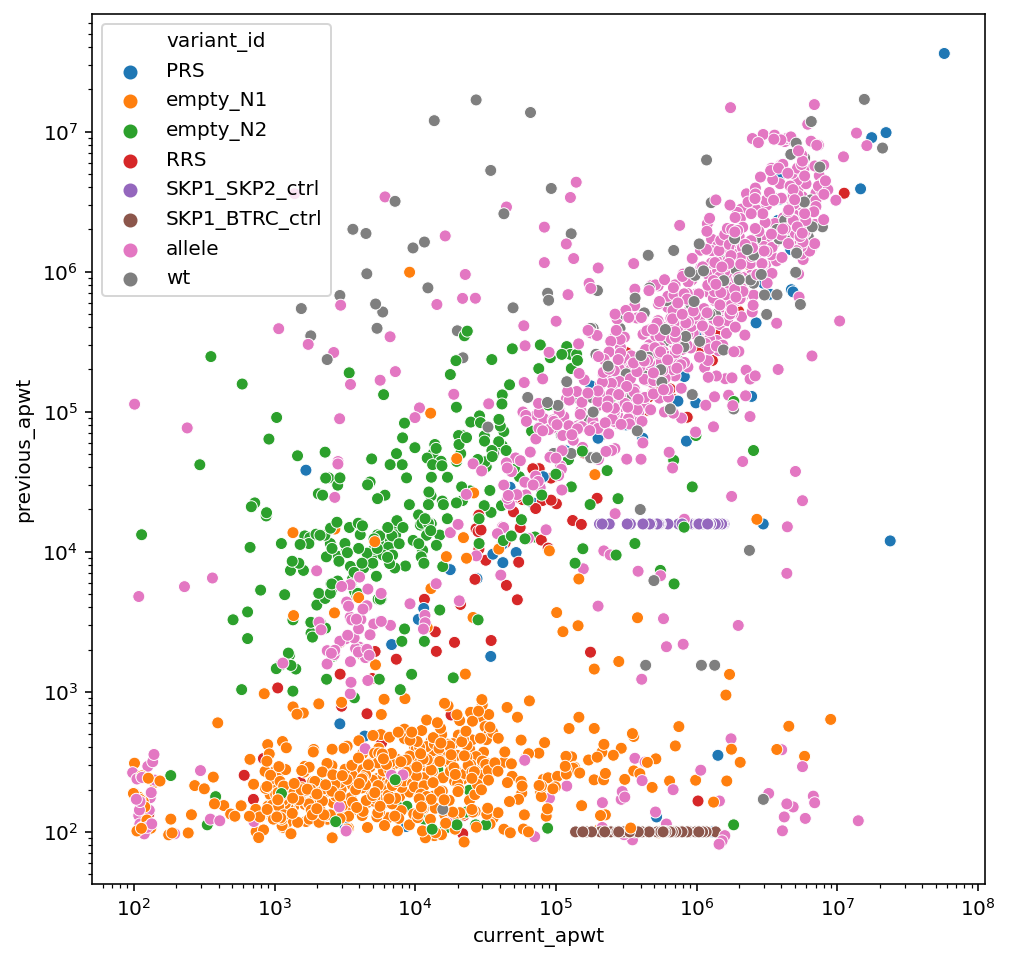

In [39]:
df = retest_df.copy()
df['current_apwt'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(retest_df.xp1, retest_df.xp2)]

plt.figure(figsize=(8,8))
sns.scatterplot(data=df, x='current_apwt',y='previous_apwt',hue='variant_id');
plt.xscale('log')
plt.yscale('log')

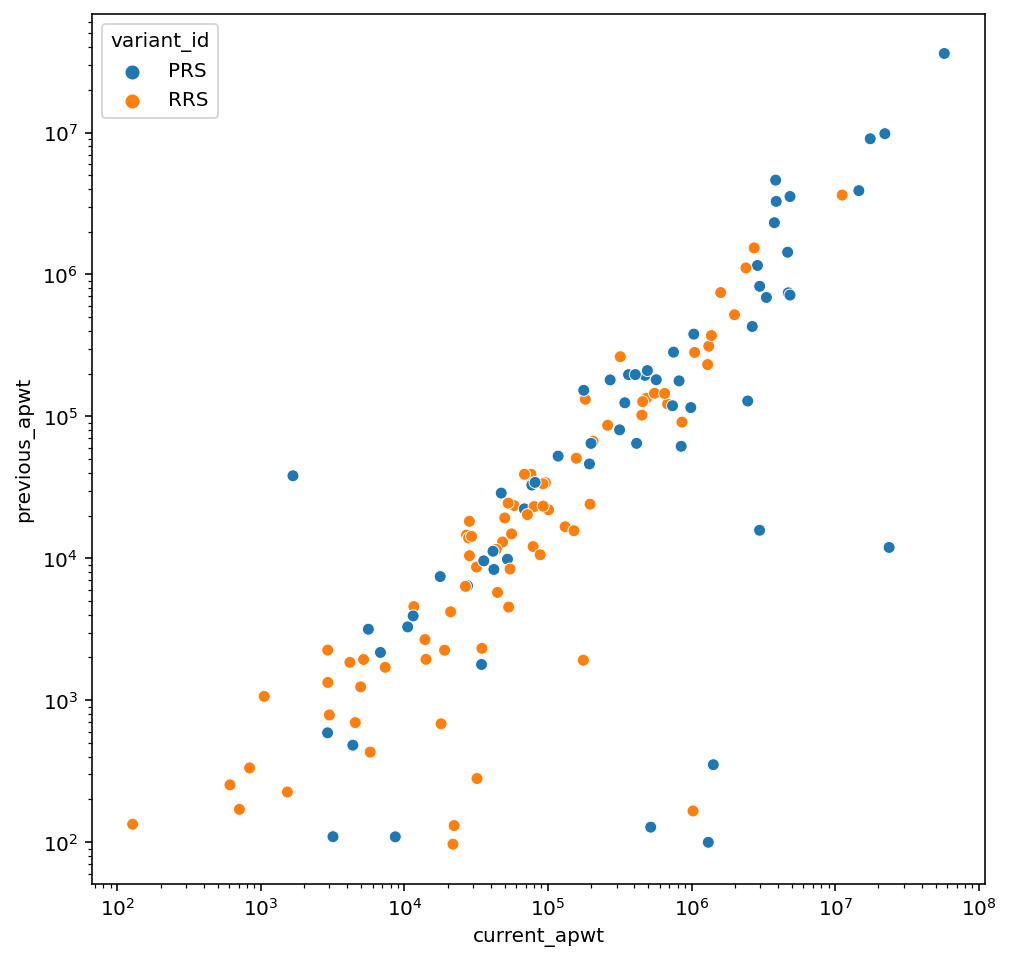

In [40]:
df = retest_df[retest_df.variant_id.isin(['PRS','RRS'])].copy()
df['current_apwt'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(df.xp1, df.xp2)]

plt.figure(figsize=(8,8))
sns.scatterplot(data=df, x='current_apwt',y='previous_apwt',hue='variant_id');
plt.xscale('log')
plt.yscale('log')

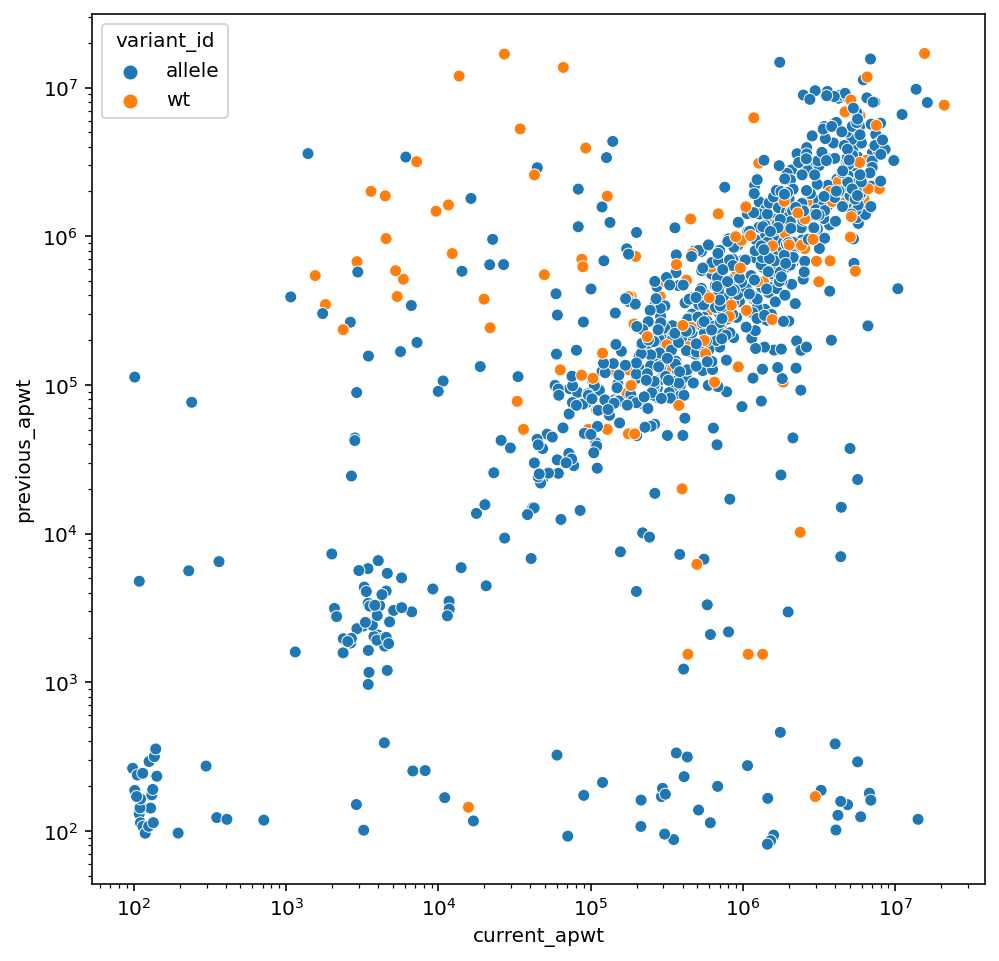

In [41]:
df = retest_df[retest_df.variant_id.isin(['allele','wt'])].copy()
df['current_apwt'] = [np.mean([xp1, xp2]) for xp1, xp2 in zip(df.xp1, df.xp2)]

plt.figure(figsize=(8,8))
sns.scatterplot(data=df, x='current_apwt',y='previous_apwt',hue='variant_id');
plt.xscale('log')
plt.yscale('log')

In [42]:
for variant_id in df.variant_id.unique():
   
    a = df[(df.variant_id == variant_id)&(~df.current_apwt.isnull())&(~df.previous_apwt.isnull())].current_apwt
    b = df[(df.variant_id == variant_id)&(~df.current_apwt.isnull())&(~df.previous_apwt.isnull())].previous_apwt

    print(variant_id, pearsonr(a, b))


allele (0.6318812612365085, 6.1646127568929546e-93)
wt (0.46946932176439093, 1.5441484434808517e-09)


#### NLR

In [43]:
empty_N1_xp1_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp1))
empty_N2_xp1_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp1))

empty_N1_xp2_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp2))
empty_N2_xp2_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp2))

normalized_df = retest_df[retest_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp1'] = normalized_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp2'] = normalized_df.N1_orf_id.map(empty_N2_xp2_d)

normalized_df['NLR_xp1'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_df.xp1, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['NLR_xp2'] = [np.log2(N1N2/max([N1F2,N2F1])) for N1N2, N1F2, N2F1 in zip(normalized_df.xp2, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

df = normalized_df[normalized_df.variant_id == 'RRS']
normalized_df['zNLR1'] = normalized_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
normalized_df['zNLR2'] = normalized_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

normalized_df['NLR'] = normalized_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)

df = normalized_df[normalized_df.variant_id=='wt']
wt_apwt_d = {(n1,n2):(NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR)for n1,n2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR in zip(df.N1_orf_id, df.N2_orf_id, df.NLR_xp1, df.NLR_xp2, df.zNLR1, df.zNLR2, df.NLR)}

normalized_df['wt_NLR1'] = [wt_apwt_d[n1,n2][0] if (n1,n2) in wt_apwt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_NLR2'] = [wt_apwt_d[n1,n2][1] if (n1,n2) in wt_apwt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_zNLR1'] = [wt_apwt_d[n1,n2][2] if (n1,n2) in wt_apwt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_zNLR2'] = [wt_apwt_d[n1,n2][3] if (n1,n2) in wt_apwt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_NLR'] = [wt_apwt_d[n1,n2][4] if (n1,n2) in wt_apwt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]

normalized_df['wt_wtNLR1'] = [wt_d[n1,n2][0] if (n1,n2) in wt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_wtNLR2'] = [wt_d[n1,n2][1] if (n1,n2) in wt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_wtzNLR1'] = [wt_d[n1,n2][2] if (n1,n2) in wt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_wtzNLR2'] = [wt_d[n1,n2][3] if (n1,n2) in wt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]
normalized_df['wt_wtNLR'] = [wt_d[n1,n2][4] if (n1,n2) in wt_d else np.nan for n1,n2 in zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id)]

normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0,133281.333333,60561.000000,2.079707e+05,91601.333333,4.102489,4.141402,1.153835,1.187649,4.121945,NaN,NaN,NaN,NaN,NaN,1.219380,2.628899,0.143275,0.643760,1.924139
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0,11384.000000,1559.666667,1.692433e+04,2437.666667,2.002585,2.056176,0.265261,0.311324,2.029380,NaN,NaN,NaN,NaN,NaN,1.852303,0.454815,0.357259,-0.115040,1.153559
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,940280.0,1239510.0,1195485.0,1243182.0,1562153.0,1720736,False,False,1.125092e+06,1.508690e+06,312382.75,736787.0,785866.0,711784.0,779007.0,761326.5,745395.5,5364.0,7114.0,7810.0,59592.666667,65487.333333,1.110043e+05,89346.000000,4.102683,3.764609,1.153917,1.029300,3.933646,NaN,NaN,NaN,NaN,NaN,4.922181,4.355798,1.395148,1.246484,4.638989
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,398751.0,255745.0,319855.0,607223.0,653894.0,667575,False,False,3.247837e+05,6.428973e+05,134203.25,265521.0,280607.0,176930.0,185692.0,273064.0,181311.0,3745.0,6518.0,6973.0,840605.666667,445242.333333,1.126690e+06,928918.000000,-1.371950,-0.809430,-1.162673,-0.892959,-1.090690,NaN,NaN,NaN,NaN,NaN,3.840468,2.762205,1.029433,0.690287,3.301336
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,450691.0,496890.0,592130.0,719638.0,874757.0,944897,False,False,5.132370e+05,8.464307e+05,122400.50,208386.0,264372.0,244423.0,256875.0,236379.0,250649.0,21407.0,23227.0,39366.0,27121.333333,64519.000000,5.824200e+04,77501.666667,2.991829,3.449093,0.683860,0.896703,3.220461,NaN,NaN,NaN,NaN,NaN,2.119291,2.391552,0.447524,0.560921,2.255421


In [44]:
df = normalized_df[normalized_df.variant_id=='wt']

wt_apwt_d = {(n1,n2):(NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR)for n1,n2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR in zip(df.N1_orf_id, df.N2_orf_id, df.NLR_xp1, df.NLR_xp2, df.zNLR1, df.zNLR2, df.NLR)}

## Analysis

### Signal difference between F1 and F2

In [47]:
normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0,133281.333333,60561.000000,2.079707e+05,91601.333333,4.102489,4.141402,1.153835,1.187649,4.121945,NaN,NaN,NaN,NaN,NaN,1.219380,2.628899,0.143275,0.643760,1.924139
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0,11384.000000,1559.666667,1.692433e+04,2437.666667,2.002585,2.056176,0.265261,0.311324,2.029380,NaN,NaN,NaN,NaN,NaN,1.852303,0.454815,0.357259,-0.115040,1.153559
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,940280.0,1239510.0,1195485.0,1243182.0,1562153.0,1720736,False,False,1.125092e+06,1.508690e+06,312382.75,736787.0,785866.0,711784.0,779007.0,761326.5,745395.5,5364.0,7114.0,7810.0,59592.666667,65487.333333,1.110043e+05,89346.000000,4.102683,3.764609,1.153917,1.029300,3.933646,NaN,NaN,NaN,NaN,NaN,4.922181,4.355798,1.395148,1.246484,4.638989
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,398751.0,255745.0,319855.0,607223.0,653894.0,667575,False,False,3.247837e+05,6.428973e+05,134203.25,265521.0,280607.0,176930.0,185692.0,273064.0,181311.0,3745.0,6518.0,6973.0,840605.666667,445242.333333,1.126690e+06,928918.000000,-1.371950,-0.809430,-1.162673,-0.892959,-1.090690,NaN,NaN,NaN,NaN,NaN,3.840468,2.762205,1.029433,0.690287,3.301336
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,450691.0,496890.0,592130.0,719638.0,874757.0,944897,False,False,5.132370e+05,8.464307e+05,122400.50,208386.0,264372.0,244423.0,256875.0,236379.0,250649.0,21407.0,23227.0,39366.0,27121.333333,64519.000000,5.824200e+04,77501.666667,2.991829,3.449093,0.683860,0.896703,3.220461,NaN,NaN,NaN,NaN,NaN,2.119291,2.391552,0.447524,0.560921,2.255421


In [49]:
(normalized_df.empty_N1_xp1 > normalized_df.empty_N2_xp1).sum()/len((normalized_df.empty_N1_xp1 > normalized_df.empty_N2_xp1))

0.4959713518352731

In [50]:
(normalized_df.empty_N1_xp2 > normalized_df.empty_N2_xp2).sum()/len((normalized_df.empty_N1_xp2 > normalized_df.empty_N2_xp2))

0.5559534467323187

### QCs controls

In [51]:
df[df.retest_pla == 5]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
433,1198,TNFSF14,9634,CLDN19,0,wt,5,B08,mN2Hapwtv2,330386.0,618023.0,750713.0,844713.0,972927.0,1034747,False,False,5.663740e+05,9.507957e+05,228624.25,614382.0,640675.0,587636.0,571161.0,627528.5,579398.5,NaN,NaN,NaN,7272.0,6506.333333,14767.333333,8318.000000,6.283259,6.008654,2.076628,1.972370,6.145957,6.283259,6.008654,2.076628,1.972370,6.145957,6.562137,6.417978,1.949597,1.966227,6.490057
443,2758,TMEM106C,9634,CLDN19,0,wt,5,D09,mN2Hapwtv2,552219.0,1140947.0,1425908.0,1826611.0,1930153.0,2113574,False,False,1.039691e+06,1.956779e+06,706881.50,1170433.0,1369369.0,867021.0,291402.0,1269901.0,579211.5,NaN,NaN,NaN,7272.0,9376.000000,14767.333333,6695.000000,6.792967,7.049928,2.292311,2.409970,6.921447,6.792967,7.049928,2.292311,2.409970,6.921447,6.312892,5.008743,1.865330,1.474375,5.660817
447,7201,RAD51D,13571,XRCC2,0,wt,5,H09,mN2Hapwtv2,269174.0,848447.0,948919.0,1020440.0,1218615.0,1285279,False,False,6.888467e+05,1.174778e+06,410850.00,1036116.0,1137546.0,705595.0,758204.0,1086831.0,731899.5,NaN,NaN,NaN,2081.5,1393.500000,4992.000000,2703.666667,8.370416,7.878555,2.959808,2.758204,8.124485,8.370416,7.878555,2.959808,2.758204,8.124485,NaN,NaN,NaN,NaN,NaN
448,9955,FCGR1A,9634,CLDN19,0,wt,5,A10,mN2Hapwtv2,234206.0,590374.0,752500.0,1258139.0,1413726.0,1333707,False,False,5.256933e+05,1.335191e+06,132249.25,482853.0,629622.0,526977.0,510515.0,556237.5,518746.0,NaN,NaN,NaN,7272.0,1489.000000,14767.333333,5864.000000,6.175725,6.498493,2.031125,2.178227,6.337109,6.175725,6.498493,2.031125,2.178227,6.337109,6.859682,7.332944,2.050193,2.285569,7.096313
452,7408,TM4SF18,9634,CLDN19,0,wt,5,E10,mN2Hapwtv2,NaN,14264.0,14153.0,23216.0,28527.0,25144,False,False,1.420850e+04,2.562900e+04,377593.25,1086834.0,1110480.0,534560.0,546944.0,1098657.0,540752.0,NaN,NaN,NaN,7272.0,155.333333,14767.333333,434.000000,0.966330,0.795368,-0.173230,-0.218536,0.880849,0.966330,0.795368,-0.173230,-0.218536,0.880849,6.897854,5.572615,2.063099,1.671178,6.235235
456,147,PVR,9634,CLDN19,0,wt,5,A11,mN2Hapwtv2,557223.0,1506111.0,1714430.0,2572332.0,2828760.0,2509506,False,False,1.259255e+06,2.636866e+06,921321.75,1345471.0,1541792.0,1174504.0,1356309.0,1443631.5,1265406.5,NaN,NaN,NaN,7272.0,7816.500000,14767.333333,11048.333333,7.331832,7.480271,2.520331,2.590824,7.406051,7.331832,7.480271,2.520331,2.590824,7.406051,6.189006,6.436748,1.823446,1.972778,6.312877
459,56141,KRT31,55855,KRT2,0,wt,5,E11,mN2Hapwtv2,NaN,103444.0,118187.0,255567.0,287963.0,307403,False,False,1.108155e+05,2.836443e+05,731543.50,1171200.0,1599798.0,2415371.0,1804009.0,1385499.0,2109690.0,NaN,NaN,NaN,8183.0,874.000000,30207.666667,1363.333333,3.759386,3.231096,1.008651,0.805090,3.495241,3.759386,3.231096,1.008651,0.805090,3.495241,5.568318,7.569353,1.613599,2.368081,6.568836
466,2838,TMEM248,9634,CLDN19,0,wt,5,D12,mN2Hapwtv2,NaN,108608.0,137872.0,200306.0,237110.0,229275,False,False,1.232400e+05,2.222303e+05,87298.25,250625.0,279533.0,185354.0,206747.0,265079.0,196050.5,NaN,NaN,NaN,7272.0,4271.666667,14767.333333,10035.333333,4.082975,3.911575,1.145578,1.091063,3.997275,4.082975,3.911575,1.145578,1.091063,3.997275,6.334385,5.753126,1.872597,1.734180,6.043756


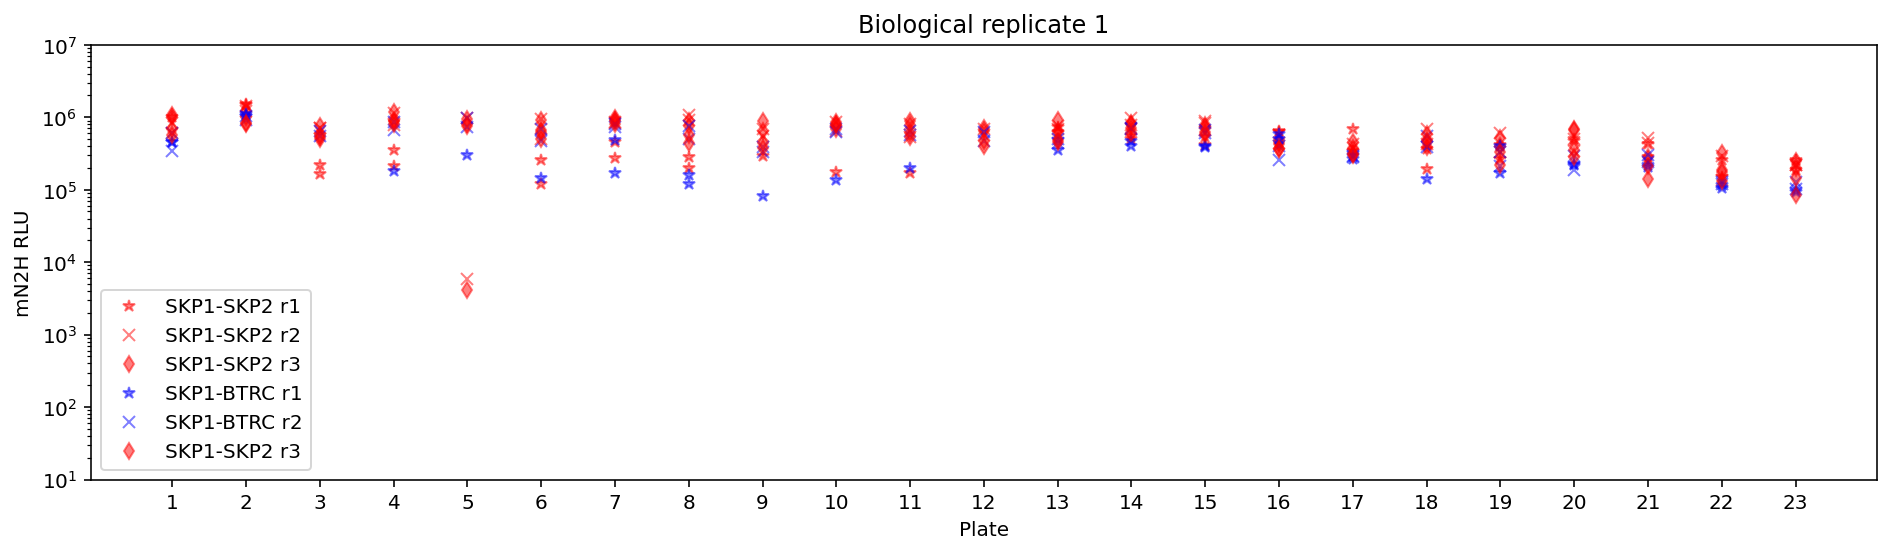

In [53]:
plt.figure(figsize=(16,4))

df = retest_df[retest_df.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r1.tolist(), '*', color='r', label='SKP1-SKP2 r1', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r2.tolist(), 'x', color='r', label='SKP1-SKP2 r2', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r3.tolist(), 'd', color='r', label='SKP1-SKP2 r3', alpha=0.5)

df = retest_df[retest_df.variant_id.isin(['SKP1_BTRC_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r1.tolist(), '*', color='b', label='SKP1-BTRC r1', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r2.tolist(), 'x', color='b', label='SKP1-BTRC r2', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r3.tolist(), 'd', color='r', label='SKP1-SKP2 r3', alpha=0.5)

plt.title('Biological replicate 1')
plt.xlabel('Plate')

plt.xticks([i for i in range(1,24)])

plt.ylim( (10**1,10**7) )
plt.yscale('log')

plt.ylabel('mN2H RLU')
#plt.ylim((0,2000000))
plt.legend()
#plt.savefig('control_plate.pdf')

plt.show()

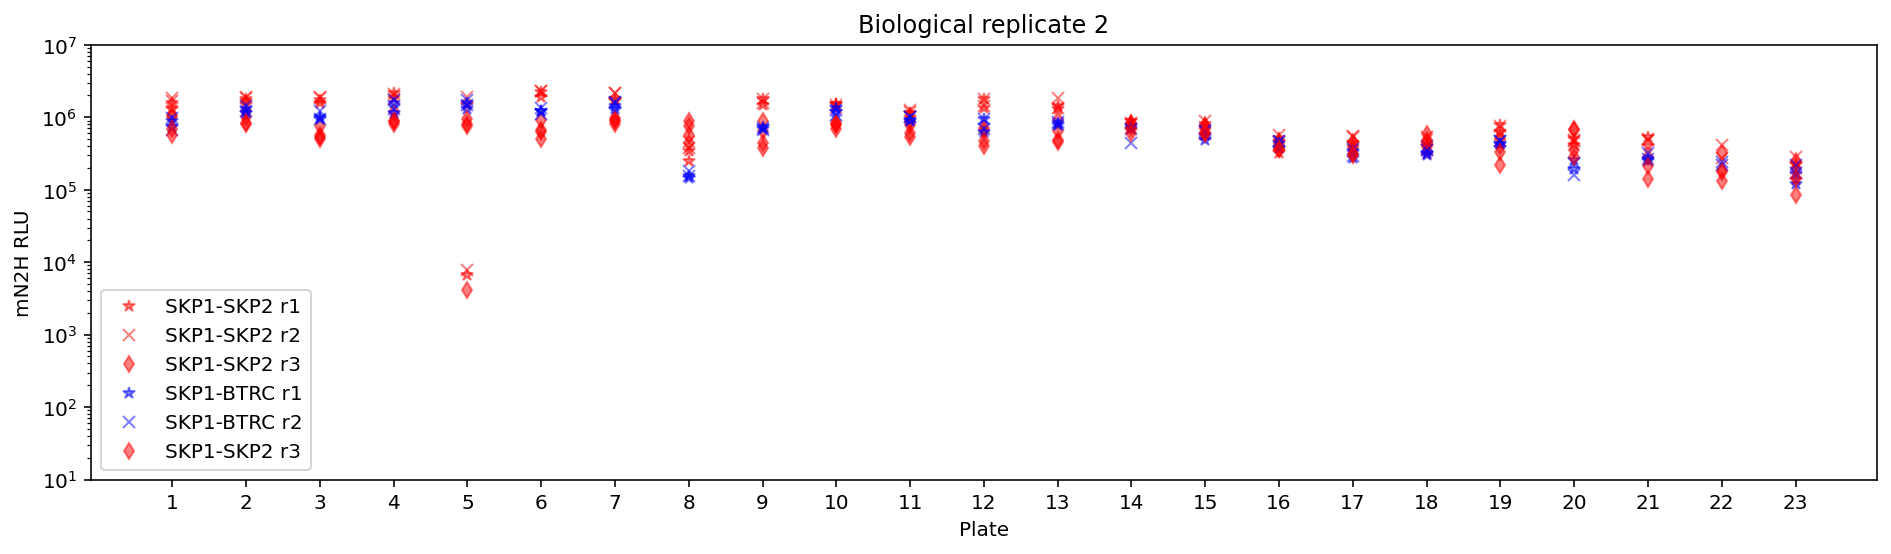

In [55]:
plt.figure(figsize=(16,4))

df = retest_df[retest_df.variant_id.isin(['SKP1_SKP2_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r1.tolist(), '*', color='r', label='SKP1-SKP2 r1', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r2.tolist(), 'x', color='r', label='SKP1-SKP2 r2', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r3.tolist(), 'd', color='r', label='SKP1-SKP2 r3', alpha=0.5)
# plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r1.tolist(), 'ro', color='pink', label='SKP1_SKP2_ctrl')
# plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r2.tolist(), 'ro', color='pink')

df = retest_df[retest_df.variant_id.isin(['SKP1_BTRC_ctrl'])]
plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r1.tolist(), '*', color='b', label='SKP1-BTRC r1', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r2.tolist(), 'x', color='b', label='SKP1-BTRC r2', alpha=0.5)
plt.plot(df.retest_pla.tolist(), df.mN2H_xp1r3.tolist(), 'd', color='r', label='SKP1-SKP2 r3', alpha=0.5)
# plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r1.tolist(), 'ro', color='deepskyblue', label='SKP1_BTRC_ctrl')
# plt.plot(df.retest_pla.tolist(), df.mN2H_xp2r2.tolist(), 'ro', color='deepskyblue')

plt.title('Biological replicate 2')
plt.xlabel('Plate')

plt.xticks([i for i in range(1,24)])

plt.ylim( (10**1,10**7) )
plt.yscale('log')

plt.ylabel('mN2H RLU')
#plt.ylim((0,2000000))
plt.legend()
#plt.savefig('control_plate.pdf')

plt.show()

### PRS-RRS distribution

In [56]:
normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.NLR > 5)]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
147,2003,SLC6A1,6773,TM4SF4,0,RRS,2,G07,mN2Hapwtv2,9879410.0,11304182.0,4907101.0,13603147.0,13354327.0,14057515,False,False,8.696898e+06,13671663.0,3625491.75,3902859.0,4709312.0,3612083.0,2721275.0,4306085.5,3166679.0,1217909.0,2099059.0,2520342.0,135747.333333,64191.666667,238657.333333,70065.666667,6.001505,5.840104,1.957404,1.901536,5.920805,NaN,NaN,NaN,NaN,NaN,6.652825,5.879382,1.980257,1.778246,6.266103
244,6905,ITPA,7773,WDR62,0,RRS,3,B08,mN2Hapwtv2,192778.0,759653.0,633073.0,1331588.0,1546489.0,1671762,False,False,5.285013e+05,1516613.0,165.75,877815.0,884324.0,528119.0,565439.0,881069.5,546779.0,48543.0,50375.0,61210.0,15502.000000,8776.666667,43609.666667,19507.333333,5.091381,5.120061,1.572285,1.598935,5.105721,NaN,NaN,NaN,NaN,NaN,4.751893,4.479045,1.337575,1.289499,4.615469
402,3409,PBX2,3375,VILL,0,RRS,5,C04,mN2Hapwtv2,291162.0,819637.0,1065386.0,1210958.0,1351243.0,1560366,False,False,7.253950e+05,1374189.0,282214.50,98998.0,126249.0,425491.0,539797.0,112623.5,482644.0,116184.0,177323.0,370436.0,12891.000000,1397.000000,26769.000000,3180.666667,5.814331,5.681873,1.878201,1.835039,5.748102,NaN,NaN,NaN,NaN,NaN,1.121208,4.155580,0.110085,1.176603,2.638394
426,3341,CKB,8297,HBZ,0,RRS,5,C07,mN2Hapwtv2,NaN,1838100.0,2345820.0,1569908.0,1881615.0,2207353,False,False,2.091960e+06,1886292.0,519907.75,129.0,141.0,123.0,129.0,135.0,126.0,202129.0,240569.0,572397.0,1888.000000,225.333333,2834.666667,481.000000,10.113781,9.378158,3.697513,3.388419,9.745969,NaN,NaN,NaN,NaN,NaN,-9.962253,-9.441248,-3.637099,-3.568971,-9.701751


In [57]:
4/77

0.05194805194805195

Text(0.5, 0, 'NLR (log2)')

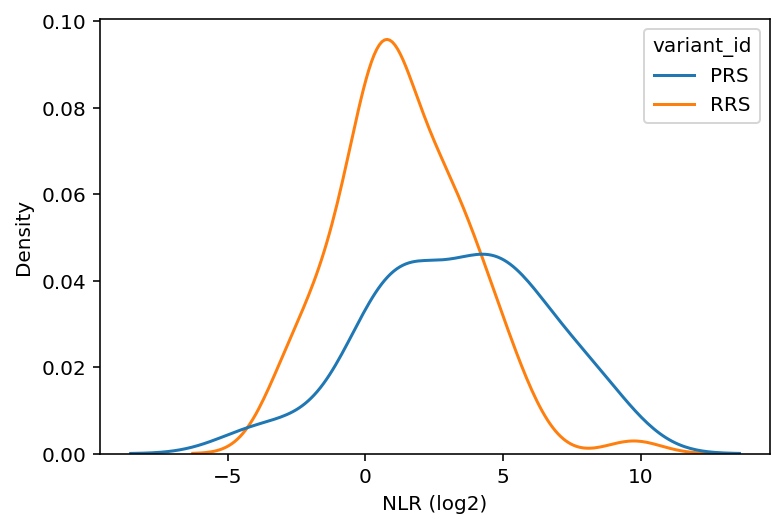

In [58]:
sns.kdeplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])],x='NLR',hue='variant_id');
plt.xlabel('NLR (log2)')

Text(0.5, 0, 'Z-score')

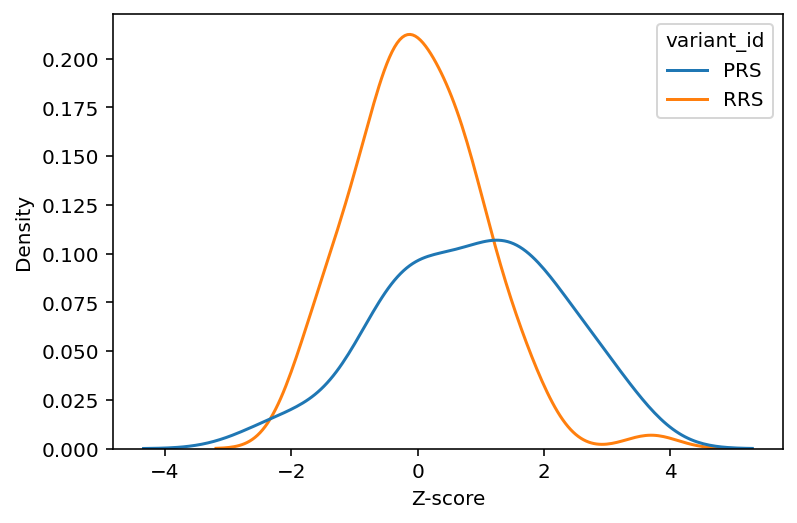

In [59]:
sns.kdeplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])],x='zNLR1',hue='variant_id');
plt.xlabel('Z-score')

In [60]:
normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.NLR_xp1 > 9)]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
426,3341,CKB,8297,HBZ,0,RRS,5,C07,mN2Hapwtv2,NaN,1838100.0,2345820.0,1569908.0,1881615.0,2207353,False,False,2091960.0,1886292.0,519907.75,129.0,141.0,123.0,129.0,135.0,126.0,202129.0,240569.0,572397.0,1888.0,225.333333,2834.666667,481.0,10.113781,9.378158,3.697513,3.388419,9.745969,NaN,NaN,NaN,NaN,NaN,-9.962253,-9.441248,-3.637099,-3.568971,-9.701751


In [61]:
normalized_df[normalized_df.variant_id == 'RRS'].NLR_xp1.max()

10.113780786292244

In [62]:
normalized_df[normalized_df.variant_id == 'RRS'].NLR_xp2.max()

9.378158212535704

In [63]:
sorted(normalized_df[normalized_df.variant_id == 'RRS'].NLR_xp1.tolist())[-4]

5.091380848523896

In [64]:
sorted(normalized_df[normalized_df.variant_id == 'RRS'].NLR_xp2.tolist())[-4]

5.681873383860583

In [65]:
normalized_df[(normalized_df.variant_id == 'RRS')&(normalized_df.NLR_xp1 > 8)]

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
426,3341,CKB,8297,HBZ,0,RRS,5,C07,mN2Hapwtv2,NaN,1838100.0,2345820.0,1569908.0,1881615.0,2207353,False,False,2091960.0,1886292.0,519907.75,129.0,141.0,123.0,129.0,135.0,126.0,202129.0,240569.0,572397.0,1888.0,225.333333,2834.666667,481.0,10.113781,9.378158,3.697513,3.388419,9.745969,NaN,NaN,NaN,NaN,NaN,-9.962253,-9.441248,-3.637099,-3.568971,-9.701751


### Correlation plots

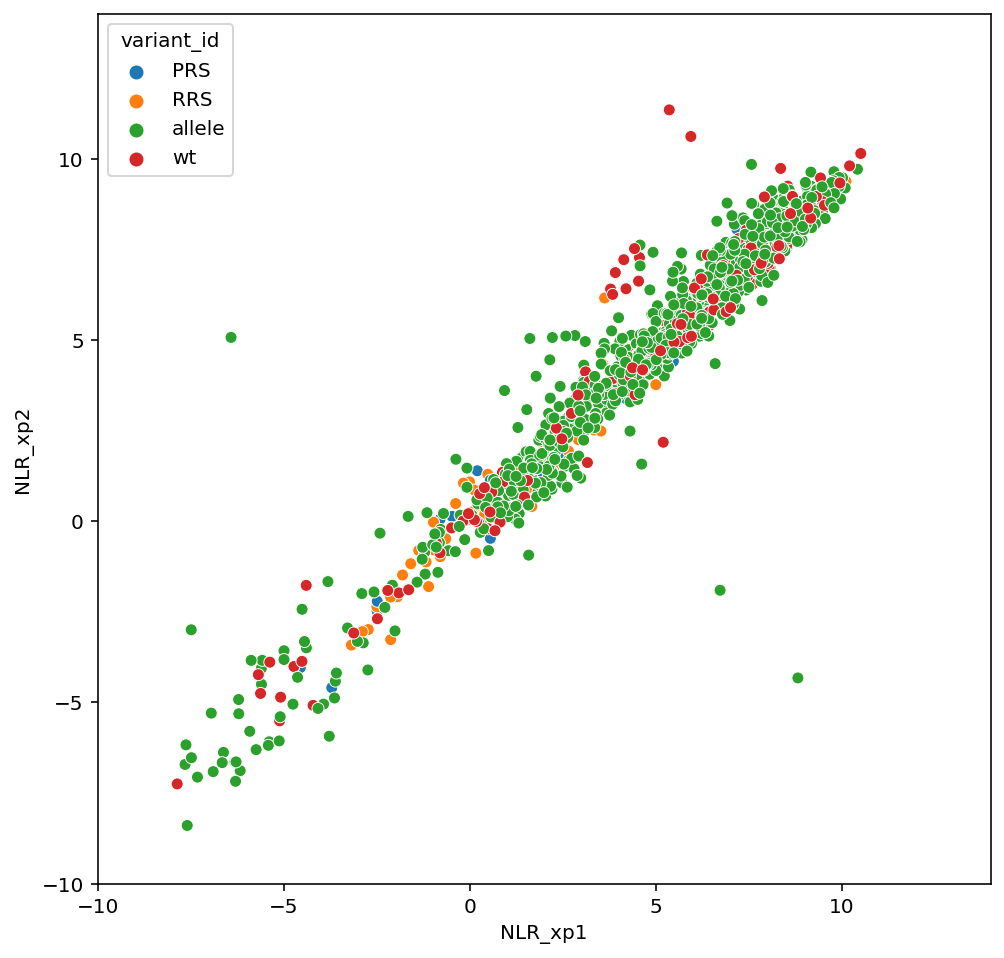

In [66]:
plt.figure(figsize=(8,8))
sns.scatterplot(data=normalized_df, x='NLR_xp1',y='NLR_xp2',hue='variant_id');
plt.xlim(-10,14);
plt.ylim(-10,14);

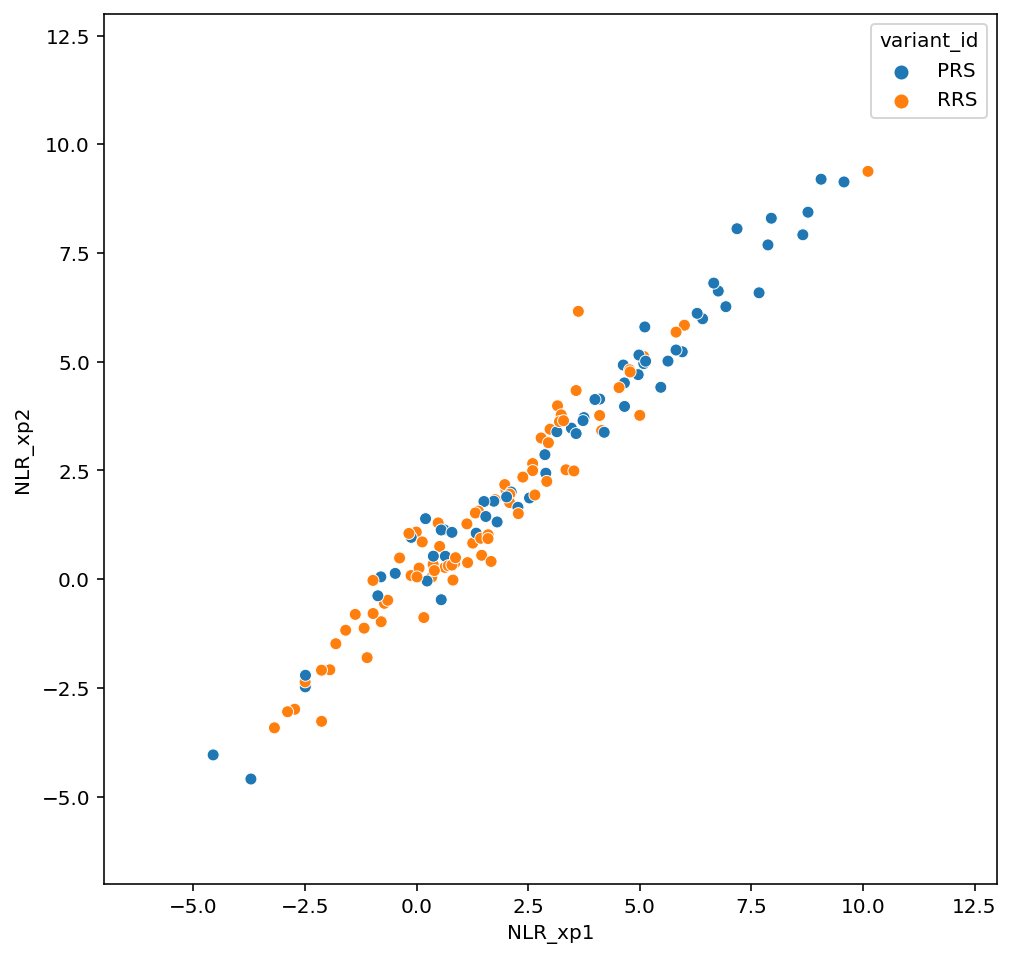

In [67]:
plt.figure(figsize=(8,8))
sns.scatterplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])], x='NLR_xp1',y='NLR_xp2',hue='variant_id');
plt.xlim(-7,13);
plt.ylim(-7,13);

### Raw data correlations

In [68]:
retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,159608.0,102775.0,137461.0,186214.0,208374.0,229324,False,False,1.332813e+05,2.079707e+05,325.25,20545.0,21331.0,15983.0,16701.0,20938.0,16342.0,373.0,427.0,345.0
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,72620.0,89714.0,54138.0,87449.0,113606.0,116952,False,False,7.215733e+04,1.060023e+05,77064.25,84213.0,88493.0,28595.0,22338.0,86353.0,25466.5,383567.0,978929.0,911115.0
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,11537.0,9880.0,12735.0,15277.0,16560.0,18936,False,False,1.138400e+04,1.692433e+04,242.50,9603.0,11230.0,7626.0,8793.0,10416.5,8209.5,243.0,354.0,314.0


In [69]:
retest_df.variant_id.value_counts()

allele            830
empty_N1          590
empty_N2          286
wt                149
RRS                78
PRS                60
SKP1_SKP2_ctrl     46
SKP1_BTRC_ctrl     46
Name: variant_id, dtype: int64

#### Empty controls

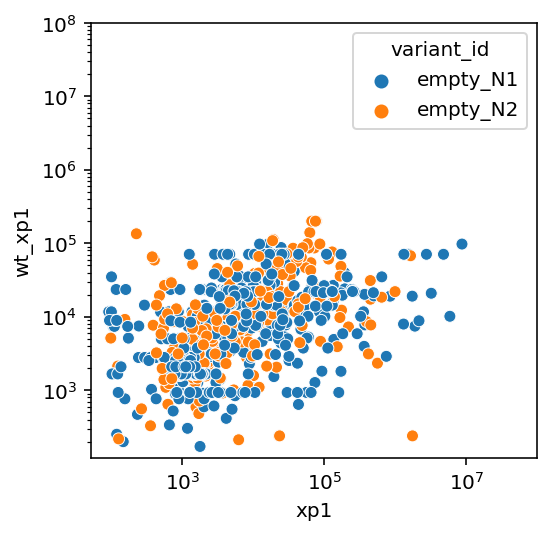

In [70]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['empty_N1','empty_N2'])], x='xp1',y='wt_xp1', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8));

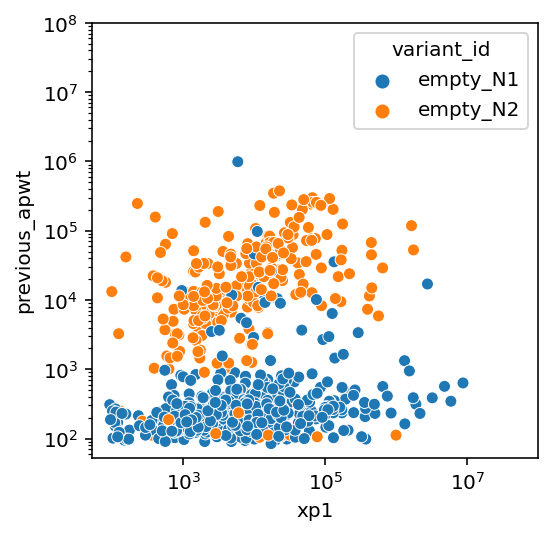

In [71]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['empty_N1','empty_N2'])], x='xp1',y='previous_apwt', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8));

(59.11460000376067, 100000000)

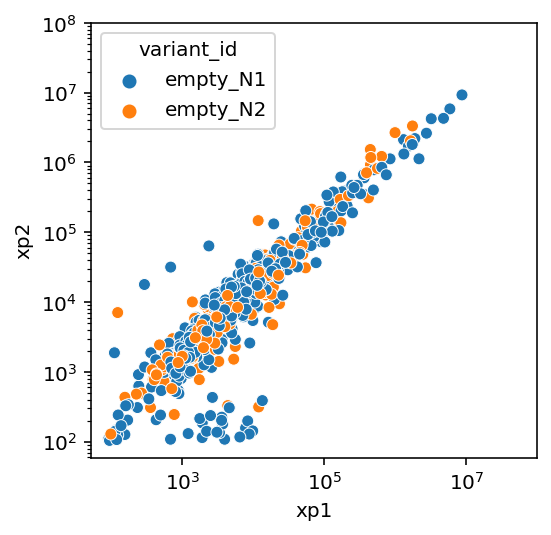

In [72]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['empty_N1','empty_N2'])], x='xp1',y='xp2', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8))

(52.89815979209853, 100000000)

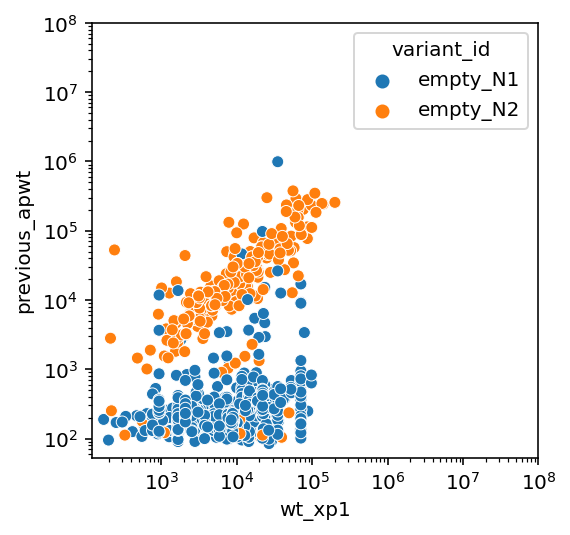

In [73]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['empty_N1','empty_N2'])], x='wt_xp1',y='previous_apwt', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8))

In [74]:
retest_df[(retest_df.variant_id == 'empty_N1')].N1_orf_id.value_counts(dropna=False)

0    590
Name: N1_orf_id, dtype: int64

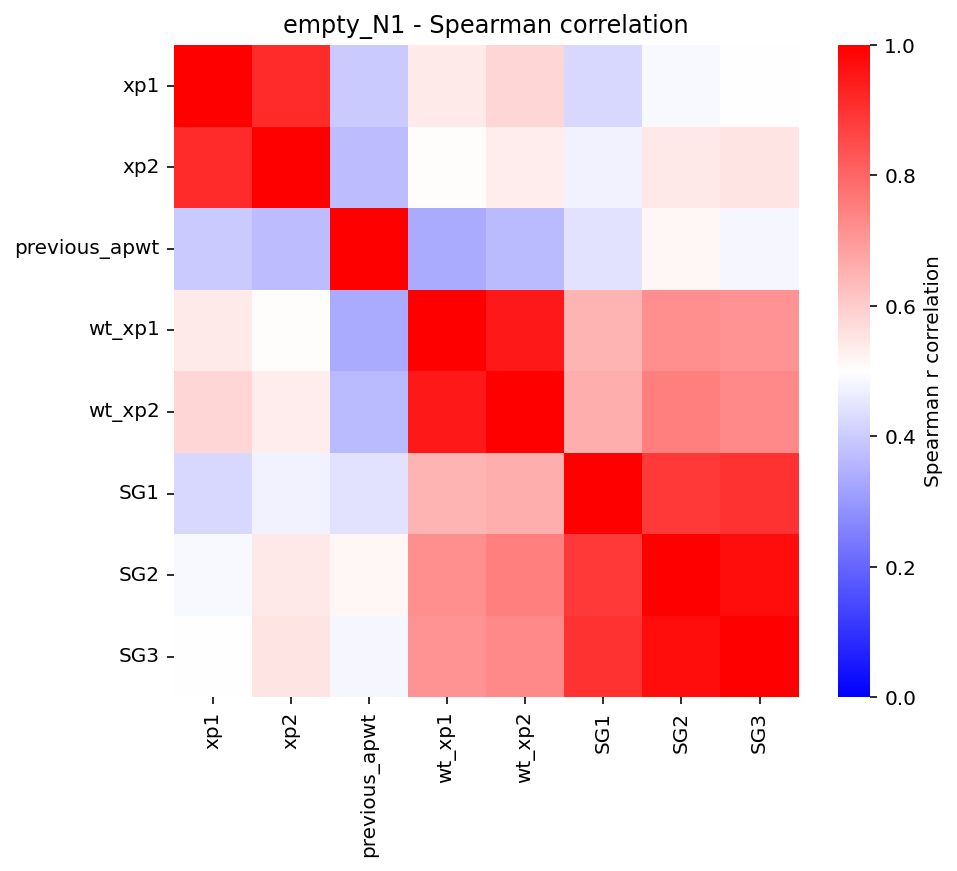

In [75]:
variant_id = 'empty_N1'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']}

for xp1 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
    for xp2 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

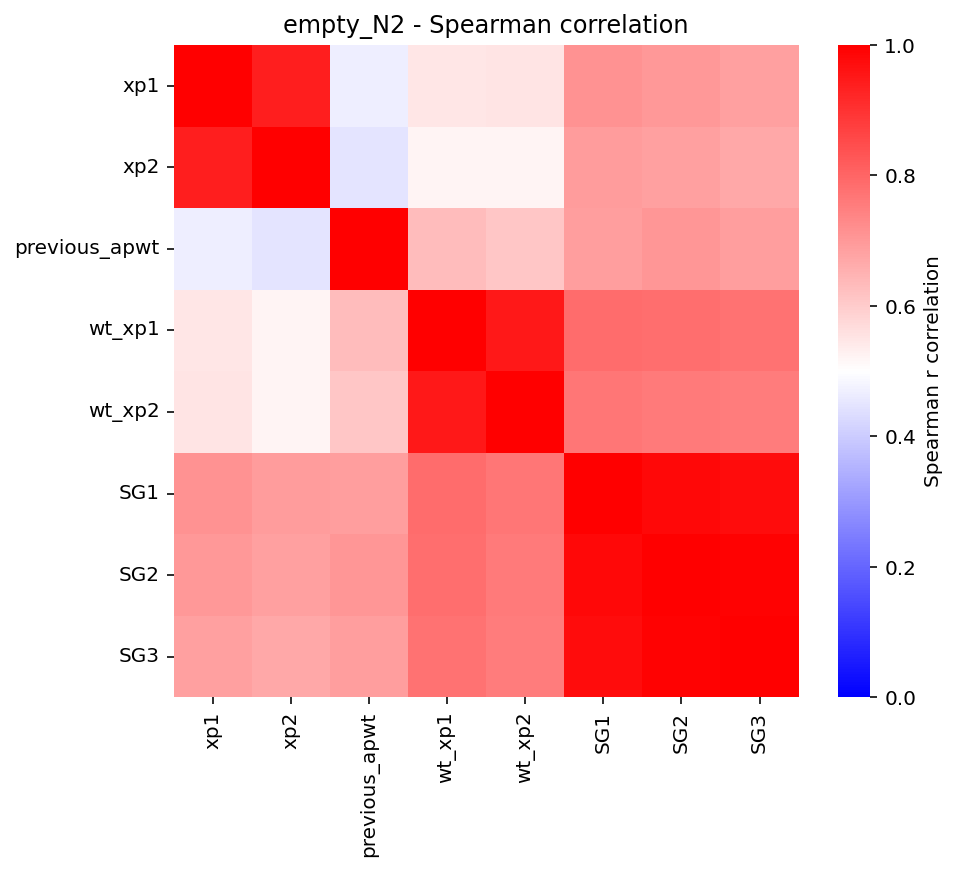

In [76]:
variant_id = 'empty_N2'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']}

for xp1 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
    for xp2 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

In [110]:
retest_df[retest_df.variant_id == 'empty_N2'].SG1

2       383567.0
5        14678.0
8       499710.0
11       25356.0
14       34787.0
17       46439.0
22      383567.0
25         283.0
28      149535.0
31       12054.0
34       43524.0
37       32355.0
40       34977.0
43       43376.0
46        4587.0
49        2761.0
52      293526.0
55        9455.0
58       10844.0
61       69274.0
64      190253.0
67      192900.0
70        3514.0
73       12207.0
78       21141.0
81        1085.0
84        6745.0
87       82783.0
90       37924.0
93         797.0
96         179.0
99        5389.0
102        401.0
105       3186.0
108      23951.0
111       3104.0
116      18308.0
119     194627.0
122     225923.0
125     329180.0
128       4687.0
131     226415.0
134       8188.0
137     190372.0
140      30064.0
143      10772.0
146       3402.0
149     297067.0
152      24598.0
155      14468.0
158     154737.0
161     338803.0
164      61900.0
169       6520.0
172      11601.0
175     145948.0
178      52973.0
181       5882.0
184      24512

##### PRS-RRS

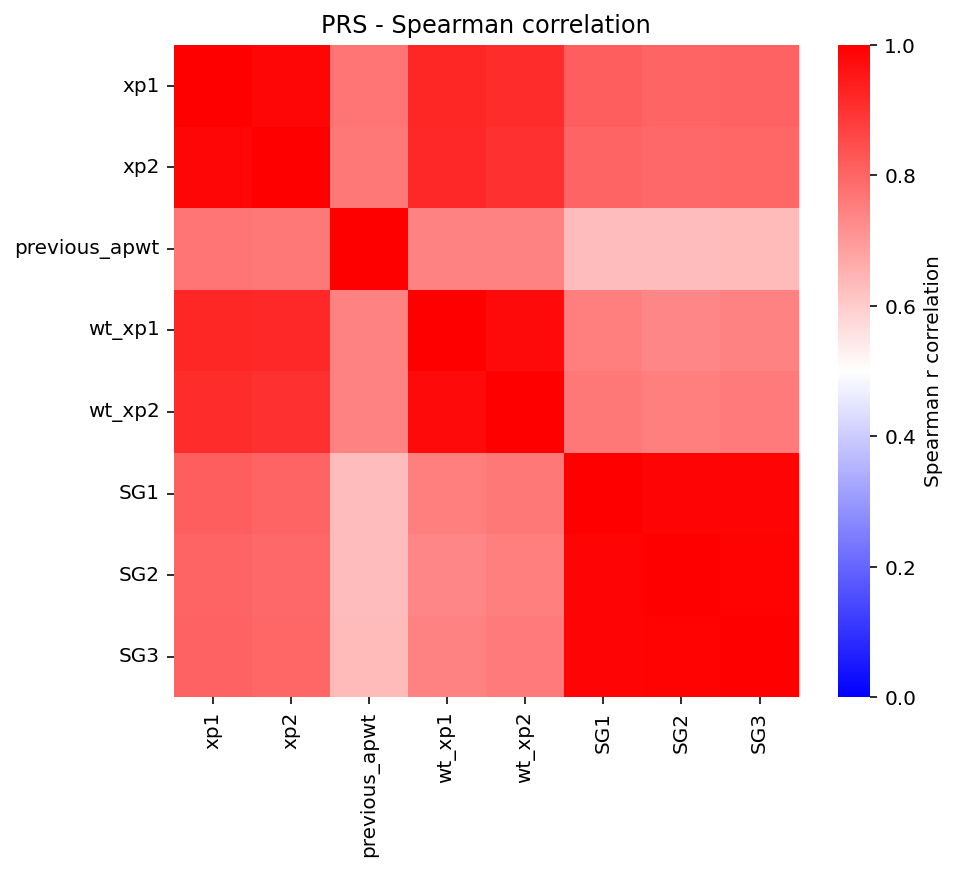

In [77]:
variant_id = 'PRS'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']}

for xp1 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
    for xp2 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

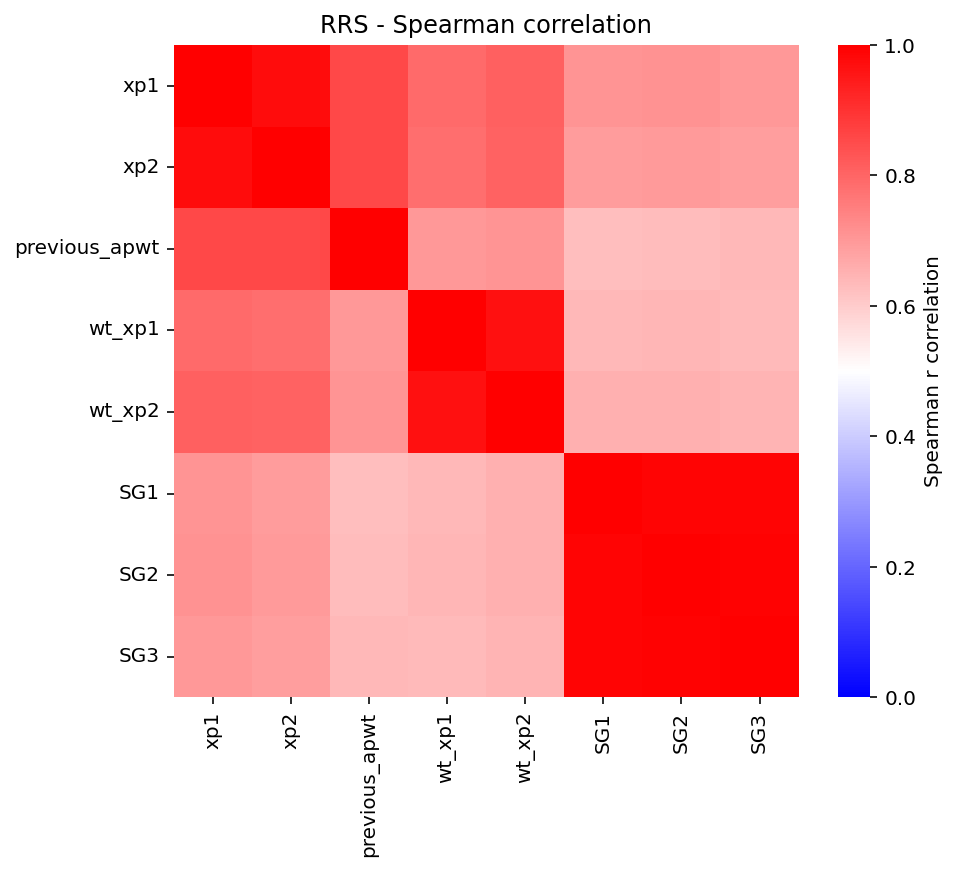

In [78]:
variant_id = 'RRS'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']}

for xp1 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
    for xp2 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2','SG1','SG2','SG3']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

(50.941832043011566, 100000000)

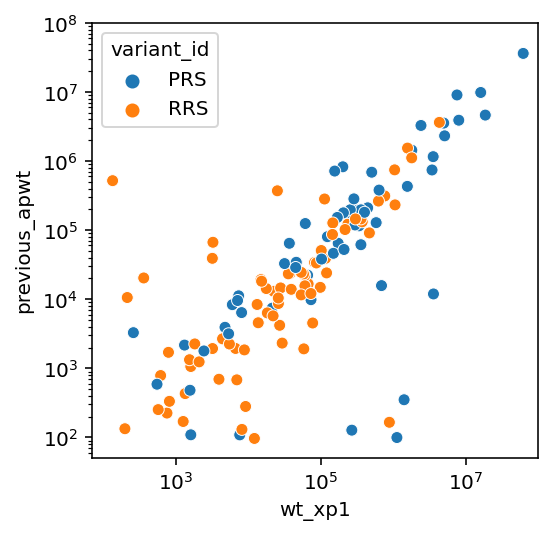

In [79]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['PRS','RRS'])], x='wt_xp1',y='previous_apwt', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8))

(62.25440241736464, 100000000)

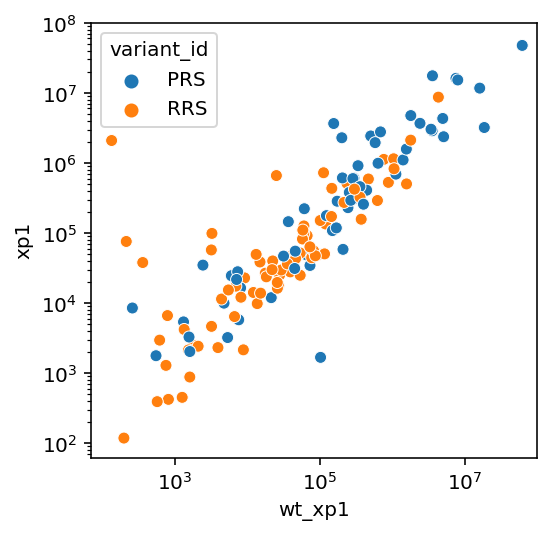

In [80]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['PRS','RRS'])], x='wt_xp1',y='xp1', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8))

(62.25440241736464, 100000000)

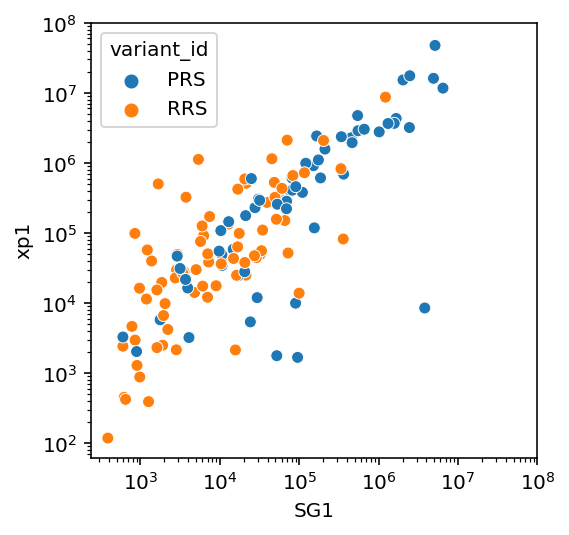

In [81]:
plt.figure(figsize=(4,4))
sns.scatterplot(data=retest_df[retest_df.variant_id.isin(['PRS','RRS'])], x='SG1',y='xp1', hue='variant_id');
plt.xscale('log')
plt.yscale('log')
plt.xlim((0,10**8))
plt.ylim((0,10**8))

##### WT pairs

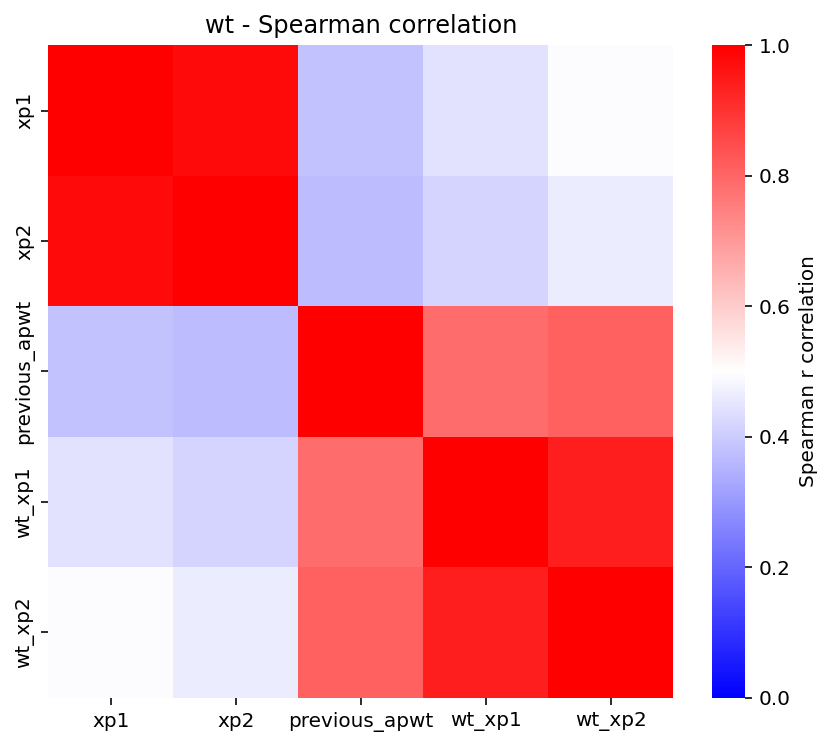

In [82]:
variant_id = 'wt'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2']}

for xp1 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2']:
    for xp2 in ['xp1','xp2','previous_apwt','wt_xp1','wt_xp2']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

##### Allele pairs

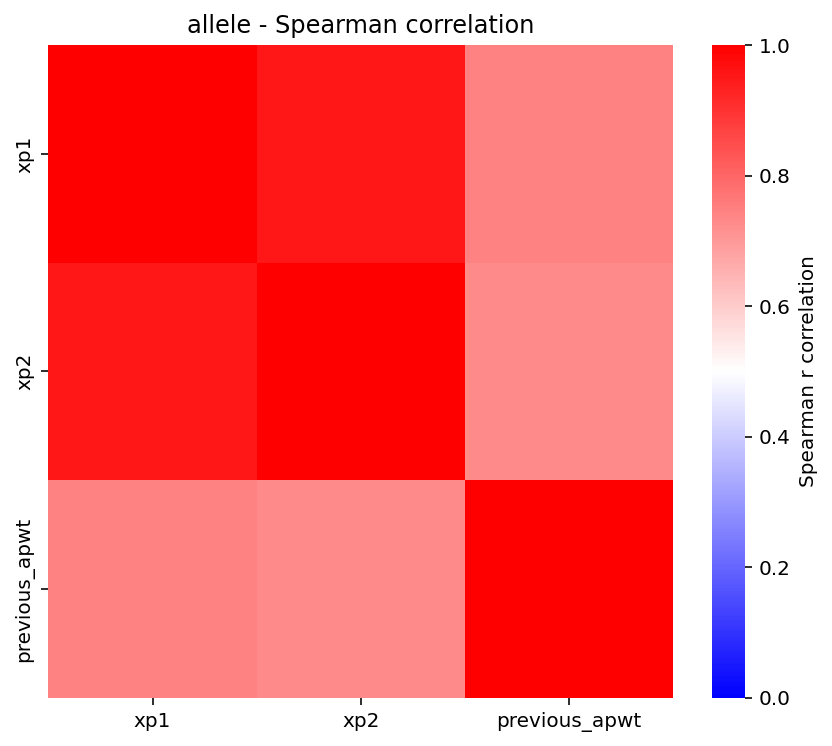

In [83]:
variant_id = 'allele'

res = {xp:{} for xp in ['xp1','xp2','previous_apwt']}

for xp1 in ['xp1','xp2','previous_apwt']:
    for xp2 in ['xp1','xp2','previous_apwt']:
        a = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp1]
        b = retest_df[(retest_df.variant_id.isin([variant_id]))&(~retest_df[xp1].isnull())&(~retest_df[xp2].isnull())][xp2]
        
        spearman_corr = spearmanr(a, b)
        res[xp1][xp2] = spearman_corr[0]

        
plt.figure(figsize=(7,6))
plt.title(f'{variant_id} - Spearman correlation')
sns.heatmap(pd.DataFrame(res),cmap='bwr',vmin=0,vmax=1,cbar_kws={'label': 'Spearman r correlation'});
plt.show()

### N1 N2 empty controls

In [84]:
retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,159608.0,102775.0,137461.0,186214.0,208374.0,229324,False,False,1.332813e+05,2.079707e+05,325.25,20545.0,21331.0,15983.0,16701.0,20938.0,16342.0,373.0,427.0,345.0
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,72620.0,89714.0,54138.0,87449.0,113606.0,116952,False,False,7.215733e+04,1.060023e+05,77064.25,84213.0,88493.0,28595.0,22338.0,86353.0,25466.5,383567.0,978929.0,911115.0
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,11537.0,9880.0,12735.0,15277.0,16560.0,18936,False,False,1.138400e+04,1.692433e+04,242.50,9603.0,11230.0,7626.0,8793.0,10416.5,8209.5,243.0,354.0,314.0


### PRS-RRS analysis

#### Raw data

In [85]:
col = ['N1_orf_id', 'N1_symbol', 'N2_orf_id', 'N2_symbol', 'N2_mut_id',
       'variant_id', 'retest_pla', 'retest_pos', 'standard_batch',
       'mN2H_xp1r1', 'mN2H_xp1r2', 'mN2H_xp1r3', 'mN2H_xp2r1', 'mN2H_xp2r2',
       'mN2H_xp2r3', 'error1', 'error2', 'xp1', 'xp2', 'previous_apwt',
       'wt_xp1r1', 'wt_xp1r2', 'wt_xp2r1', 'wt_xp2r2', 'wt_xp1', 'wt_xp2',
       'SG1', 'SG2', 'SG3']

In [86]:
prs_rrs_raw = retest_df.copy()

prs_rrs_raw['APWT'] = [np.log10(np.mean([xp1,xp2])) for xp1, xp2 in zip(prs_rrs_raw.xp1, prs_rrs_raw.xp2)]
prs_rrs_raw['WT'] = [np.log10(np.mean([xp1,xp2])) for xp1, xp2 in zip(prs_rrs_raw.wt_xp1, prs_rrs_raw.wt_xp2)]
prs_rrs_raw['SG'] = [np.log10(np.mean([sg1,sg2,sg3])) for sg1,sg2,sg3 in zip(prs_rrs_raw.SG1, prs_rrs_raw.SG2, prs_rrs_raw.SG3)]
prs_rrs_raw['previous_apwt'] = prs_rrs_raw.previous_apwt.apply(np.log10)

prs_rrs_raw.drop(columns=['retest_pla', 'retest_pos', 'standard_batch',
       'mN2H_xp1r1', 'mN2H_xp1r2', 'mN2H_xp1r3', 'mN2H_xp2r1', 'mN2H_xp2r2',
       'mN2H_xp2r3', 'error1', 'error2', 'xp1', 'xp2',
       'wt_xp1r1', 'wt_xp1r2', 'wt_xp2r1', 'wt_xp2r2', 'wt_xp1', 'wt_xp2',
       'SG1', 'SG2', 'SG3'],inplace=True)

df = prs_rrs_raw[prs_rrs_raw.N2_mut_id == 0]
EF2_d = {n1:(APWT,previous_apwt,WT,SG) for n1,APWT,previous_apwt,WT,SG in zip(df[df.variant_id == 'empty_N2'].N1_orf_id, 
                                                                              df[df.variant_id == 'empty_N2'].APWT,
                                                                              df[df.variant_id == 'empty_N2'].previous_apwt,
                                                                              df[df.variant_id == 'empty_N2'].WT, 
                                                                              df[df.variant_id == 'empty_N2'].SG)}

EF1_d = {n2:(APWT,previous_apwt,WT,SG) for n2,APWT,previous_apwt,WT,SG in zip(df[df.variant_id == 'empty_N1'].N2_orf_id, 
                                                                              df[df.variant_id == 'empty_N1'].APWT, 
                                                                              df[df.variant_id == 'empty_N1'].previous_apwt,
                                                                              df[df.variant_id == 'empty_N1'].WT, 
                                                                              df[df.variant_id == 'empty_N1'].SG)}

prs_rrs_raw = prs_rrs_raw[prs_rrs_raw.variant_id.isin(['PRS','RRS'])].copy()
prs_rrs_raw.rename(columns={'previous_apwt':'APWT1', 'APWT':'APWT2'}, inplace=True)

prs_rrs_raw['APWT1_F1'] = prs_rrs_raw.N2_orf_id.apply(lambda x: EF1_d[x][1])
prs_rrs_raw['APWT1_F2'] = prs_rrs_raw.N1_orf_id.apply(lambda x: EF2_d[x][1])

prs_rrs_raw['APWT2_F1'] = prs_rrs_raw.N2_orf_id.apply(lambda x: EF1_d[x][0])
prs_rrs_raw['APWT2_F2'] = prs_rrs_raw.N1_orf_id.apply(lambda x: EF2_d[x][0])

prs_rrs_raw['WT_F1'] = prs_rrs_raw.N2_orf_id.apply(lambda x: EF1_d[x][2])
prs_rrs_raw['WT_F2'] = prs_rrs_raw.N1_orf_id.apply(lambda x: EF2_d[x][2])

prs_rrs_raw['SG_F1'] = prs_rrs_raw.N2_orf_id.apply(lambda x: EF1_d[x][3])
prs_rrs_raw['SG_F2'] = prs_rrs_raw.N1_orf_id.apply(lambda x: EF2_d[x][3])

prs_rrs_raw['Category'] = prs_rrs_raw.variant_id.apply(lambda x: 2 if x == 'RRS' else 7)

prs_rrs_raw['pair'] = [tuple(sorted([n1,n2])) for n1, n2 in zip (prs_rrs_raw.N1_symbol, prs_rrs_raw.N2_symbol)]

prs_rrs_raw.sort_values(by='SG',inplace=True, ascending=False)

prs_rrs_raw.set_index('pair', inplace=True)

prs_rrs_raw.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,APWT1,APWT2,WT,SG,APWT1_F1,APWT1_F2,APWT2_F1,APWT2_F2,WT_F1,WT_F2,SG_F1,SG_F2,Category
pair,,,,,,,,,,,,,,,,,,,
"(PEX14, PEX19)",4964,PEX14,3171,PEX19,0,PRS,6.992089,7.346010,7.245092,6.987381,2.750508,5.306753,4.496448,4.877953,3.766134,4.811630,3.049476,5.869072,7
"(GRAP2, LCP2)",1108,LCP2,8327,GRAP2,0,PRS,6.956054,7.243976,6.912443,6.936540,4.550094,4.886853,5.276839,4.881277,4.189631,4.747488,2.630089,5.879595,7
"(BAD, BCL2L1)",3706,BAD,5989,BCL2L1,0,PRS,7.557179,7.759870,7.724723,6.917560,1.992333,5.384996,4.676044,4.959958,3.869349,5.119918,2.386796,5.514466,7
"(LMNA, LMNB1)",3903,LMNA,2370,LMNB1,0,PRS,3.516535,4.022146,2.549616,6.767269,2.275887,2.089905,3.319228,4.064152,2.220108,4.272833,2.488080,5.019062,7
"(PEX16, PEX19)",3171,PEX19,3837,PEX16,0,PRS,4.076540,7.375518,7.029180,6.643060,2.495891,5.408558,4.237120,5.041740,3.974581,5.114093,2.721536,5.716892,7


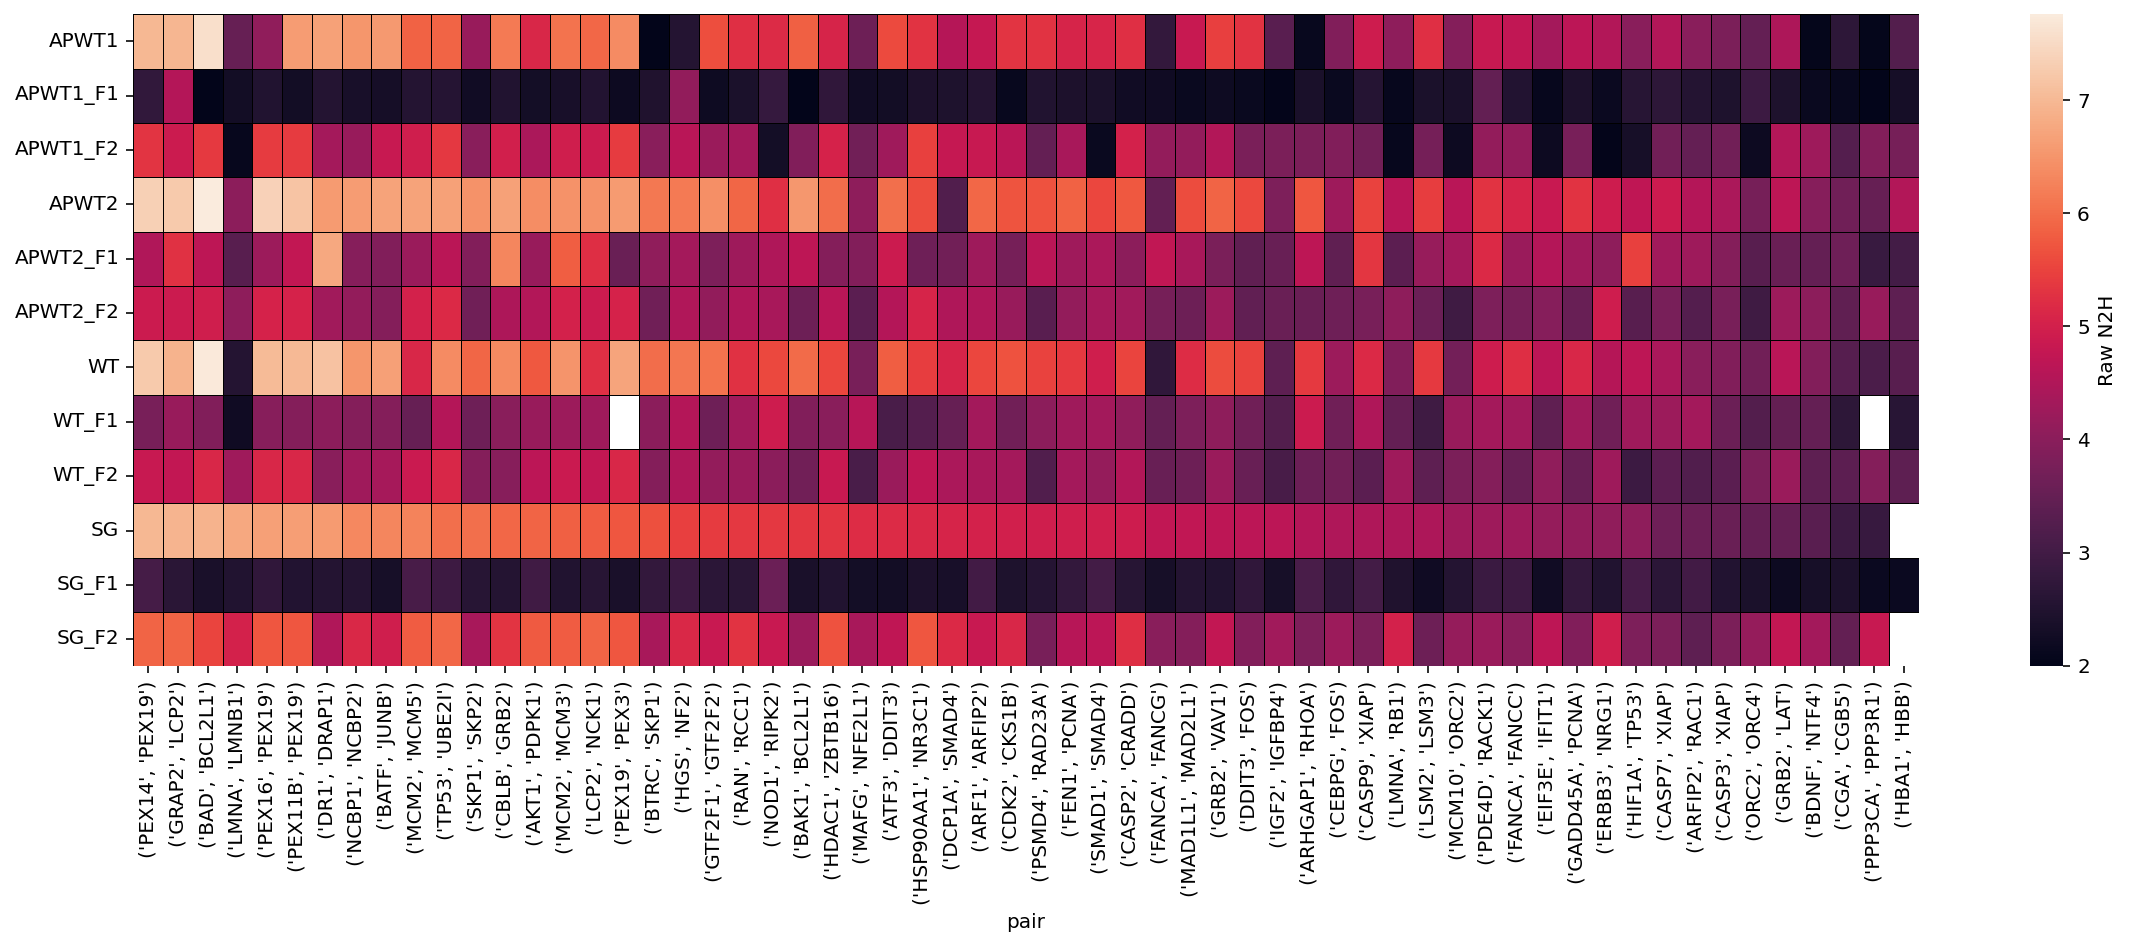

In [87]:
col = ['APWT1','APWT1_F1','APWT1_F2','APWT2','APWT2_F1','APWT2_F2','WT','WT_F1','WT_F2','SG','SG_F1','SG_F2']

plt.figure(figsize=(20,6))
ax = sns.heatmap(prs_rrs_raw[prs_rrs_raw.variant_id == 'PRS'][col].T, linewidths=.5, linecolor='black',cbar_kws={'label': 'Raw N2H'})

plt.yticks(rotation=0) 
plt.show()

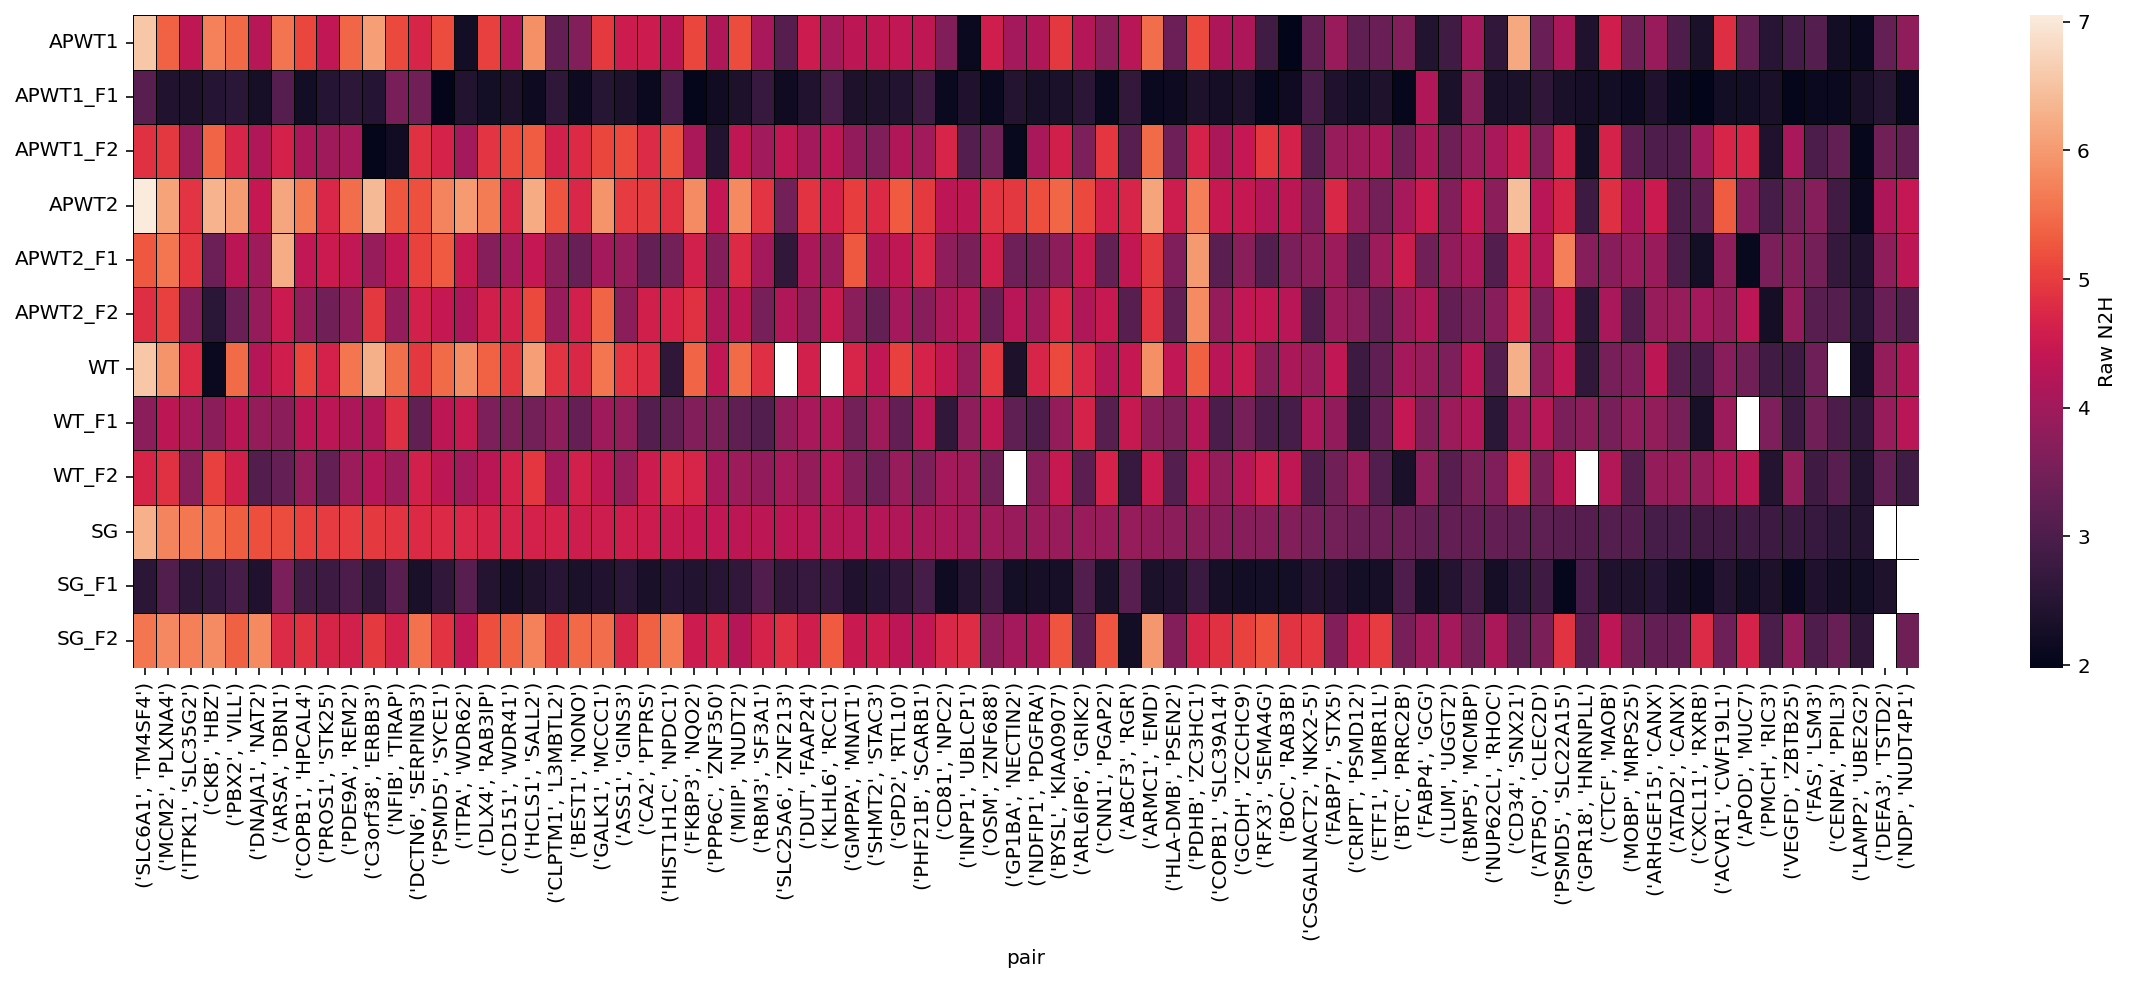

In [88]:
col = ['APWT1','APWT1_F1','APWT1_F2','APWT2','APWT2_F1','APWT2_F2','WT','WT_F1','WT_F2','SG','SG_F1','SG_F2']

plt.figure(figsize=(20,6))
ax = sns.heatmap(prs_rrs_raw[prs_rrs_raw.variant_id == 'RRS'][col].T, linewidths=.5, linecolor='black',cbar_kws={'label': 'Raw N2H'})

plt.yticks(rotation=0) 
plt.show()

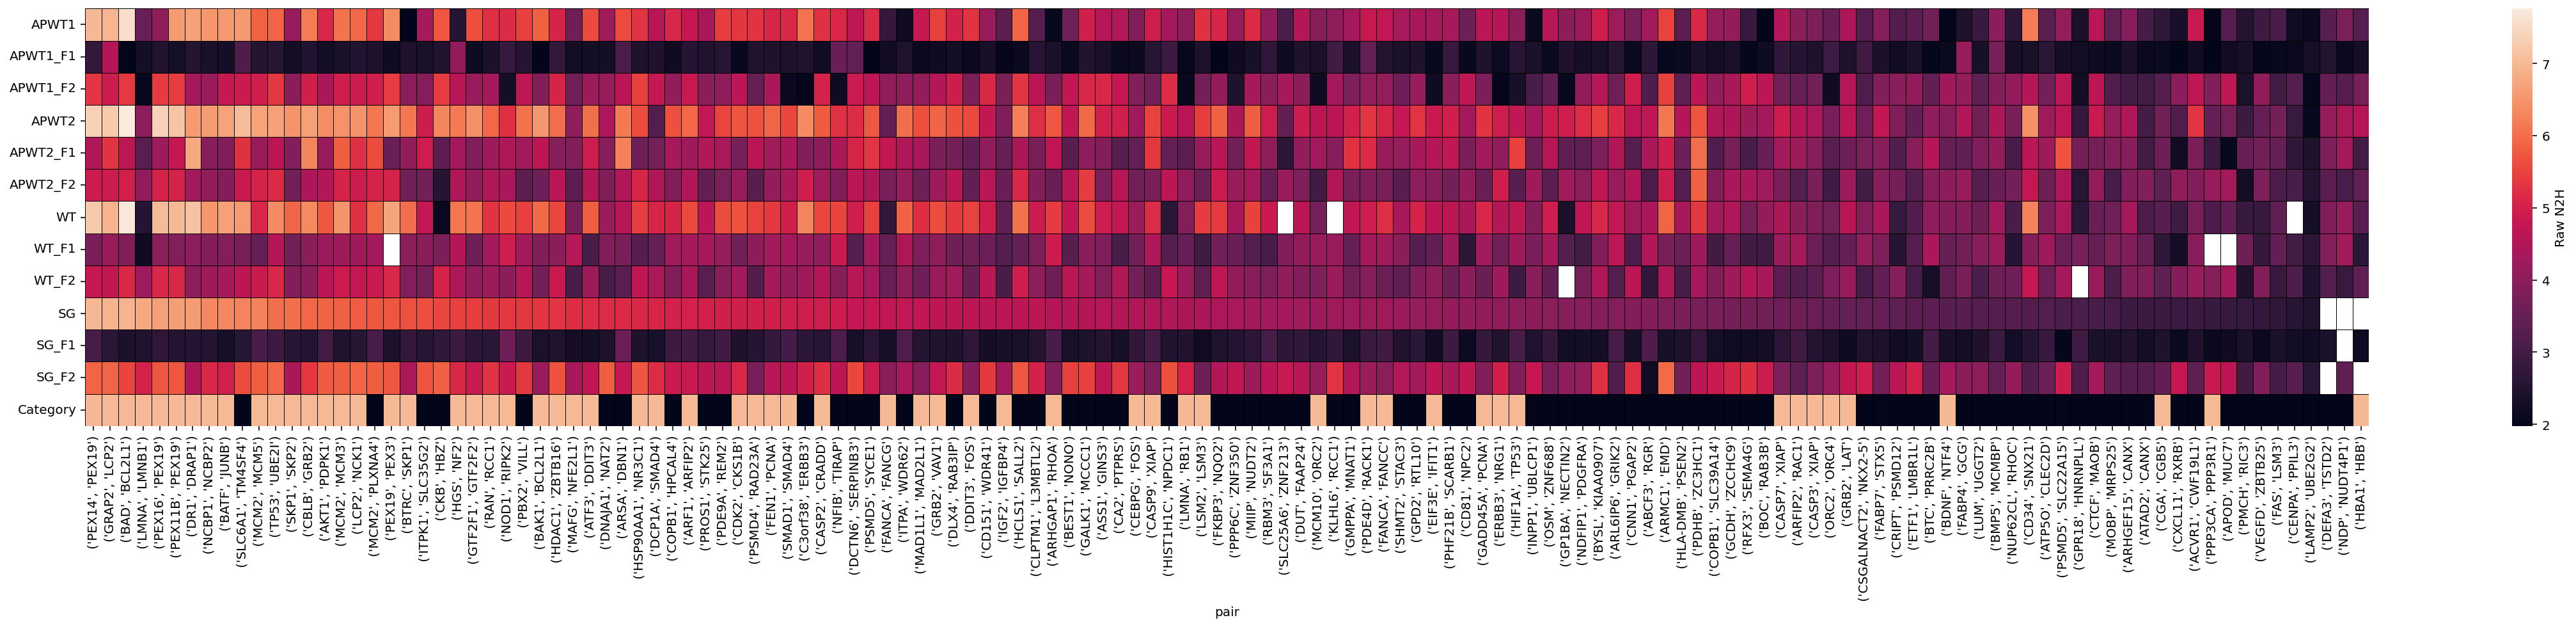

In [89]:
col = ['APWT1','APWT1_F1','APWT1_F2','APWT2','APWT2_F1','APWT2_F2','WT','WT_F1','WT_F2','SG','SG_F1','SG_F2','Category']

plt.figure(figsize=(40,6))
ax = sns.heatmap(prs_rrs_raw[col].T, linewidths=.5, linecolor='black',cbar_kws={'label': 'Raw N2H'})

#ax.tick_params(axis='x', colors='red')    #setting up X-axis tick color to red
#ax.tick_params(axis='y', colors='black')

plt.yticks(rotation=0) 
plt.show()

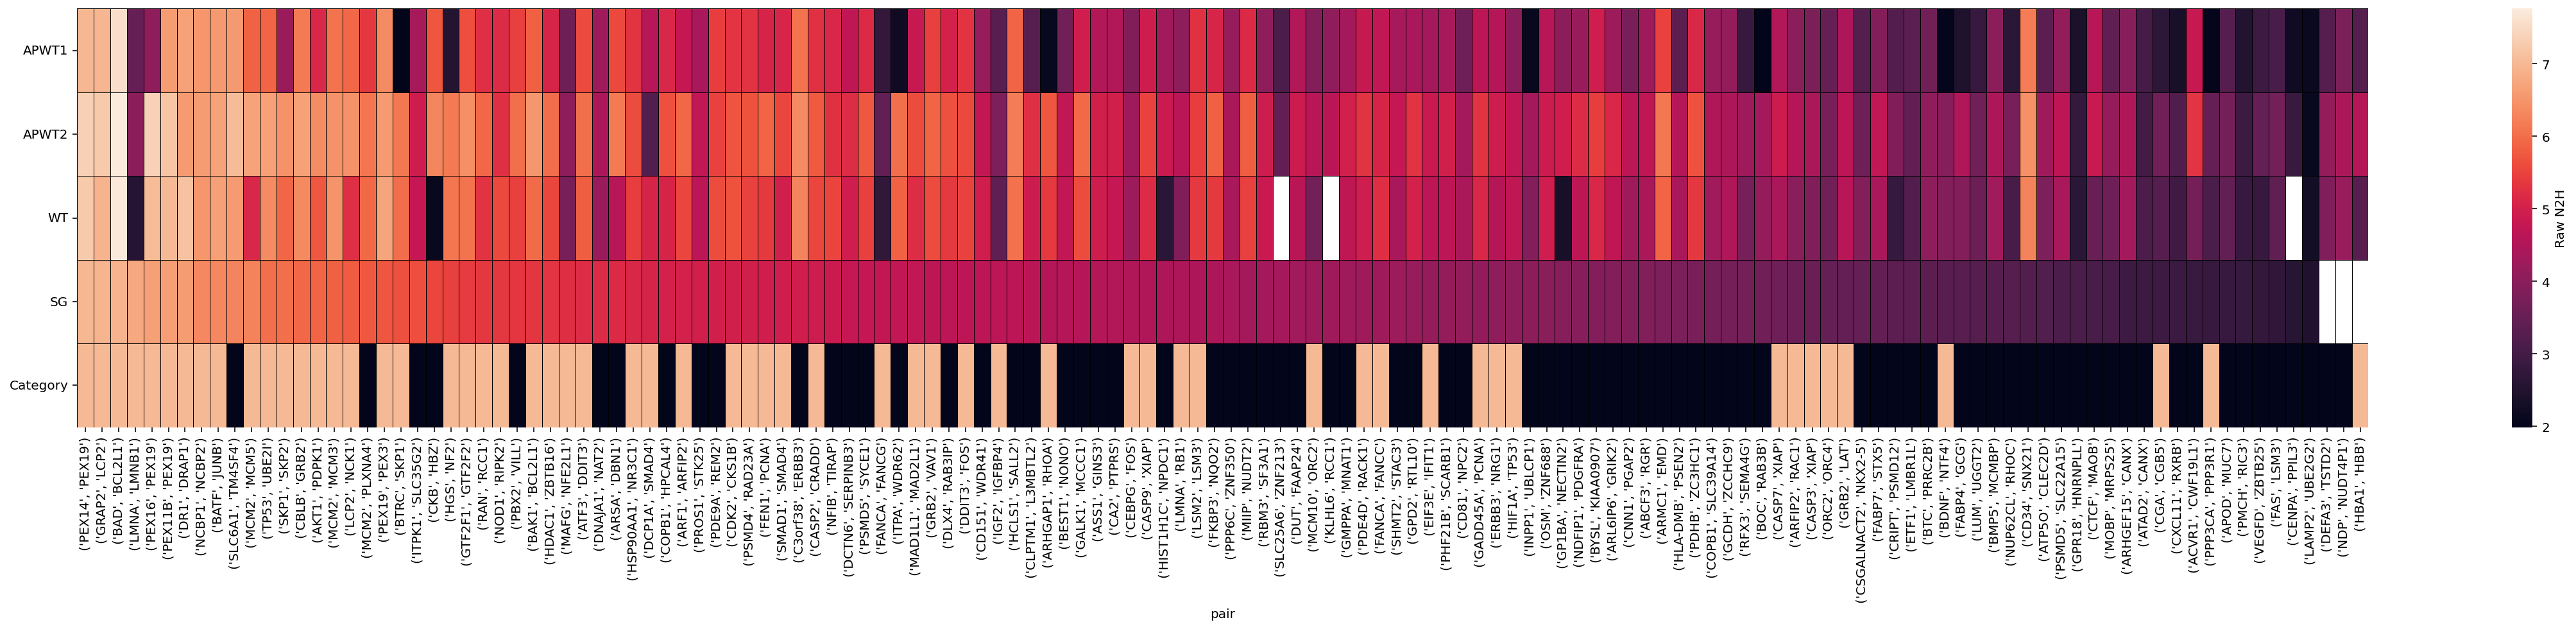

In [90]:
col = ['APWT1','APWT2','WT','SG','Category']
prs_rrs_raw.sort_values(by='SG',inplace=True, ascending=False)
plt.figure(figsize=(40,6))
ax = sns.heatmap(prs_rrs_raw[col].T, linewidths=.5, linecolor='black',cbar_kws={'label': 'Raw N2H'})

#ax.tick_params(axis='x', colors='red')    #setting up X-axis tick color to red
#ax.tick_params(axis='y', colors='black')

plt.yticks(rotation=0) 
plt.show()

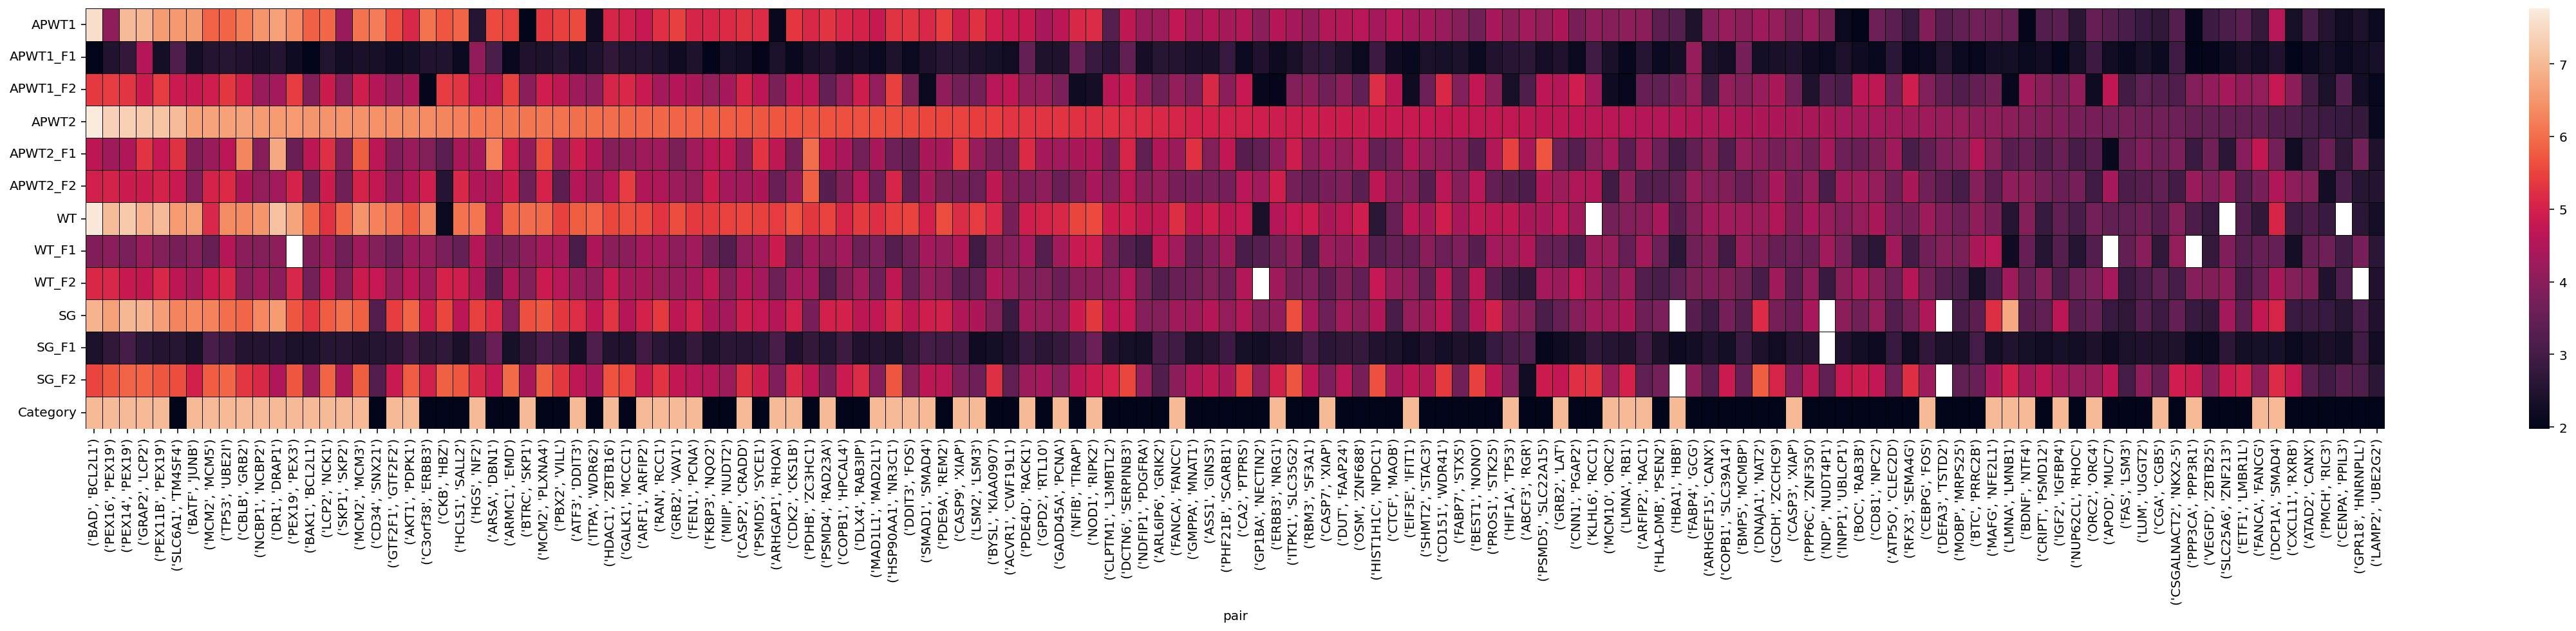

In [91]:
prs_rrs_raw.sort_values(by='APWT2',ascending=False, inplace=True)

col = ['APWT1','APWT1_F1','APWT1_F2','APWT2','APWT2_F1','APWT2_F2','WT','WT_F1','WT_F2','SG','SG_F1','SG_F2','Category']

plt.figure(figsize=(40,6))
ax = sns.heatmap(prs_rrs_raw[col].T, linewidths=.5, linecolor='black')

#ax.tick_params(axis='x', colors='red')    #setting up X-axis tick color to red
#ax.tick_params(axis='y', colors='black')

plt.yticks(rotation=0) 
plt.show()

#### NLR

In [92]:
#df.pair, df.NLR_xp1, df.NLR_xp2, df.zNLR1, df.zNLR2, df.NLR)}

In [93]:
col = ['N1_orf_id', 'N1_symbol', 'N2_orf_id', 'N2_symbol', 'variant_id', 'NLR_xp1', 'NLR_xp2','zNLR1', 'zNLR2']

prs_rrs_df = normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])][col].copy()
prs_rrs_df['pair'] = [tuple(sorted([n1,n2])) for n1, n2 in zip (prs_rrs_df.N1_symbol, prs_rrs_df.N2_symbol)]
prs_rrs_df['NLR_sg1'] = prs_rrs_df.pair.apply(lambda x: sg_mn2h_d[x][0])
prs_rrs_df['NLR_sg2'] = prs_rrs_df.pair.apply(lambda x: sg_mn2h_d[x][1])
prs_rrs_df['NLR_sg3'] = prs_rrs_df.pair.apply(lambda x: sg_mn2h_d[x][2])

prs_rrs_df['zNLR_sg1'] = prs_rrs_df.NLR_sg1.apply(lambda x: (x-np.mean(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg1))/np.std(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg1))
prs_rrs_df['zNLR_sg2'] = prs_rrs_df.NLR_sg2.apply(lambda x: (x-np.mean(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg2))/np.std(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg2))
prs_rrs_df['zNLR_sg3'] = prs_rrs_df.NLR_sg3.apply(lambda x: (x-np.mean(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg3))/np.std(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'].NLR_sg3))

trsh = 2

prs_rrs_df['zNLR1'] = prs_rrs_df.zNLR1.apply(lambda x: x if x >= trsh else 0)
prs_rrs_df['zNLR2'] = prs_rrs_df.zNLR2.apply(lambda x: x if x >= trsh else 0)

prs_rrs_df['zNLR_sg1'] = prs_rrs_df.zNLR_sg1.apply(lambda x: x if x >= trsh else 0)
prs_rrs_df['zNLR_sg2'] = prs_rrs_df.zNLR_sg2.apply(lambda x: x if x >= trsh else 0)
prs_rrs_df['zNLR_sg3'] = prs_rrs_df.zNLR_sg3.apply(lambda x: x if x >= trsh else 0)

prs_rrs_df['wtNLRxp1'] = prs_rrs_df.pair.apply(lambda x: wt_prs_rrs_d[x][0])
prs_rrs_df['wtNLRxp2'] = prs_rrs_df.pair.apply(lambda x: wt_prs_rrs_d[x][1])
prs_rrs_df['zwtNLRxp1'] = prs_rrs_df.pair.apply(lambda x: wt_prs_rrs_d[x][2])
prs_rrs_df['zwtNLRxp2'] = prs_rrs_df.pair.apply(lambda x: wt_prs_rrs_d[x][3])

prs_rrs_df['zwtNLRxp1'] = prs_rrs_df.zwtNLRxp1.apply(lambda x: x if x >= trsh else 0)
prs_rrs_df['zwtNLRxp2'] = prs_rrs_df.zwtNLRxp2.apply(lambda x: x if x >= trsh else 0)

prs_rrs_df.set_index('pair', inplace=True)

prs_rrs_df.sort_values(by='NLR_xp1', inplace=True, ascending=False)

prs_rrs_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,variant_id,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR_sg1,NLR_sg2,NLR_sg3,zNLR_sg1,zNLR_sg2,zNLR_sg3,wtNLRxp1,wtNLRxp2,zwtNLRxp1,zwtNLRxp2
pair,,,,,,,,,,,,,,,,,,,
"(CKB, HBZ)",3341,CKB,8297,HBZ,RRS,10.113781,9.378158,3.697513,3.388419,-0.554599,-1.574592,-0.826072,0.000000,0.000000,0.000000,-9.962253,-9.441248,0.000000,0.000000
"(BAD, BCL2L1)",3706,BAD,5989,BCL2L1,PRS,9.576579,9.134250,3.470196,3.285915,4.731474,4.188885,5.022325,2.869938,3.027036,3.076601,8.783256,8.489902,2.700530,2.689372
"(BATF, JUNB)",4265,JUNB,9618,BATF,PRS,9.063310,9.197064,3.253006,3.312313,4.326053,4.282948,4.912257,2.668978,3.071594,3.025488,7.855960,7.342043,2.387023,2.288745
"(SKP1, SKP2)",6671,SKP1,4656,SKP2,PRS,8.770027,8.438734,3.128904,2.993622,6.827112,4.671595,5.481617,3.908711,3.255699,3.289890,7.399307,8.008289,2.232634,2.521279
"(NCBP1, NCBP2)",7450,NCBP1,2754,NCBP2,PRS,8.654504,7.919307,3.080020,2.775331,4.664302,3.445337,4.152358,2.836642,2.674811,2.672602,7.443319,7.424585,2.247514,2.317554


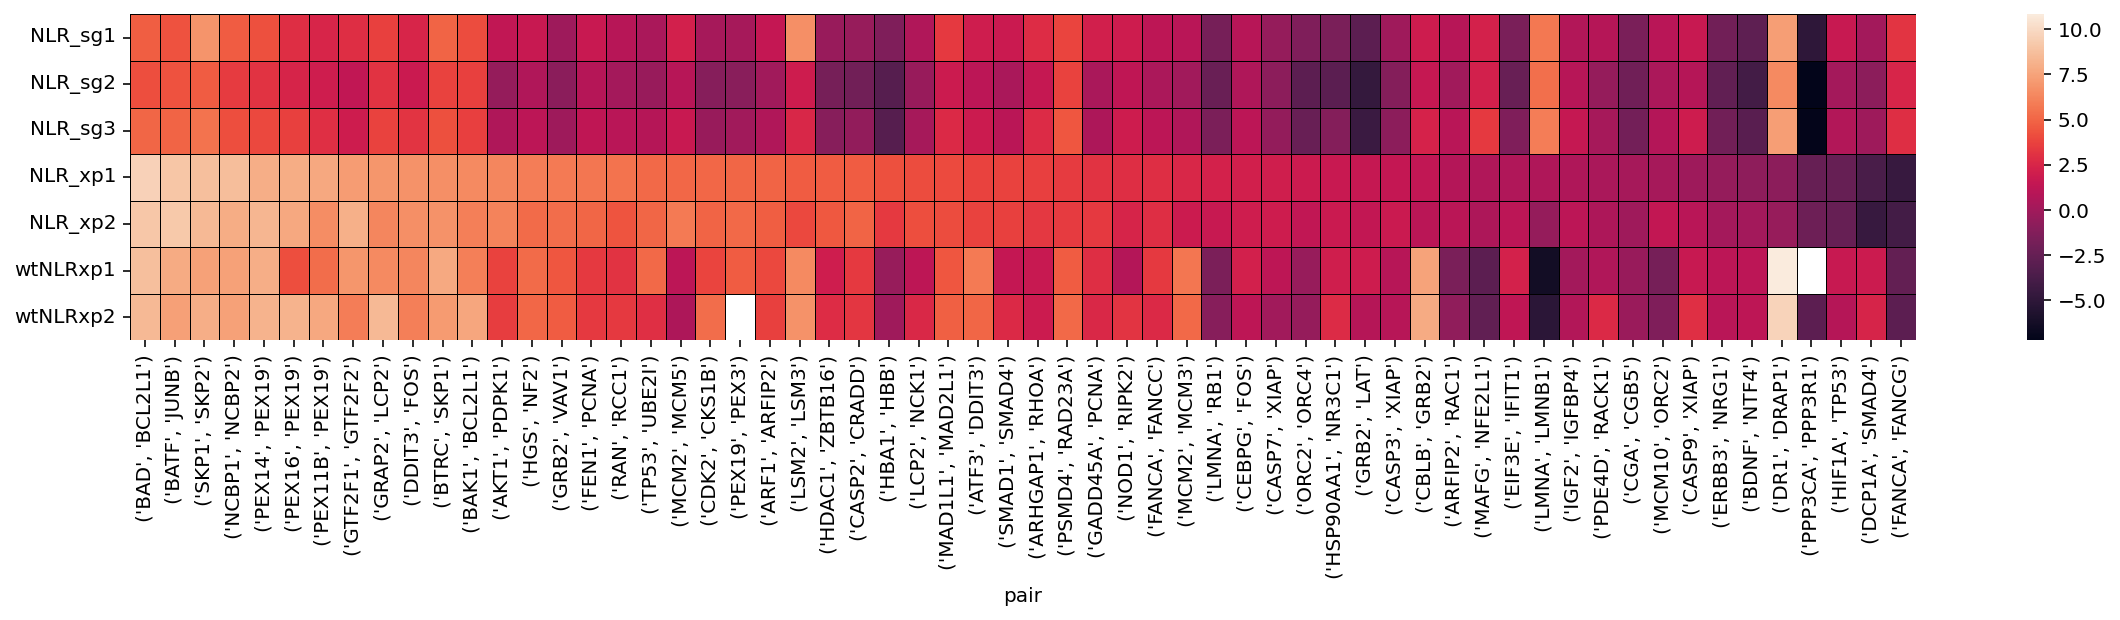

In [94]:
col = [ 'NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']

plt.figure(figsize=(20,3))
ax = sns.heatmap(prs_rrs_df[prs_rrs_df.variant_id == 'PRS'][col].T, linewidths=.5, linecolor='black')

plt.yticks(rotation=0) 
plt.show()

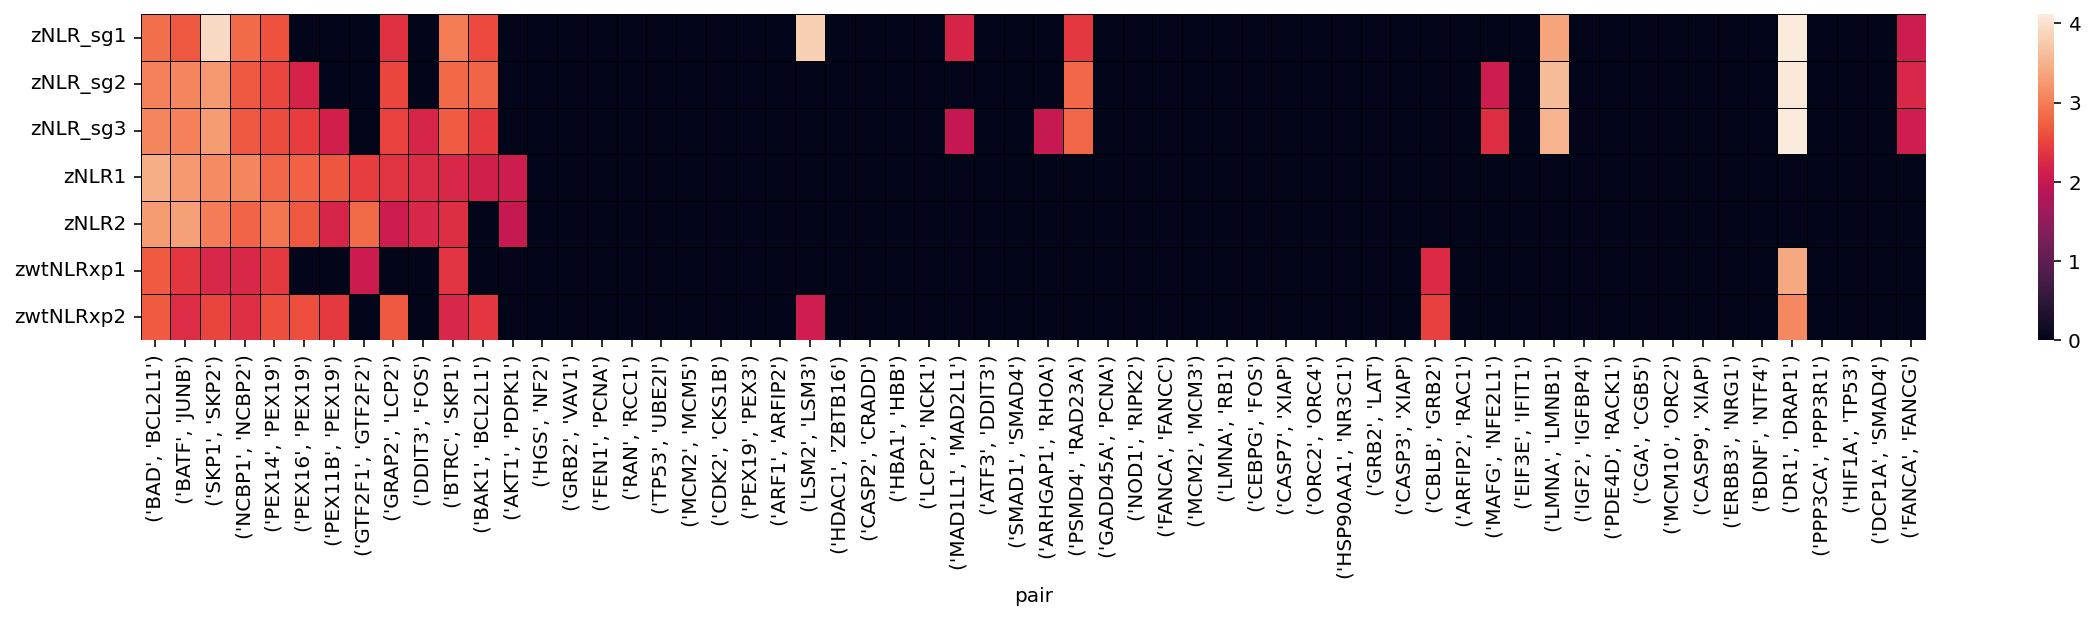

In [95]:
col = [ 'zNLR_sg1','zNLR_sg2', 'zNLR_sg3','zNLR1','zNLR2','zwtNLRxp1','zwtNLRxp2']

plt.figure(figsize=(20,3))
ax = sns.heatmap(prs_rrs_df[prs_rrs_df.variant_id == 'PRS'][col].T, linewidths=.5, linecolor='black')

plt.yticks(rotation=0) 
plt.show()

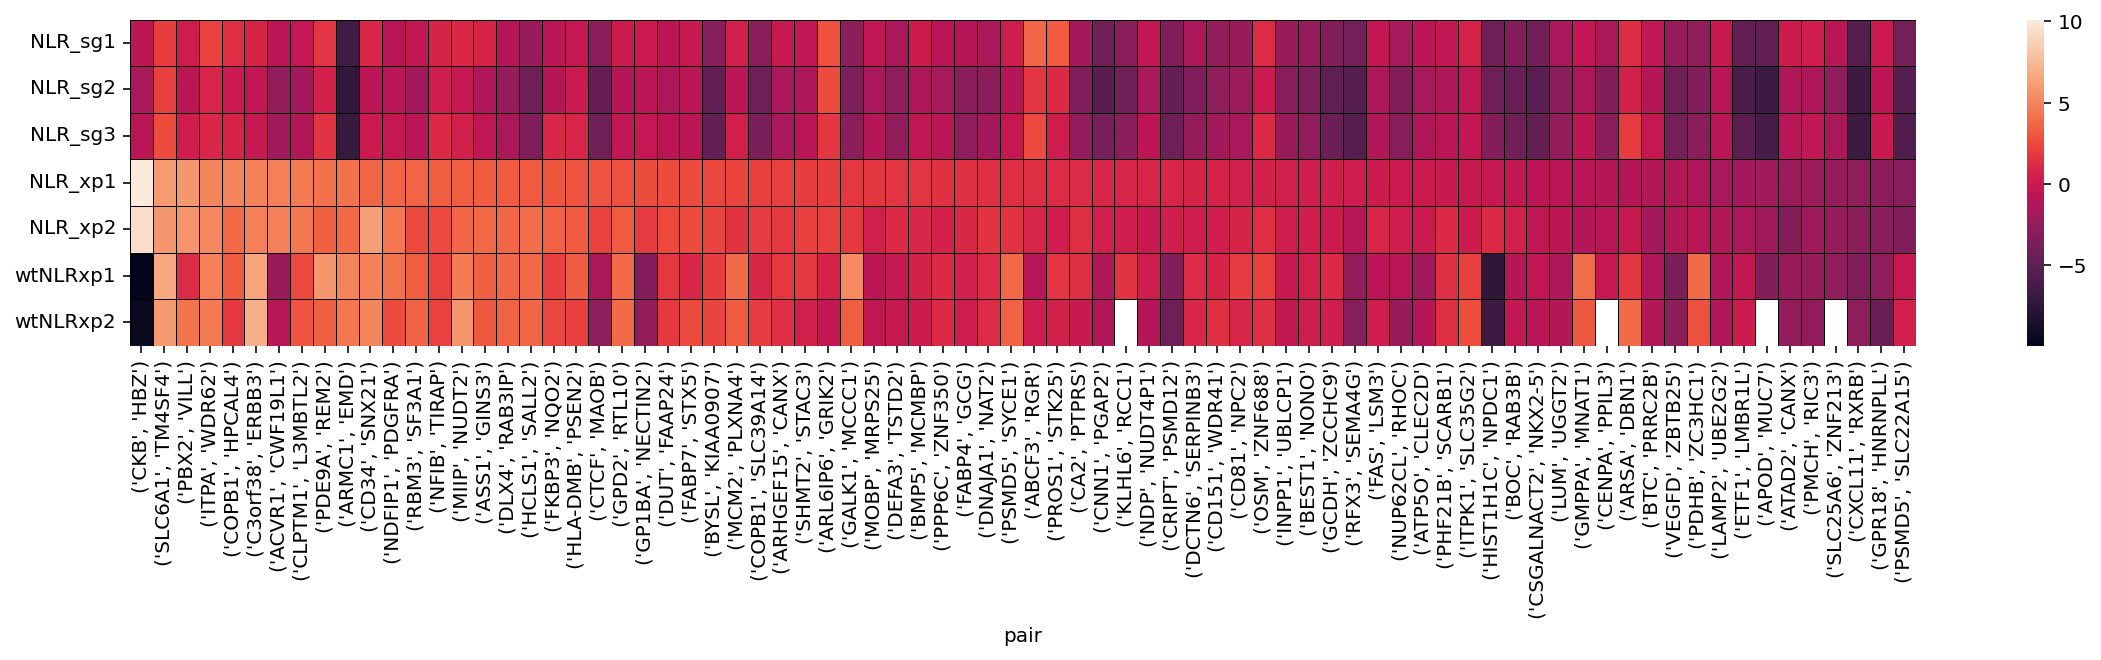

In [96]:
col = [ 'NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']

plt.figure(figsize=(20,3))
ax = sns.heatmap(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'][col].T, linewidths=.5, linecolor='black')

plt.yticks(rotation=0) 
plt.show()

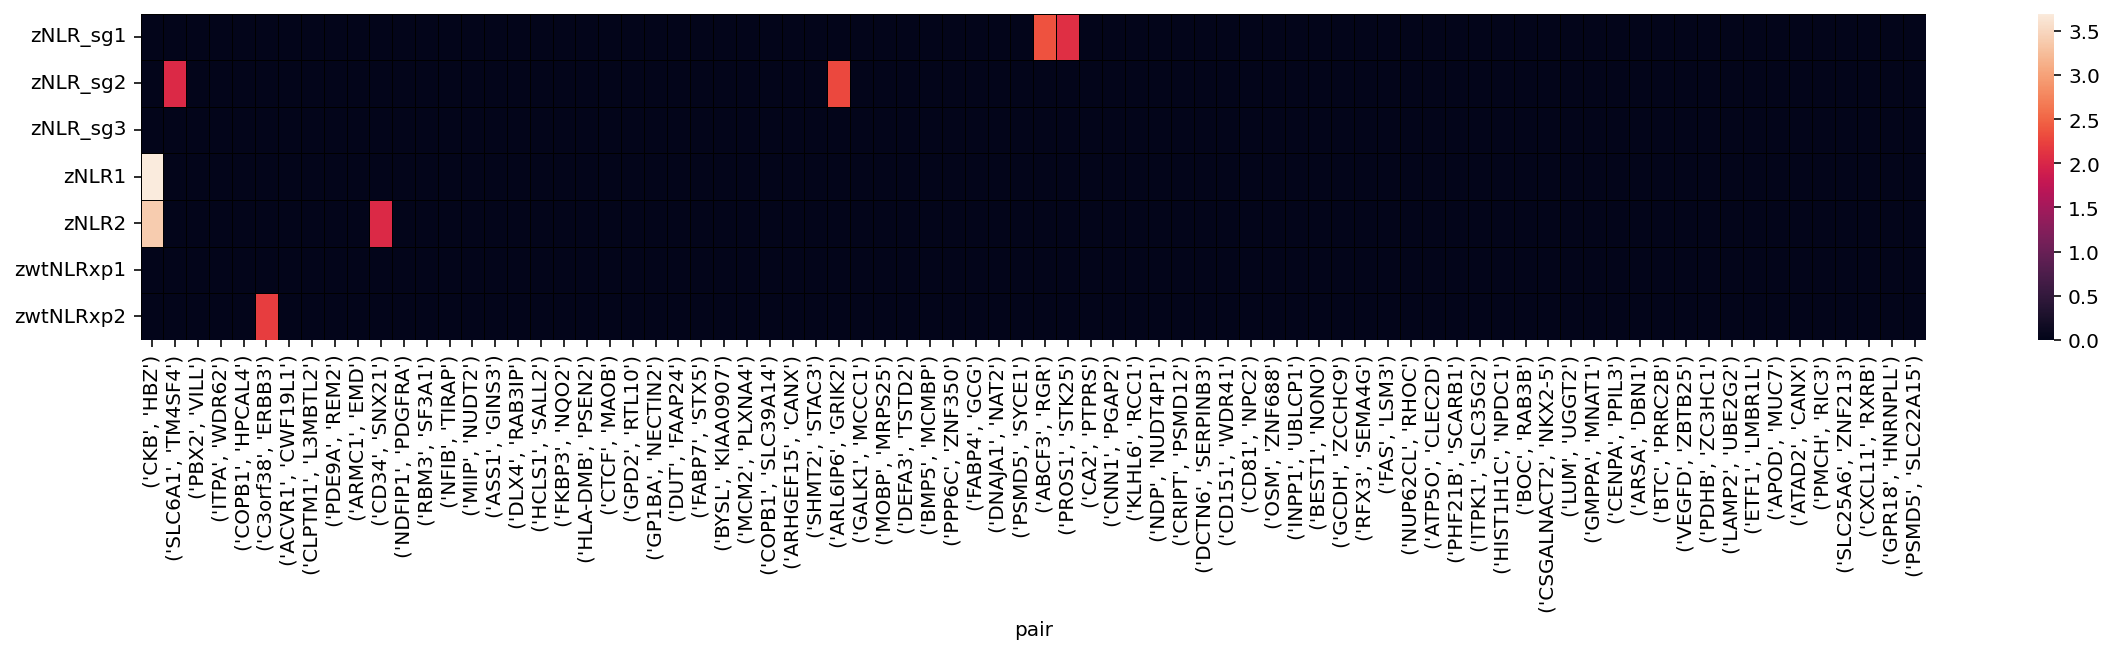

In [97]:
col = [ 'zNLR_sg1','zNLR_sg2', 'zNLR_sg3','zNLR1','zNLR2','zwtNLRxp1','zwtNLRxp2']

plt.figure(figsize=(20,3))
ax = sns.heatmap(prs_rrs_df[prs_rrs_df.variant_id == 'RRS'][col].T, linewidths=.5, linecolor='black')

plt.yticks(rotation=0) 
plt.show()

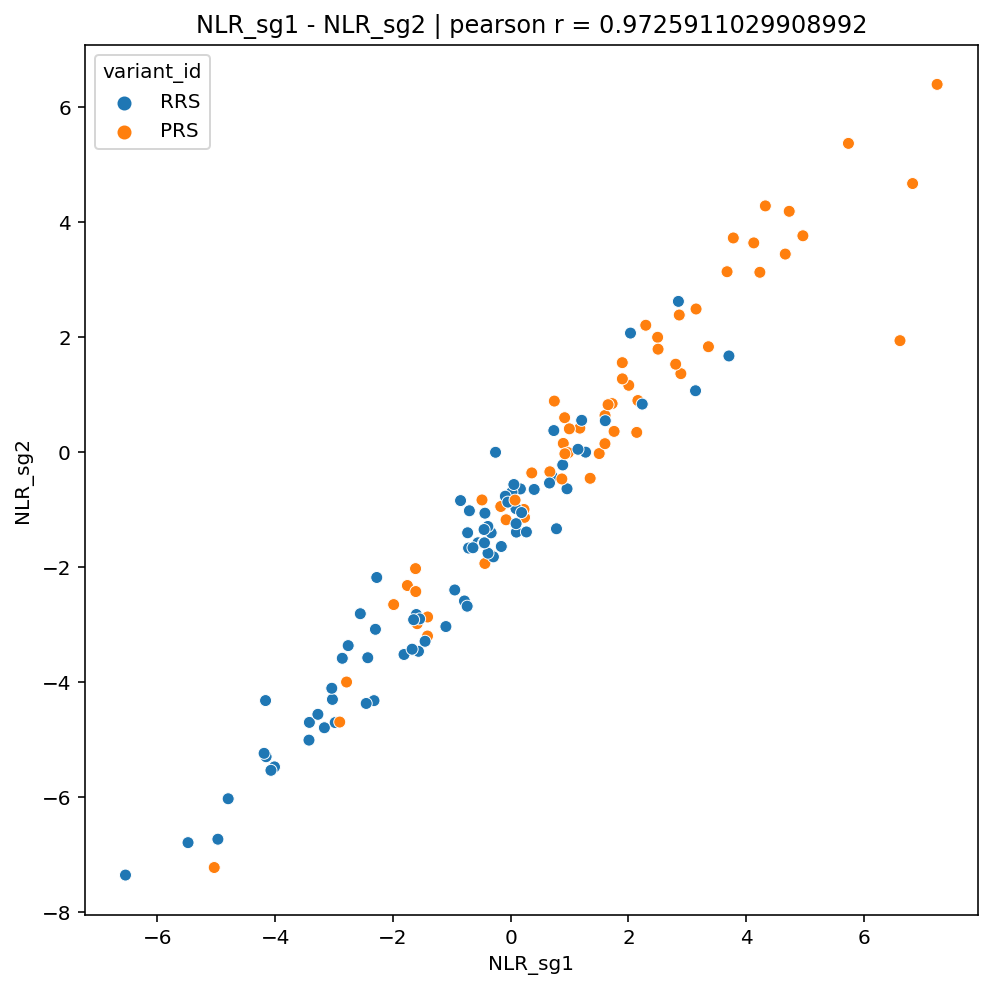

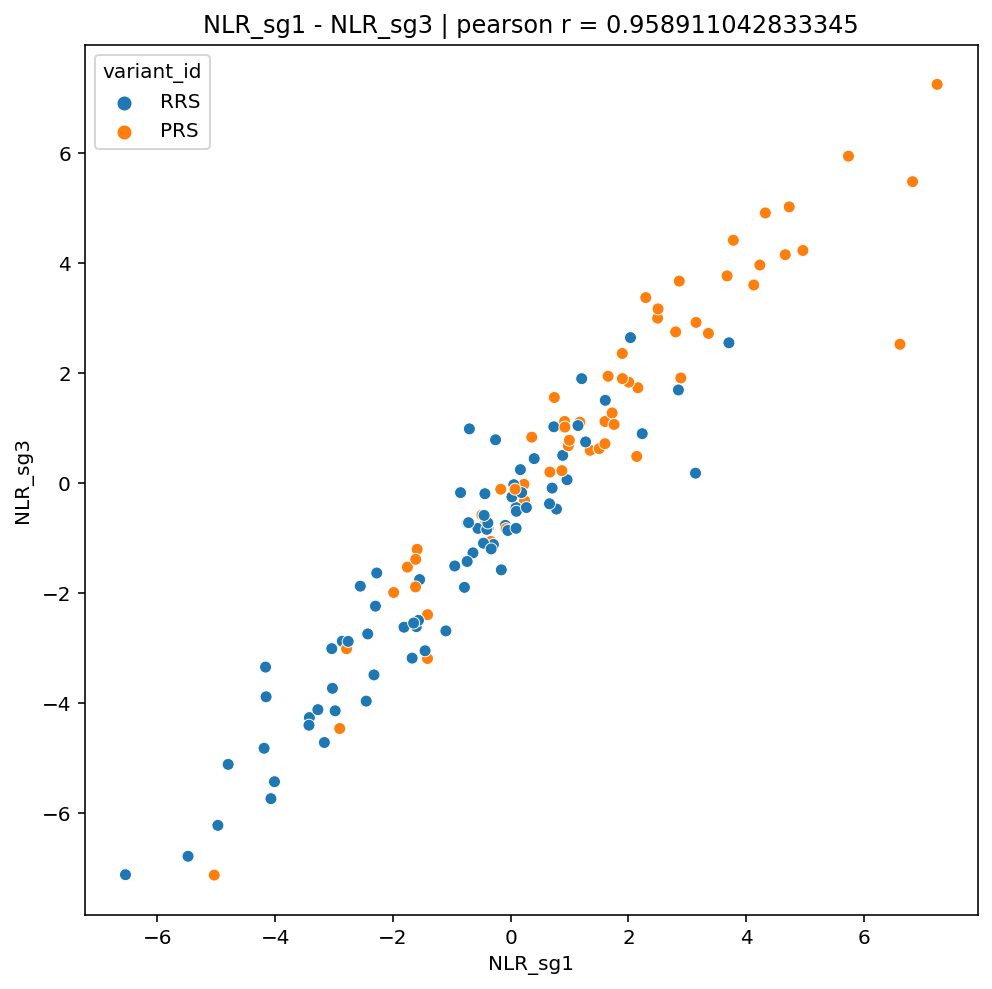

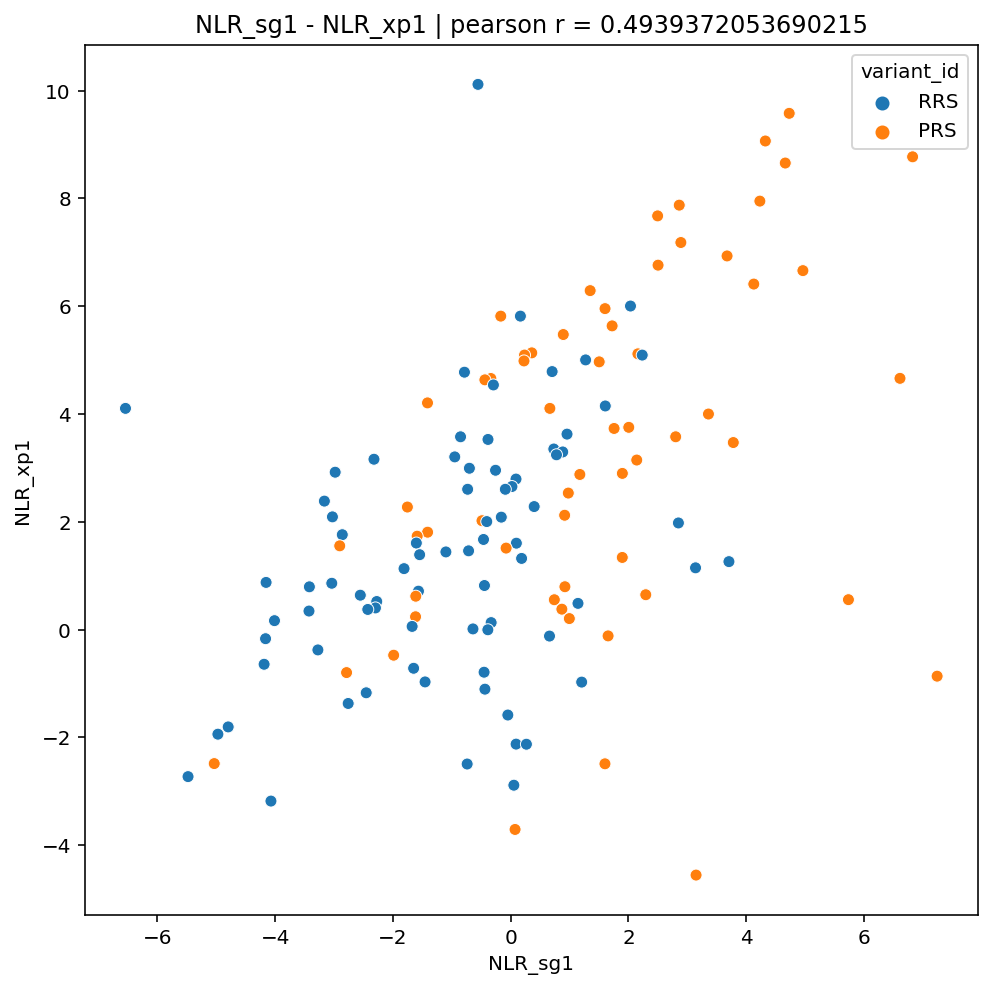

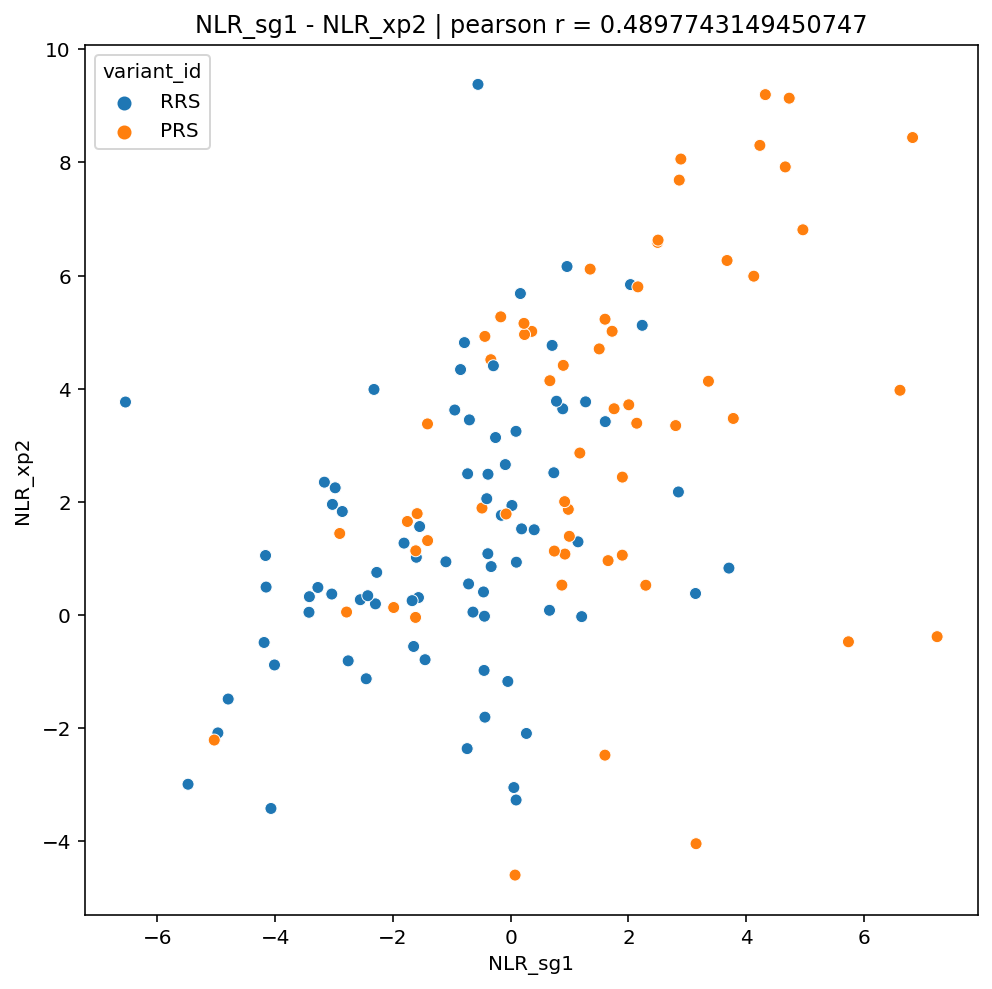

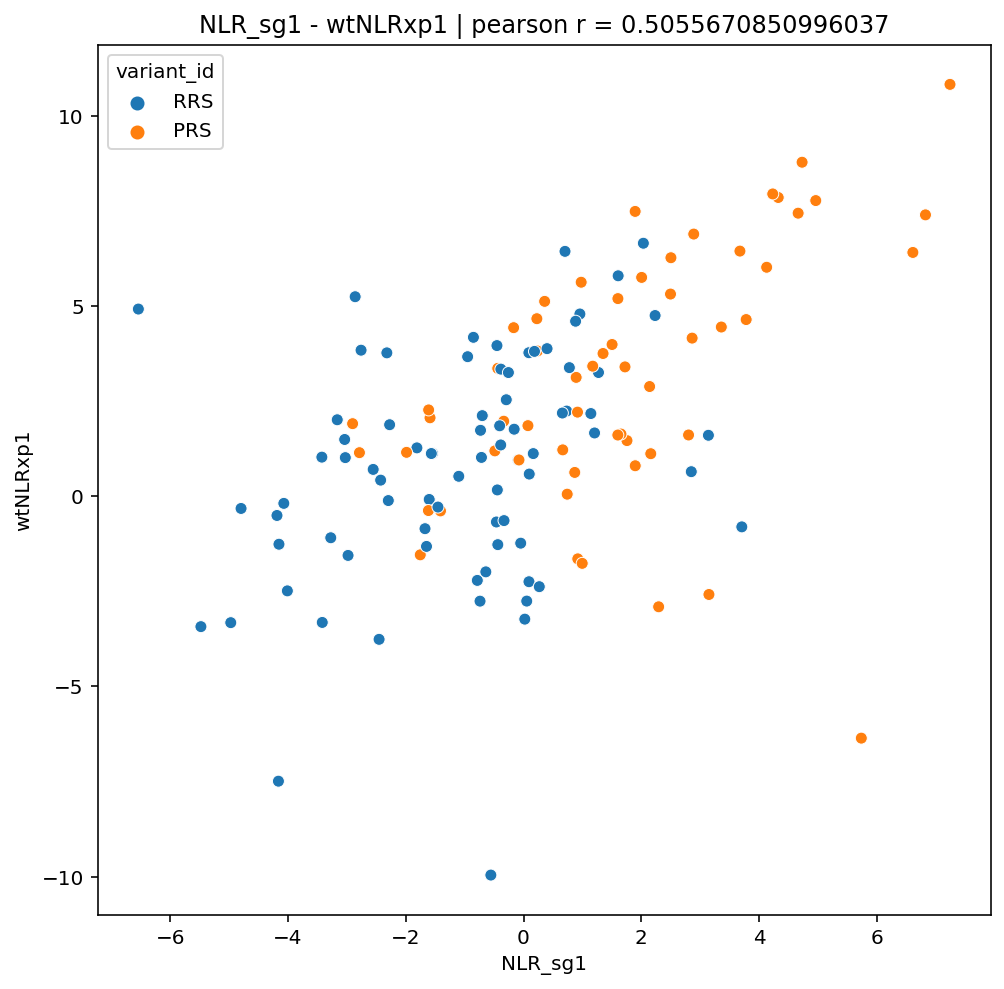

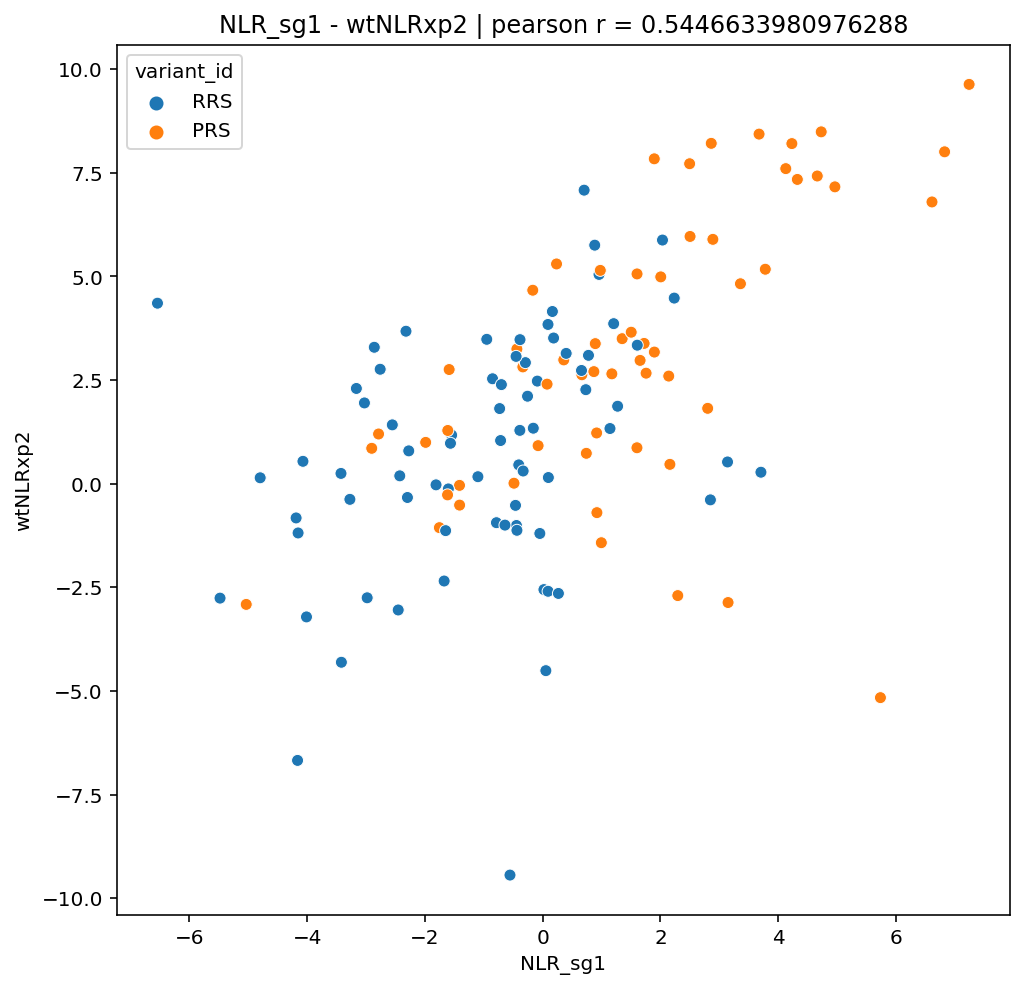

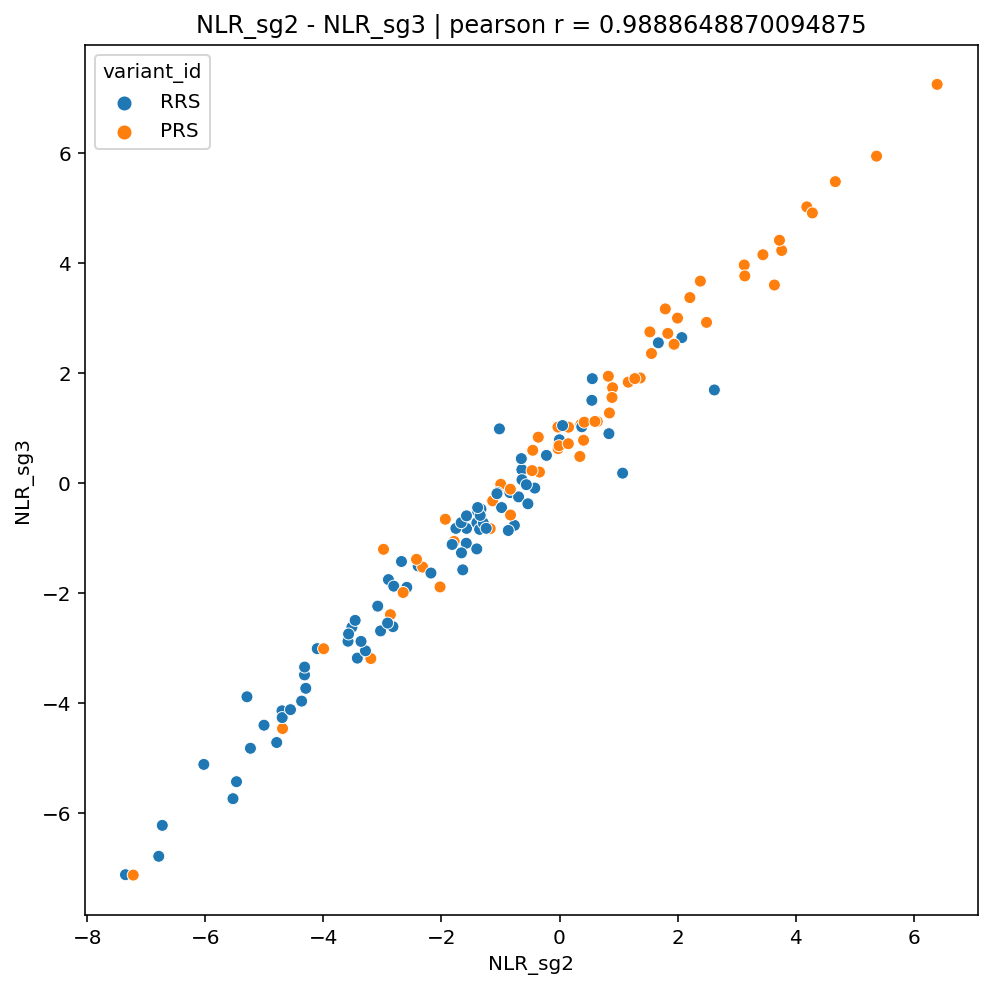

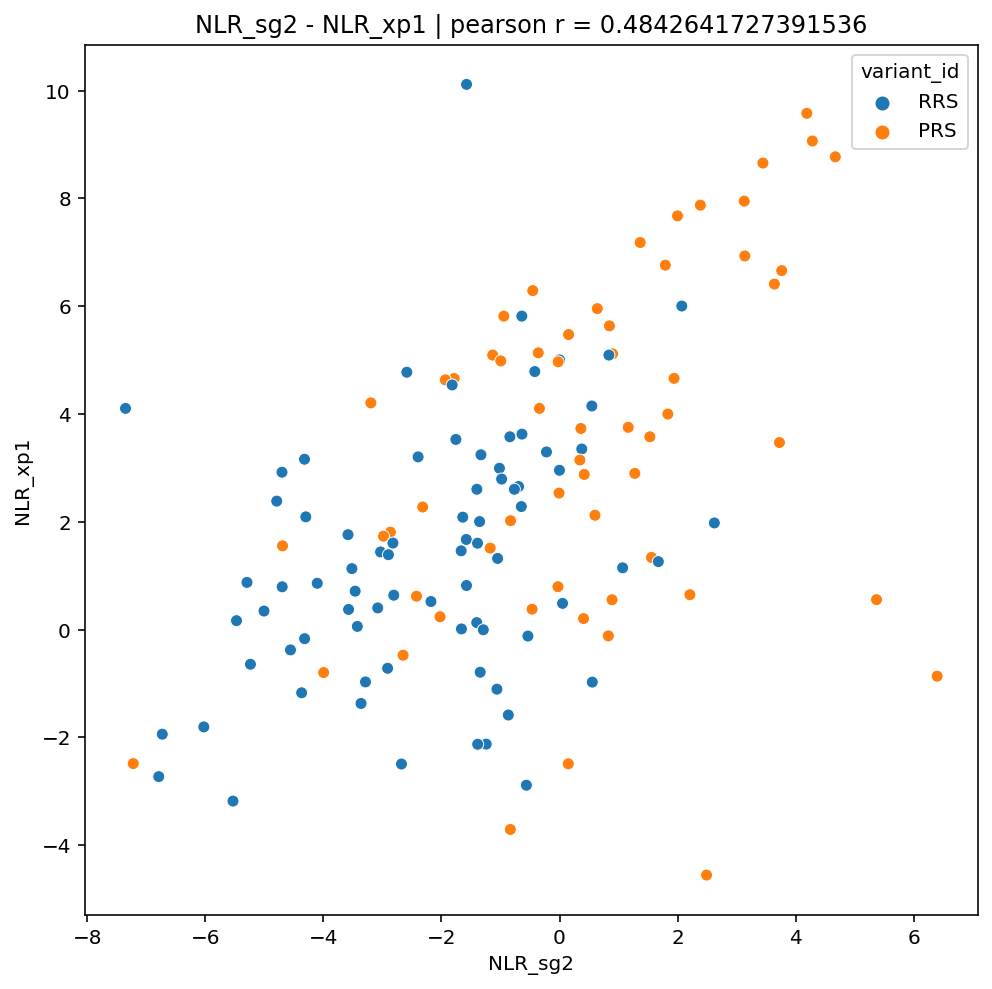

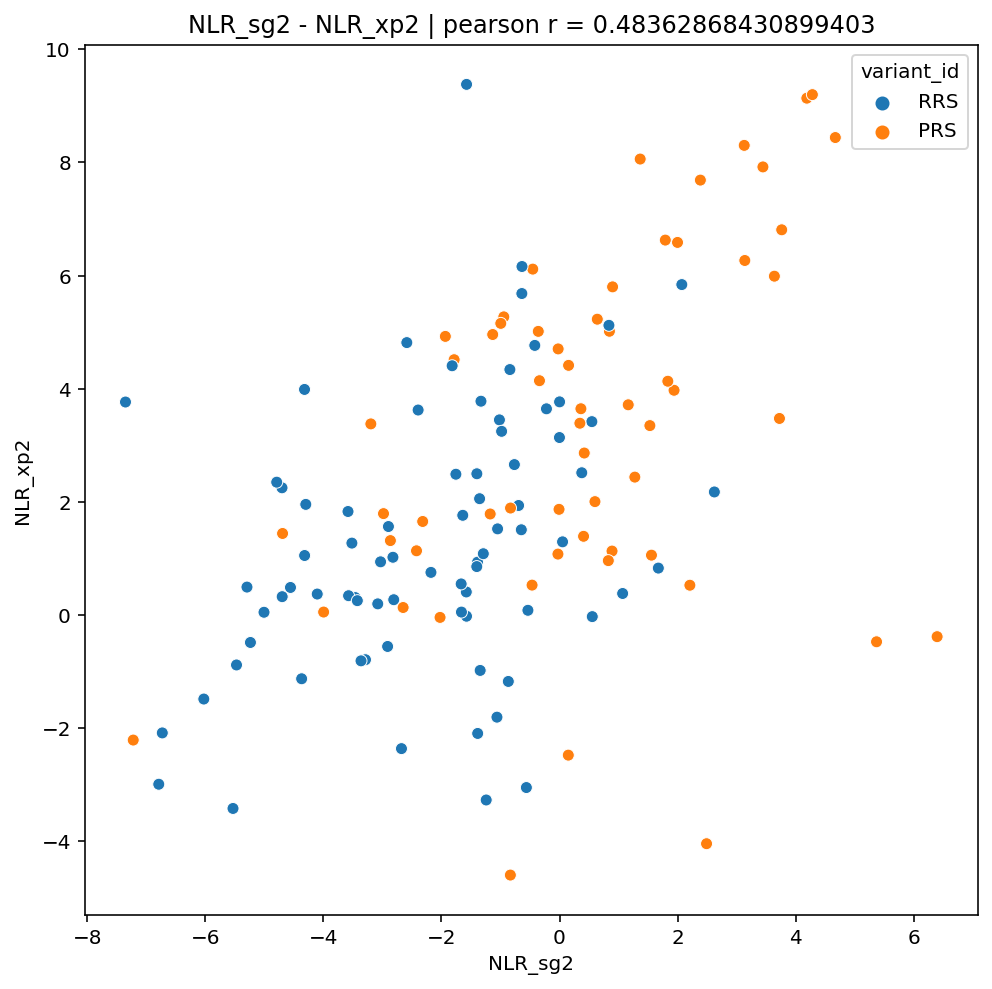

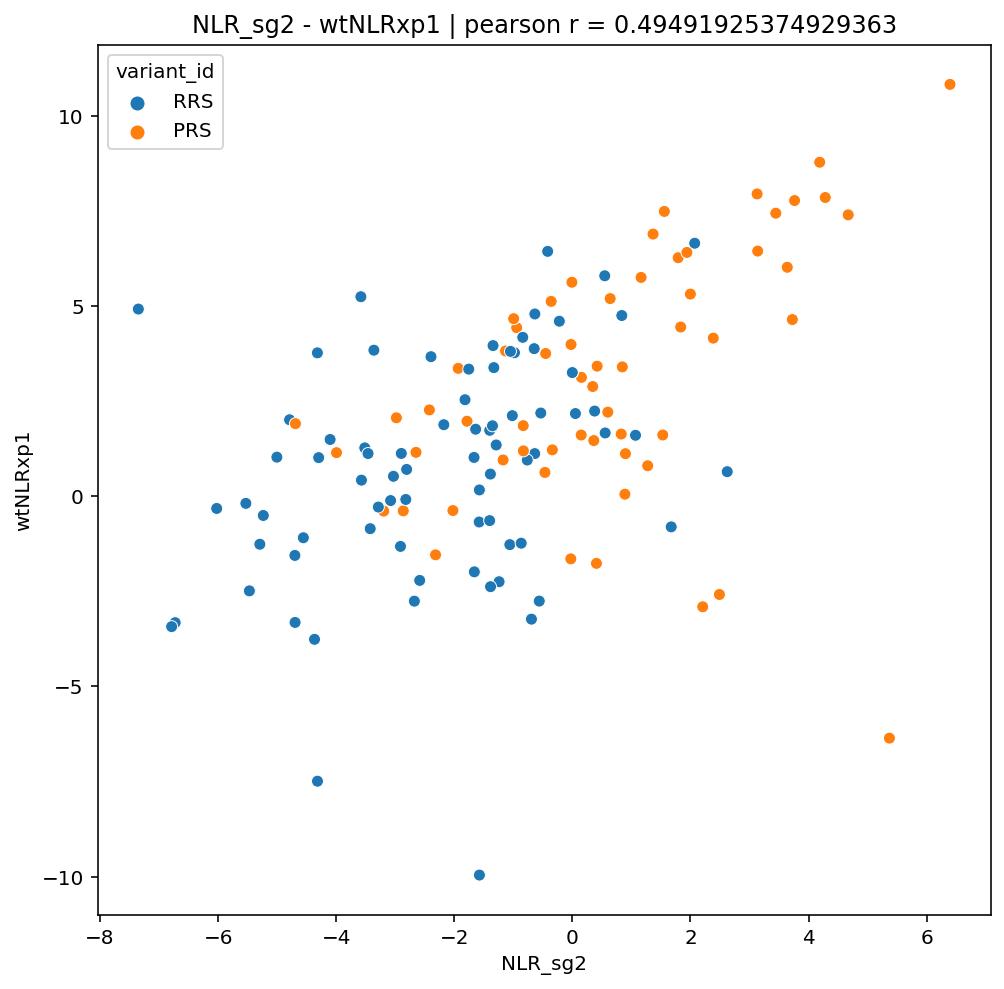

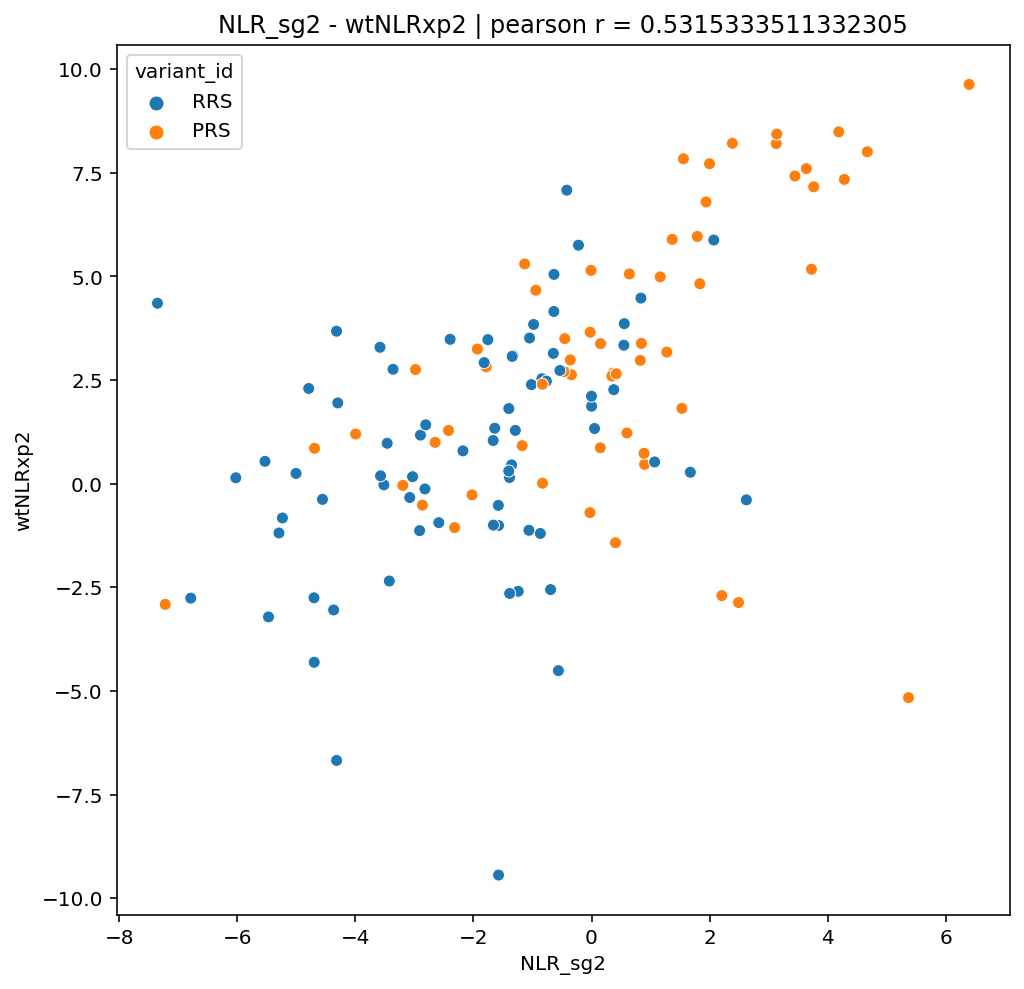

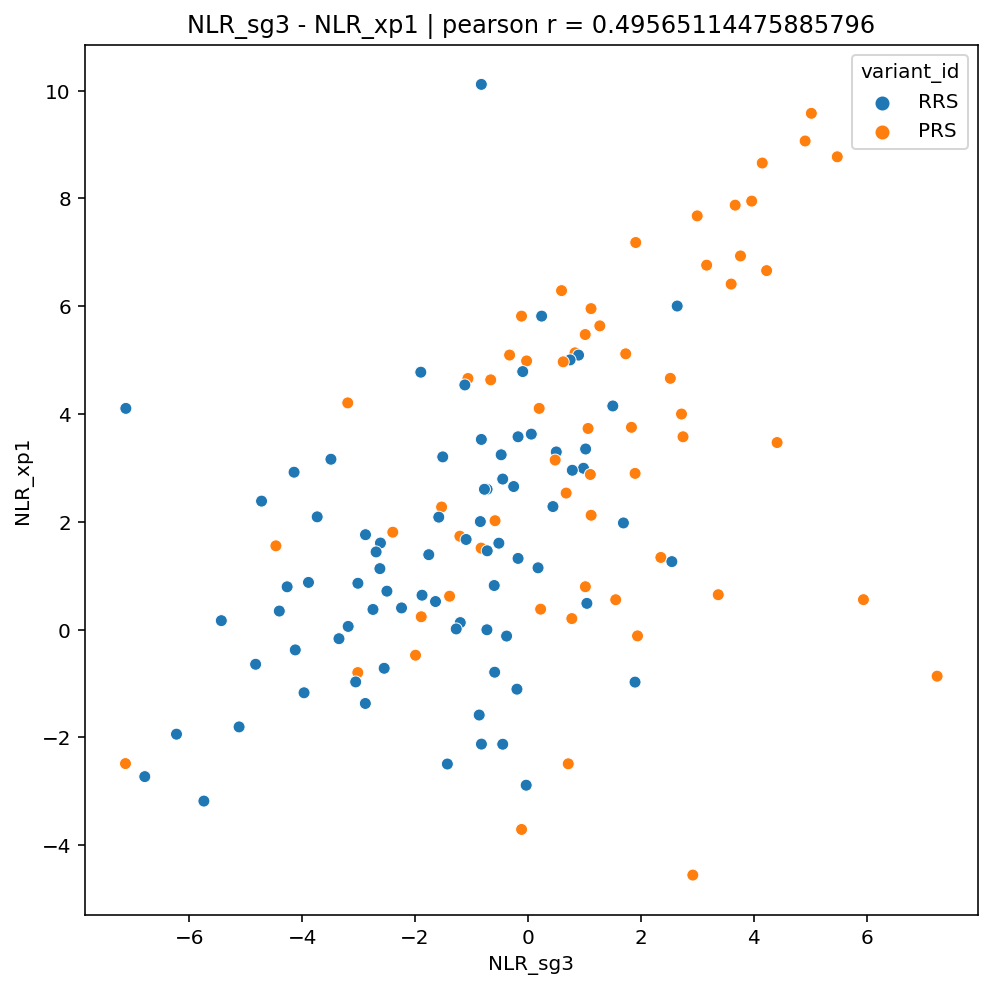

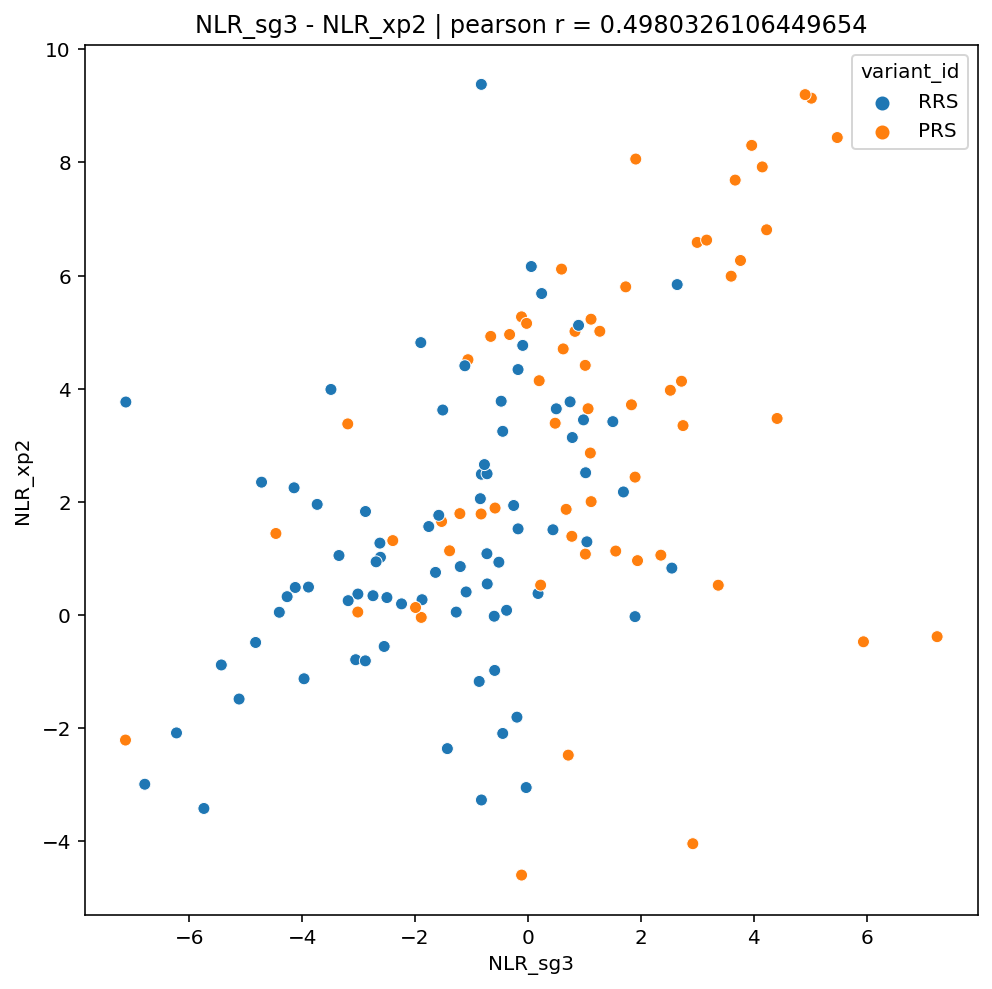

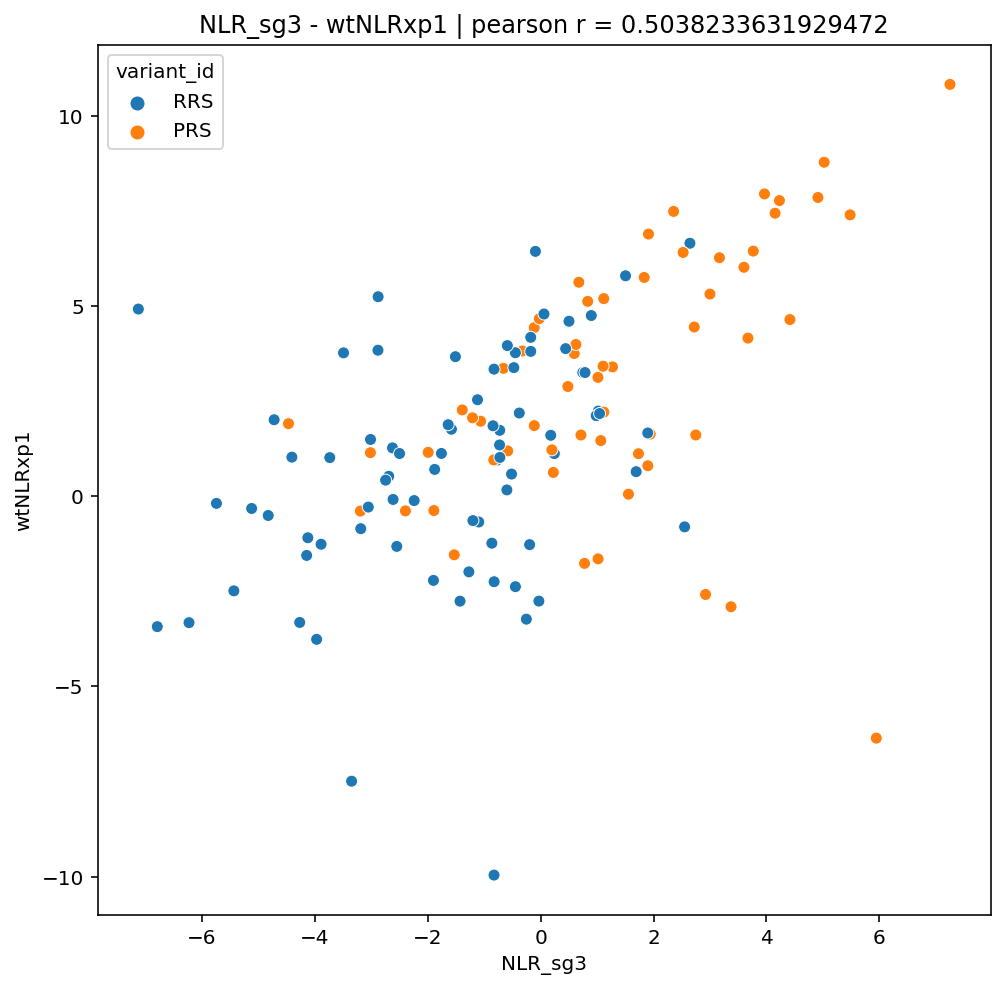

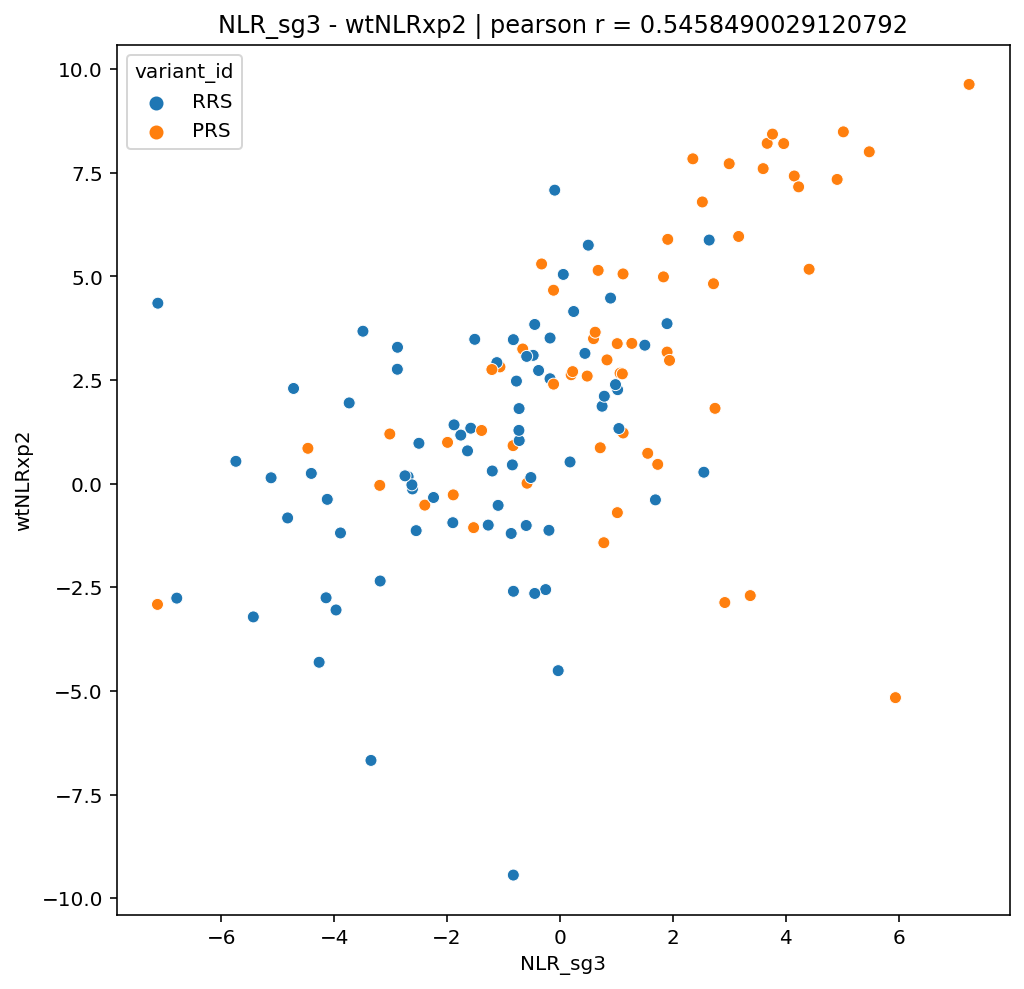

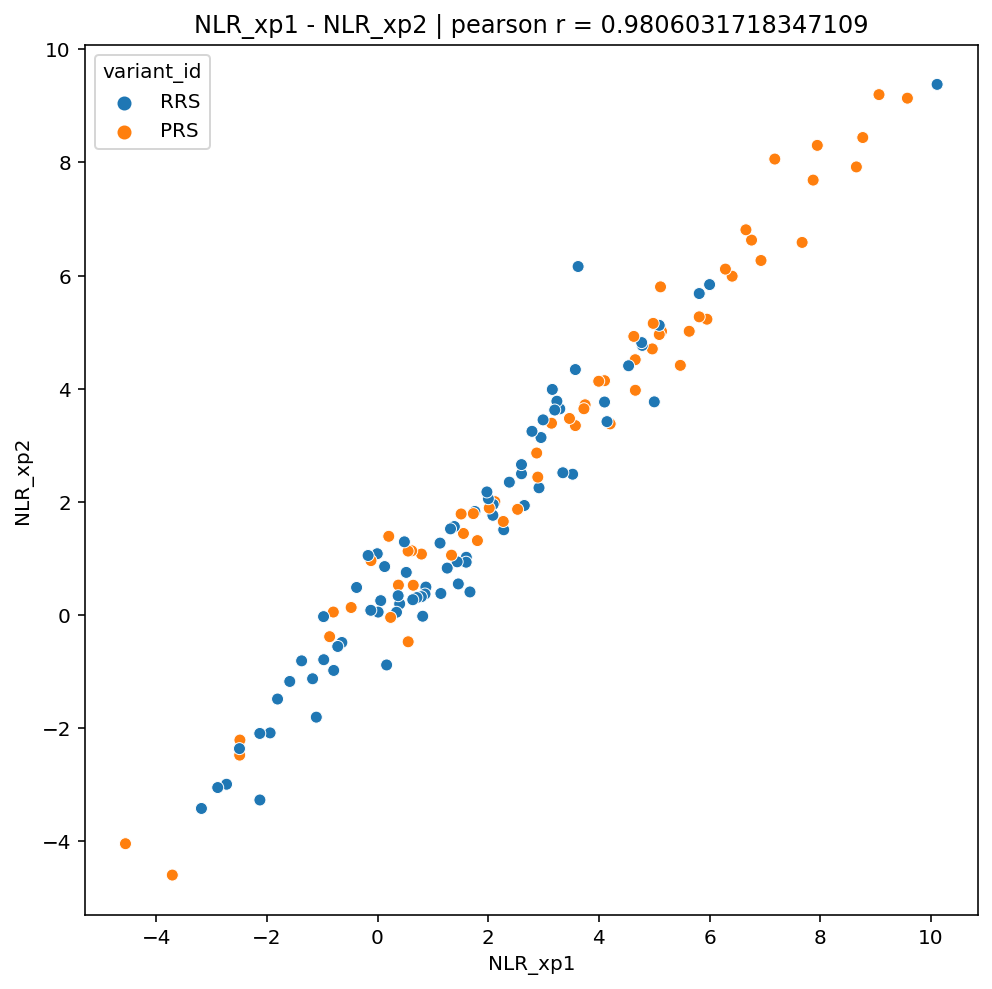

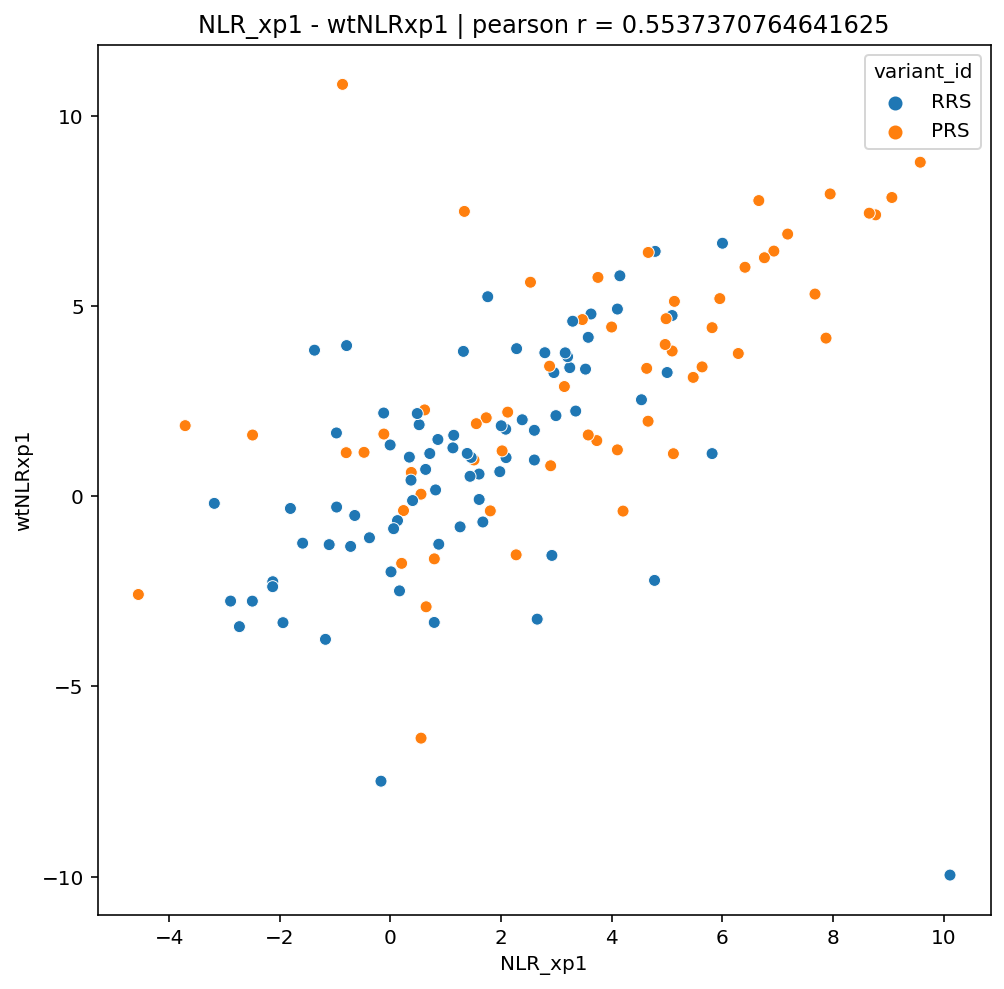

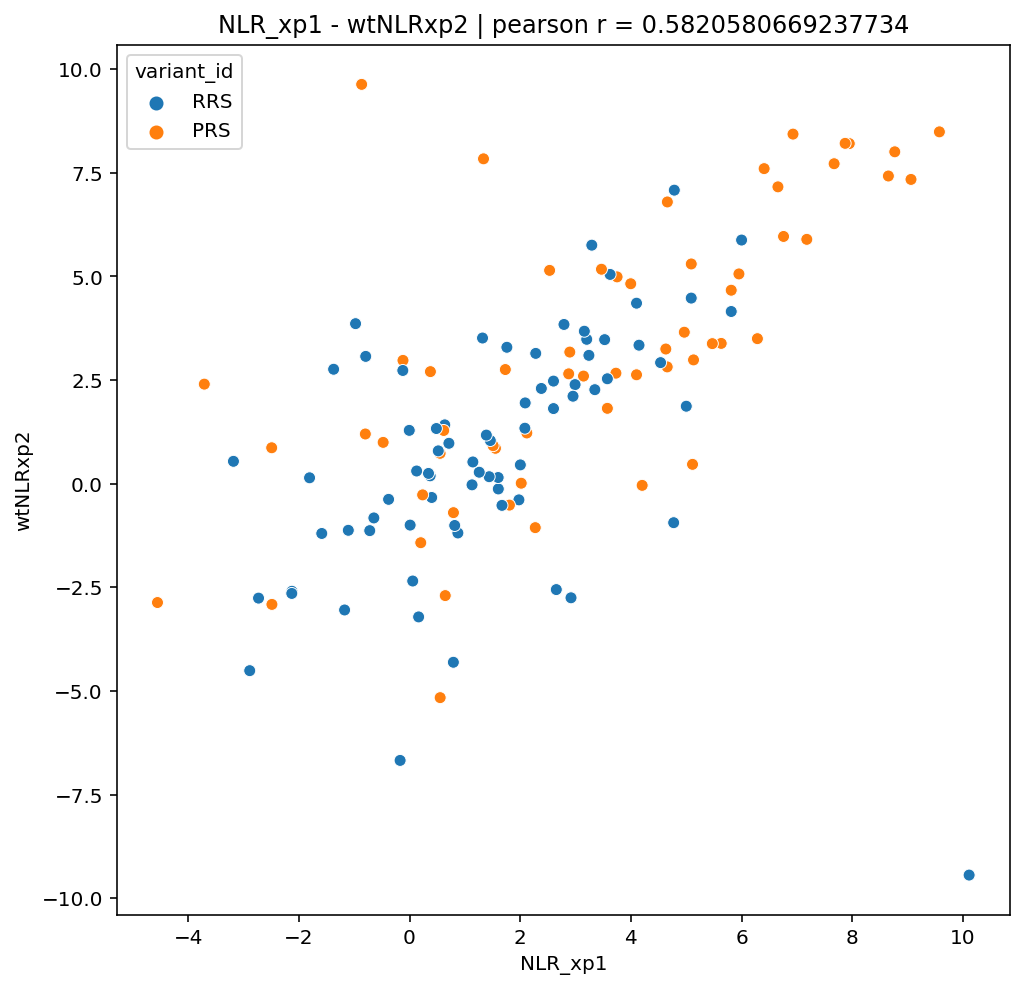

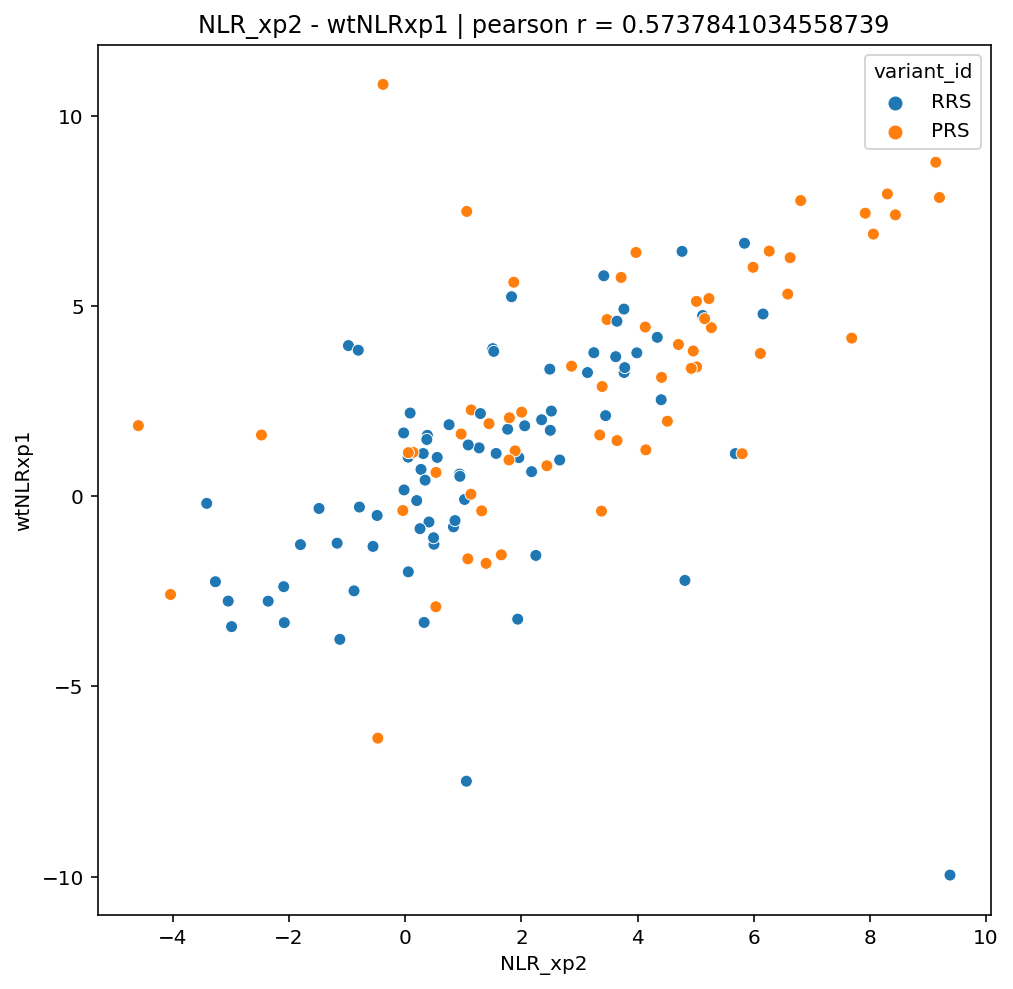

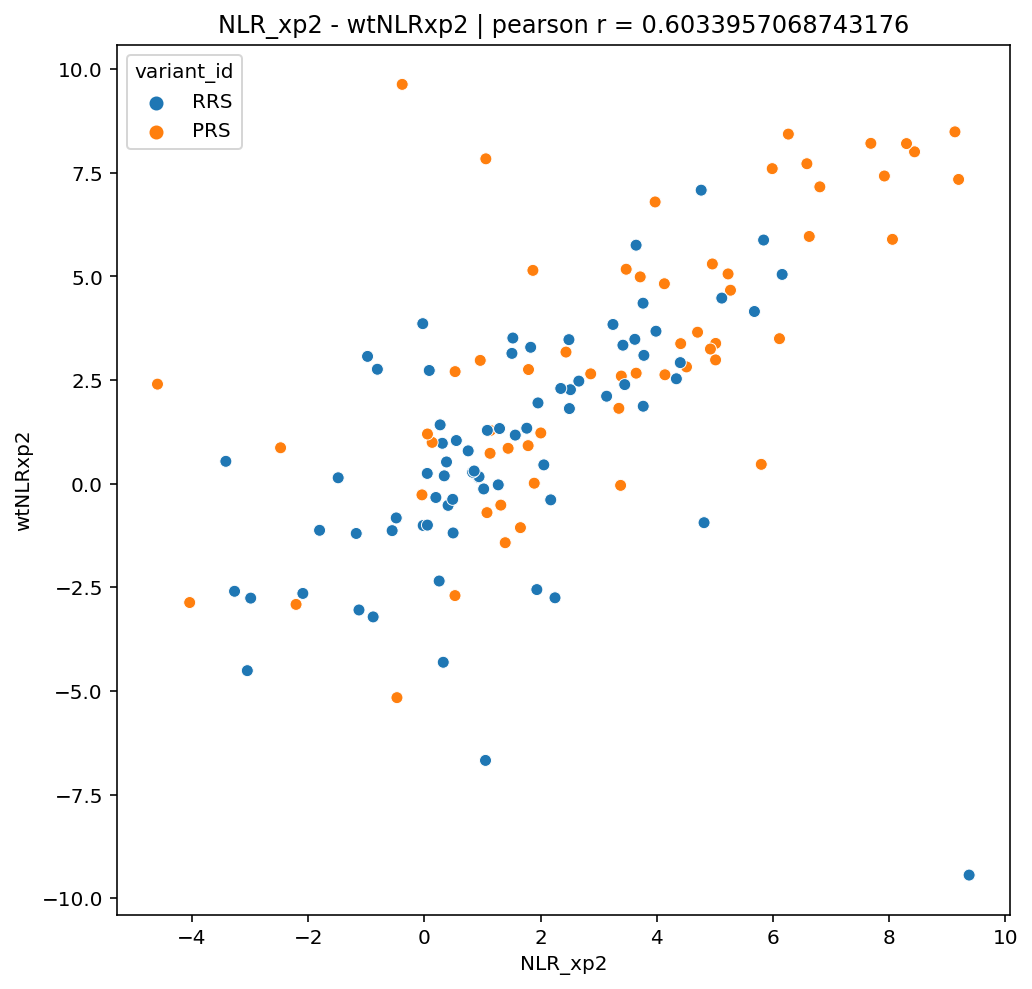

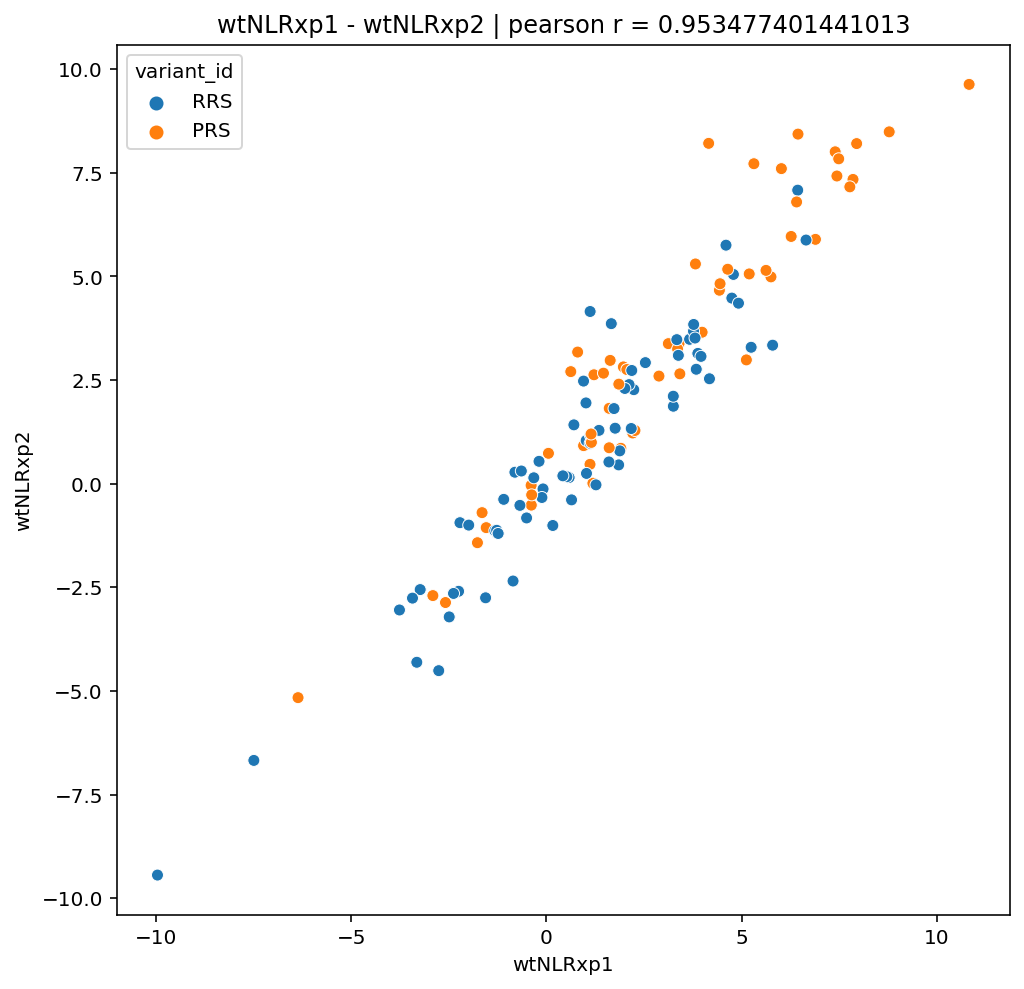

In [98]:
compared = set()
for xp1 in [ 'NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']:
    for xp2 in [ 'NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']:
        if xp1 != xp2 and tuple(sorted([xp1,xp2])) not in compared:
            
            a = prs_rrs_df[(~prs_rrs_df[xp1].isnull())&(~prs_rrs_df[xp2].isnull())][xp1]
            b = prs_rrs_df[(~prs_rrs_df[xp1].isnull())&(~prs_rrs_df[xp2].isnull())][xp2]
            pearson_corr = pearsonr(a, b)
            
            compared.add(tuple(sorted([xp1,xp2])))
            plt.figure(figsize=(8,8))
            plt.title(f'{xp1} - {xp2} | pearson r = {pearson_corr[0]}')
            sns.scatterplot(data=prs_rrs_df, x=xp1,y=xp2, hue='variant_id');
            plt.show()
            #plt.xlim(-7,13)
            #plt.ylim(-7,13)

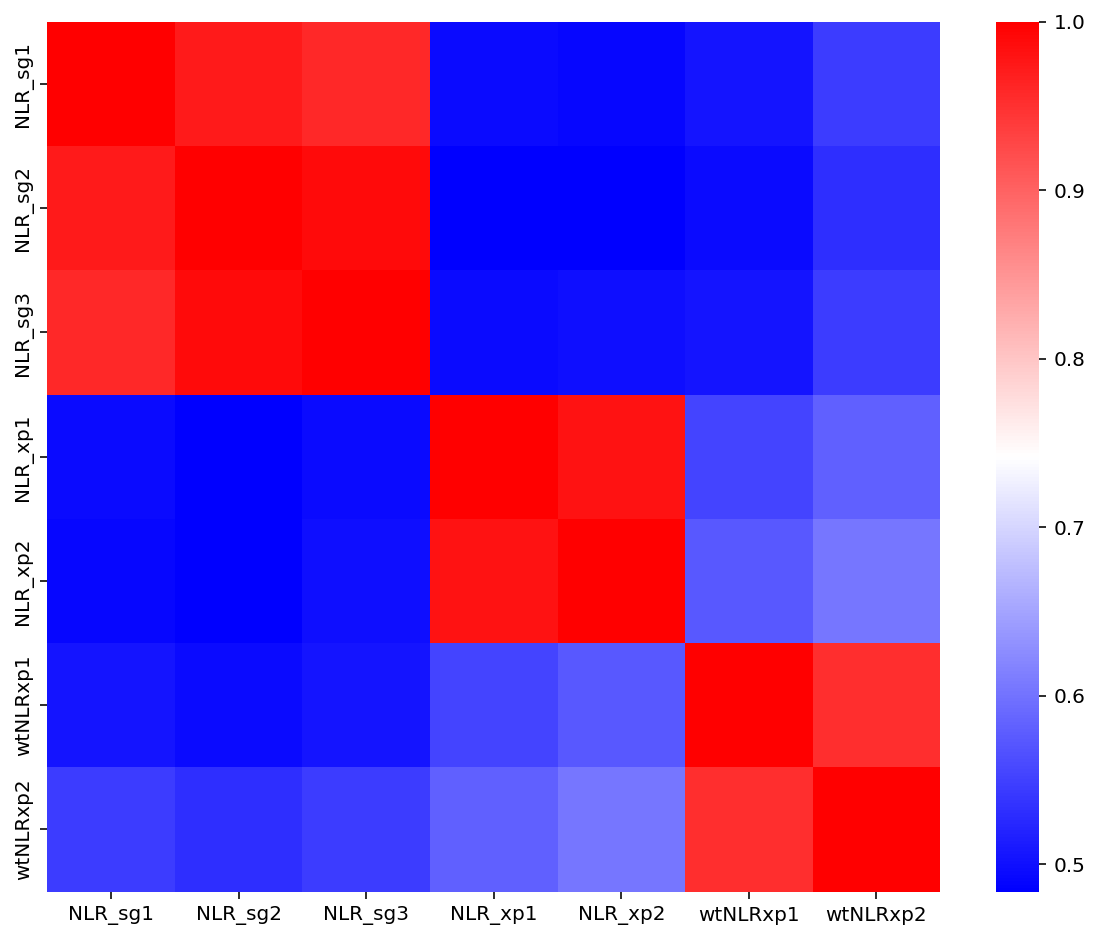

In [99]:
res = {xp:{} for xp in ['NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']}

for xp_i in ['NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']:
    for xp_j in ['NLR_sg1','NLR_sg2', 'NLR_sg3','NLR_xp1','NLR_xp2','wtNLRxp1','wtNLRxp2']:
   

        a = prs_rrs_df[(~prs_rrs_df[xp_i].isnull())&(~prs_rrs_df[xp_j].isnull())][xp_i]
        b = prs_rrs_df[(~prs_rrs_df[xp_i].isnull())&(~prs_rrs_df[xp_j].isnull())][xp_j]

        pearson_corr = pearsonr(a, b)
        
        res[xp_i][xp_j] = pearson_corr[0]

plt.figure(figsize=(10,8))
sns.heatmap(pd.DataFrame(res),cmap='bwr');

### WT pwt vs apwt

In [100]:
normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,NLR_xp1,NLR_xp2,zNLR1,zNLR2,NLR,wt_NLR1,wt_NLR2,wt_zNLR1,wt_zNLR2,wt_NLR,wt_wtNLR1,wt_wtNLR2,wt_wtzNLR1,wt_wtzNLR2,wt_wtNLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0,133281.333333,60561.000000,2.079707e+05,91601.333333,4.102489,4.141402,1.153835,1.187649,4.121945,NaN,NaN,NaN,NaN,NaN,1.219380,2.628899,0.143275,0.643760,1.924139
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0,11384.000000,1559.666667,1.692433e+04,2437.666667,2.002585,2.056176,0.265261,0.311324,2.029380,NaN,NaN,NaN,NaN,NaN,1.852303,0.454815,0.357259,-0.115040,1.153559
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,940280.0,1239510.0,1195485.0,1243182.0,1562153.0,1720736,False,False,1.125092e+06,1.508690e+06,312382.75,736787.0,785866.0,711784.0,779007.0,761326.5,745395.5,5364.0,7114.0,7810.0,59592.666667,65487.333333,1.110043e+05,89346.000000,4.102683,3.764609,1.153917,1.029300,3.933646,NaN,NaN,NaN,NaN,NaN,4.922181,4.355798,1.395148,1.246484,4.638989
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,398751.0,255745.0,319855.0,607223.0,653894.0,667575,False,False,3.247837e+05,6.428973e+05,134203.25,265521.0,280607.0,176930.0,185692.0,273064.0,181311.0,3745.0,6518.0,6973.0,840605.666667,445242.333333,1.126690e+06,928918.000000,-1.371950,-0.809430,-1.162673,-0.892959,-1.090690,NaN,NaN,NaN,NaN,NaN,3.840468,2.762205,1.029433,0.690287,3.301336
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,450691.0,496890.0,592130.0,719638.0,874757.0,944897,False,False,5.132370e+05,8.464307e+05,122400.50,208386.0,264372.0,244423.0,256875.0,236379.0,250649.0,21407.0,23227.0,39366.0,27121.333333,64519.000000,5.824200e+04,77501.666667,2.991829,3.449093,0.683860,0.896703,3.220461,NaN,NaN,NaN,NaN,NaN,2.119291,2.391552,0.447524,0.560921,2.255421


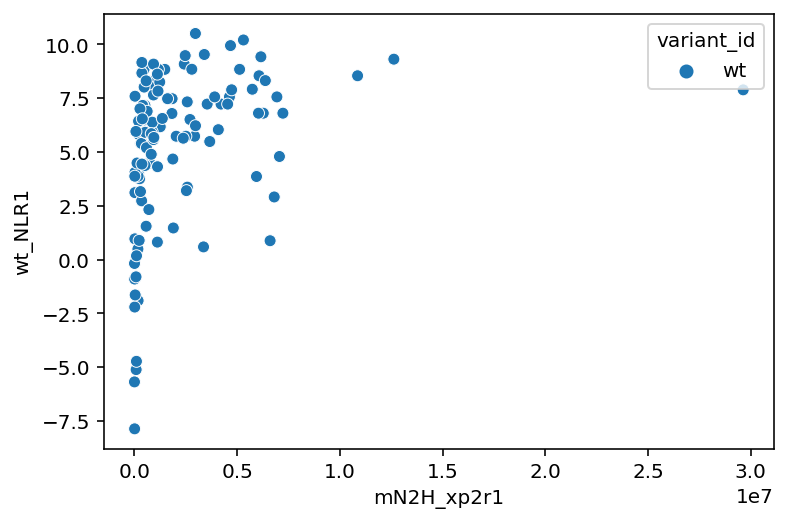

In [101]:
sns.scatterplot(data=normalized_df[normalized_df.variant_id =='wt'], x='mN2H_xp2r1',y='wt_NLR1', hue='variant_id');

In [102]:
normalized_df.variant_id.value_counts()

allele    830
wt        149
RRS        78
PRS        60
Name: variant_id, dtype: int64

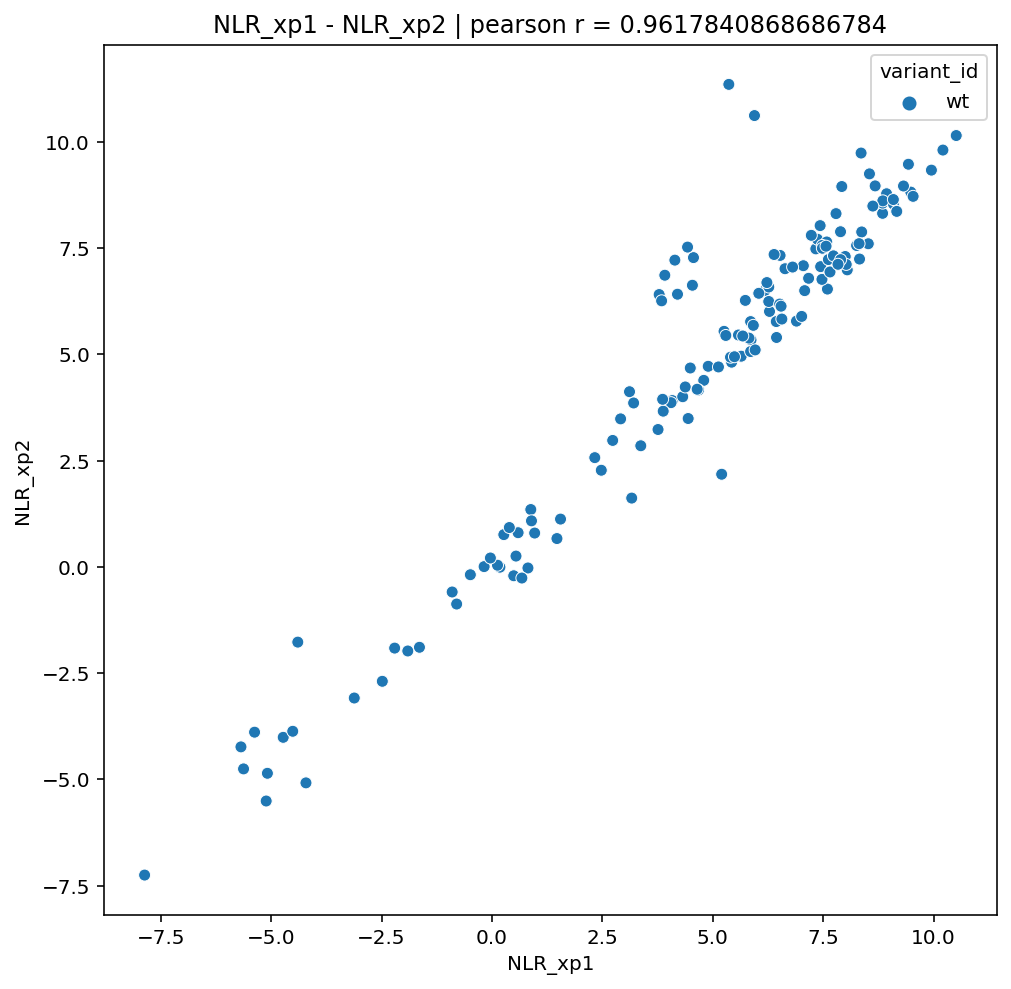

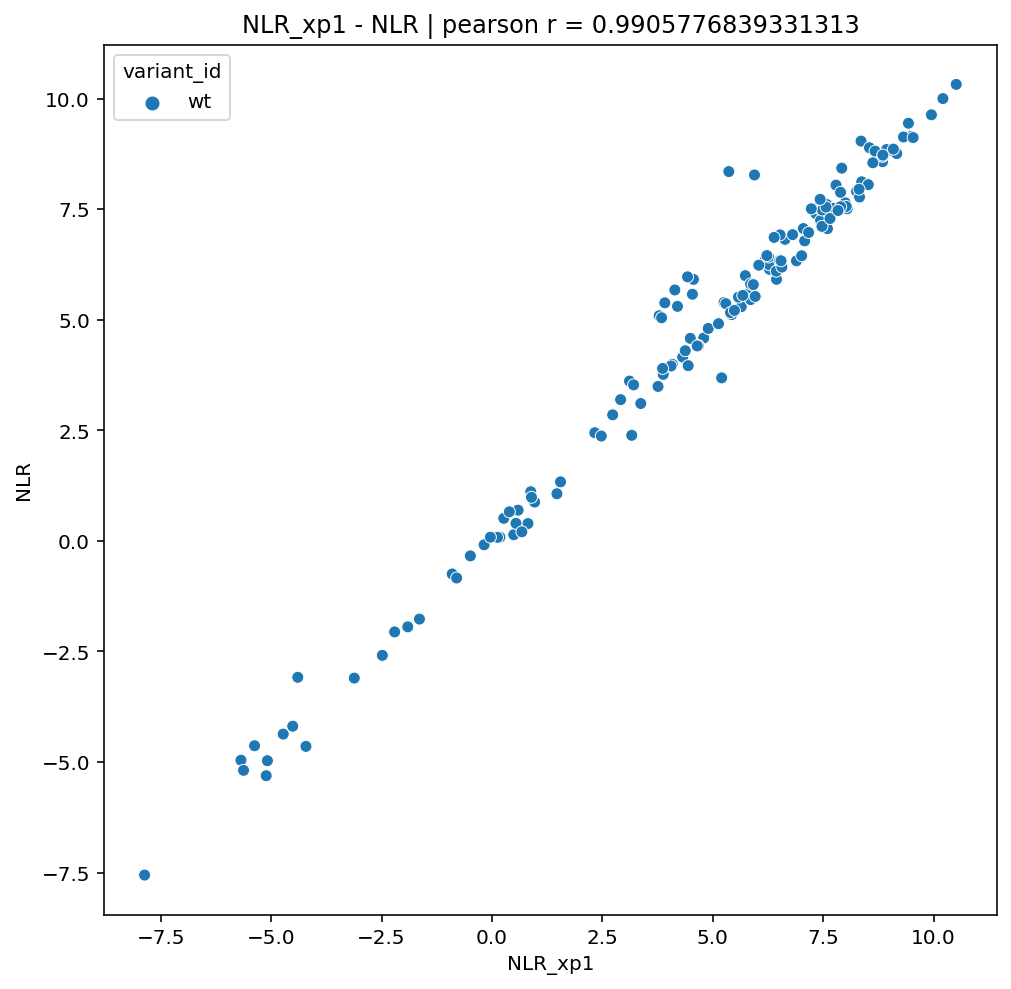

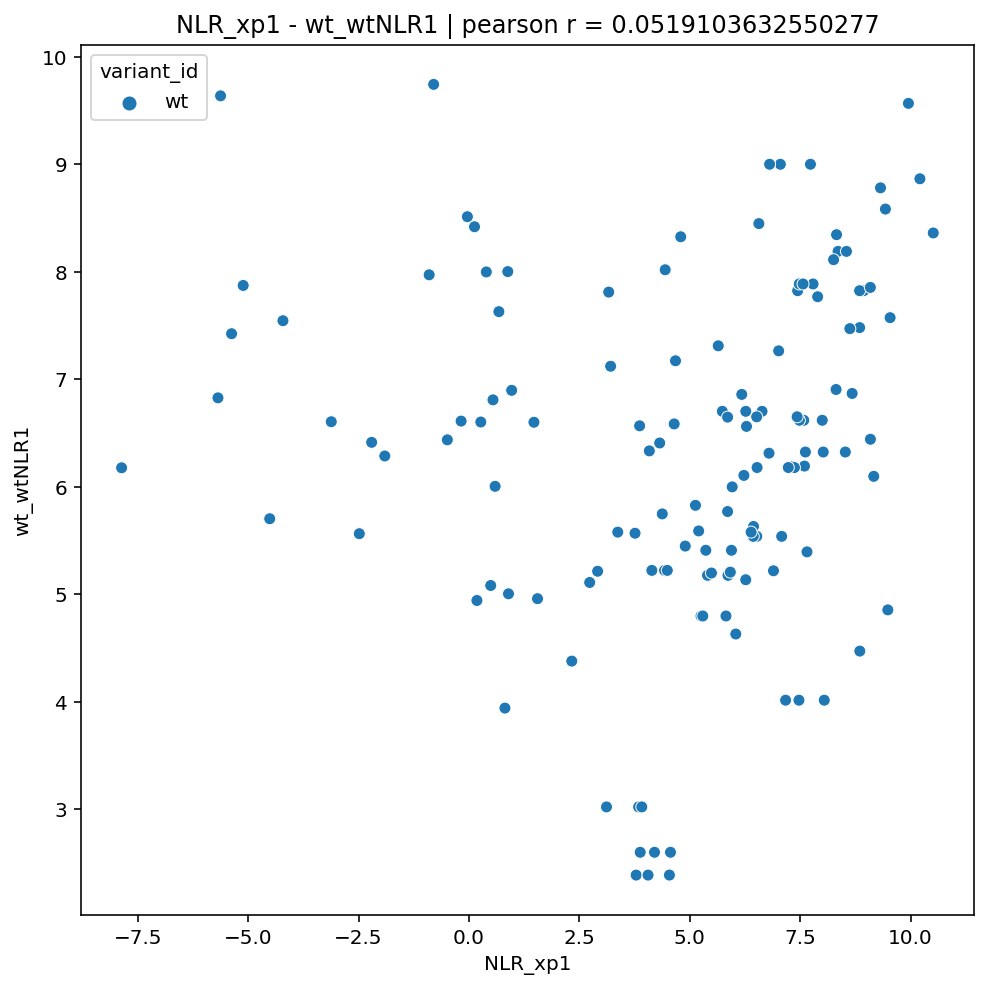

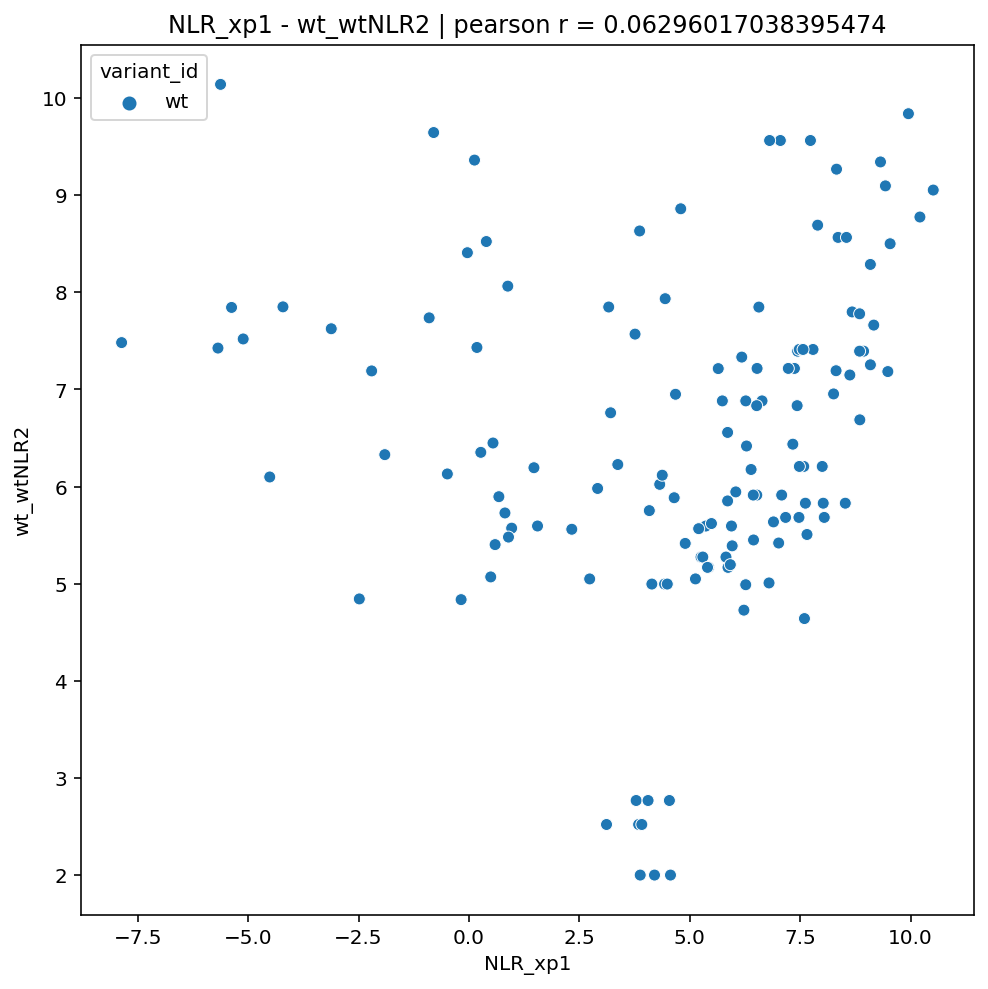

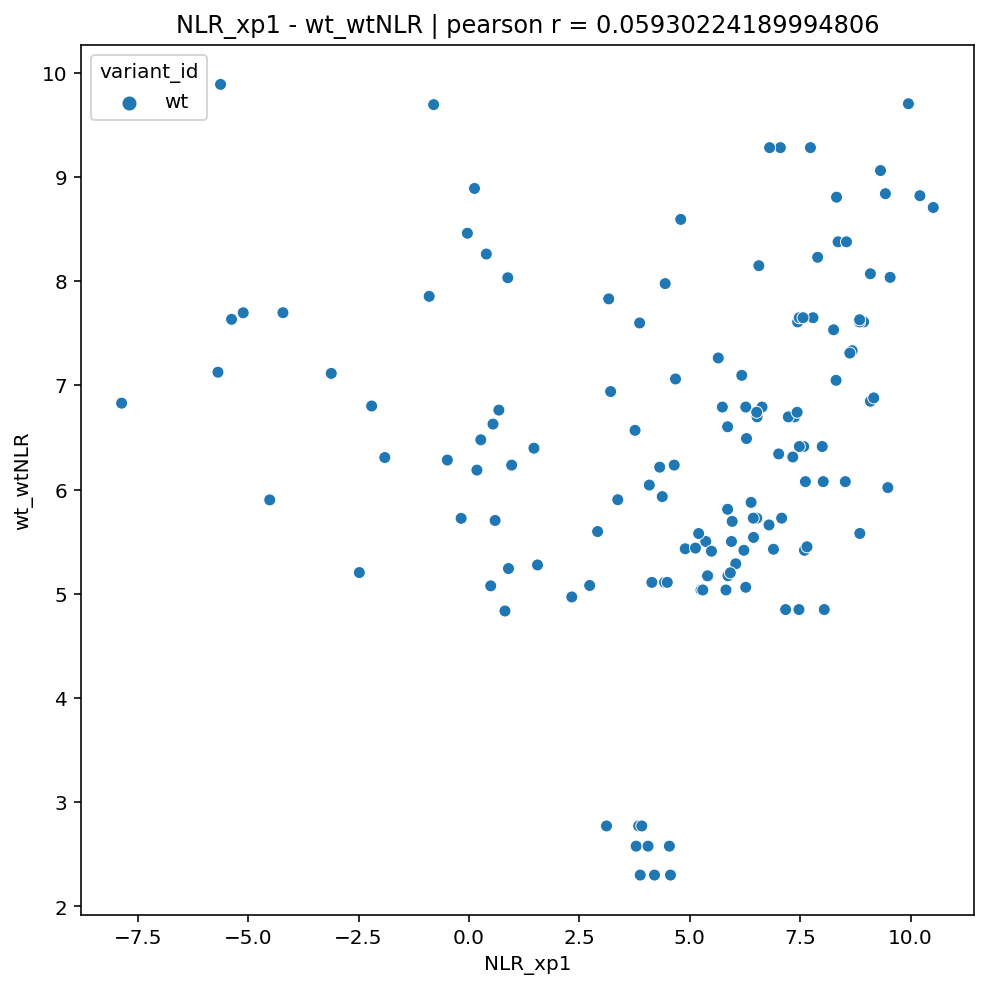

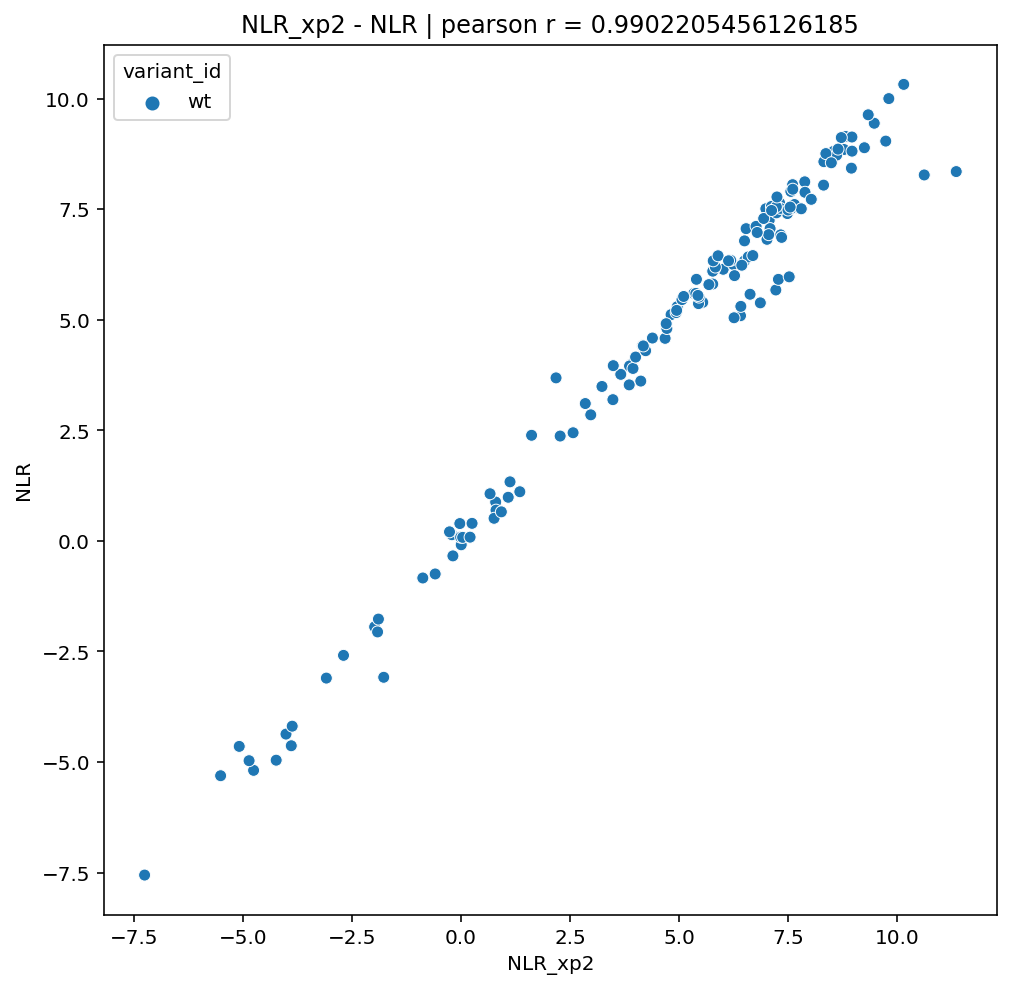

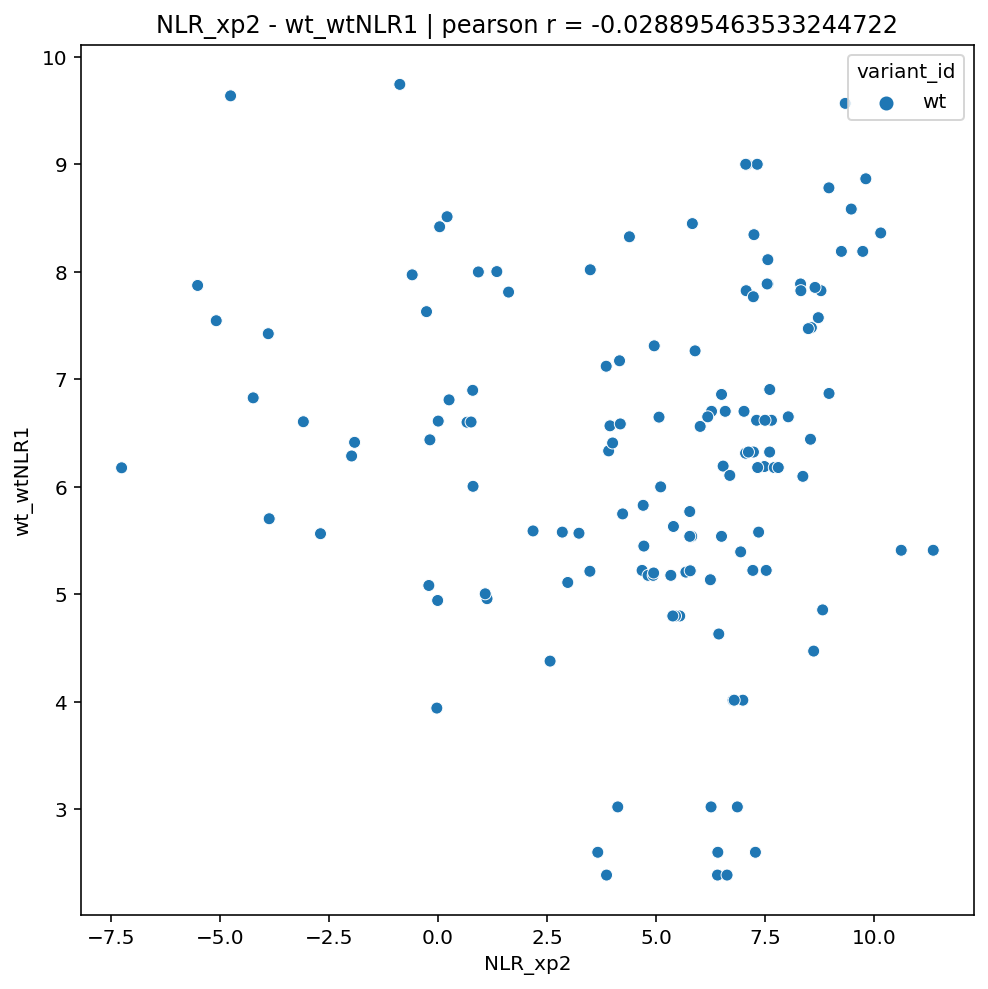

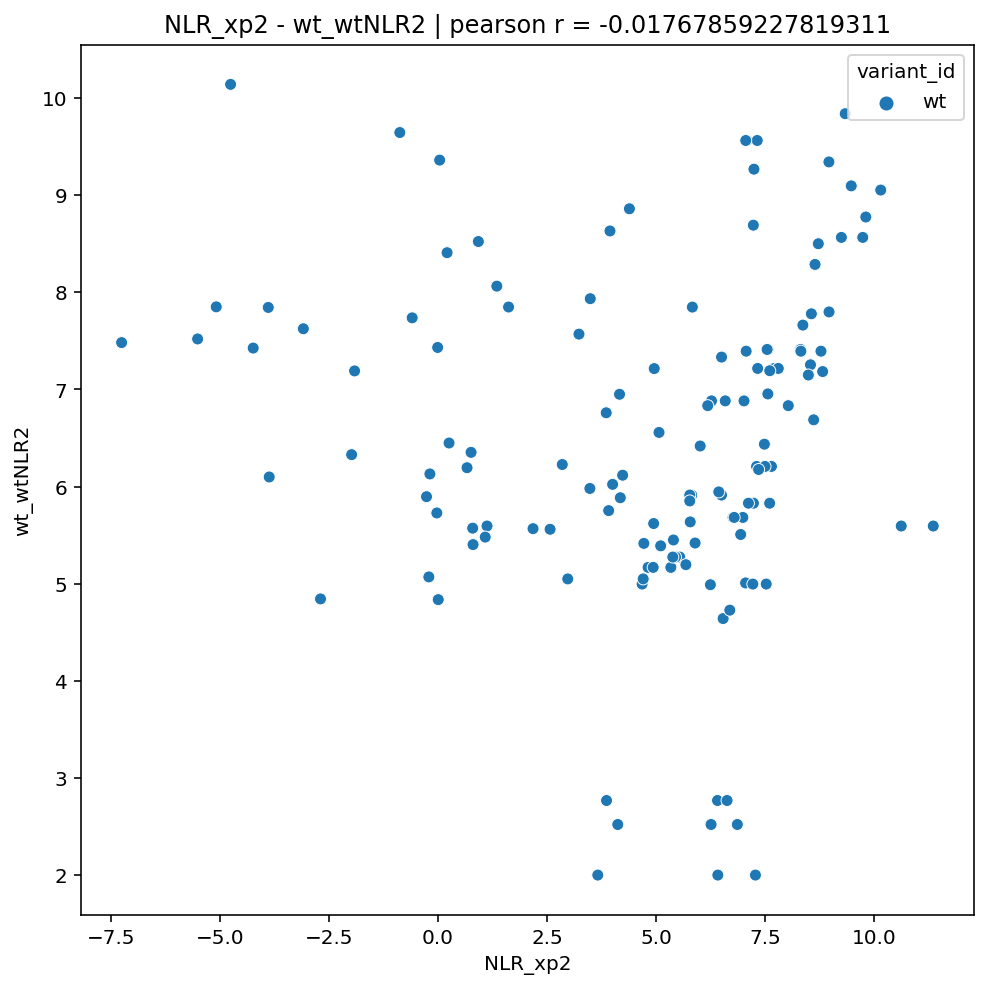

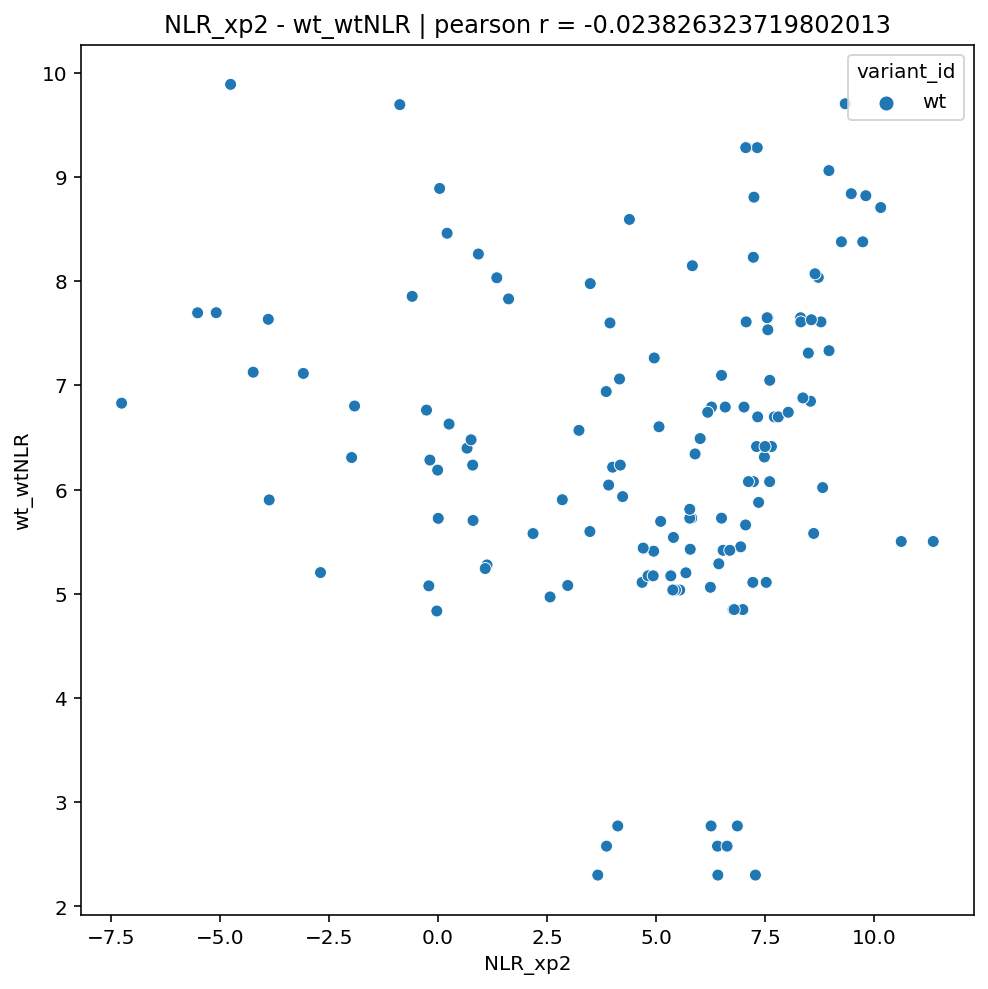

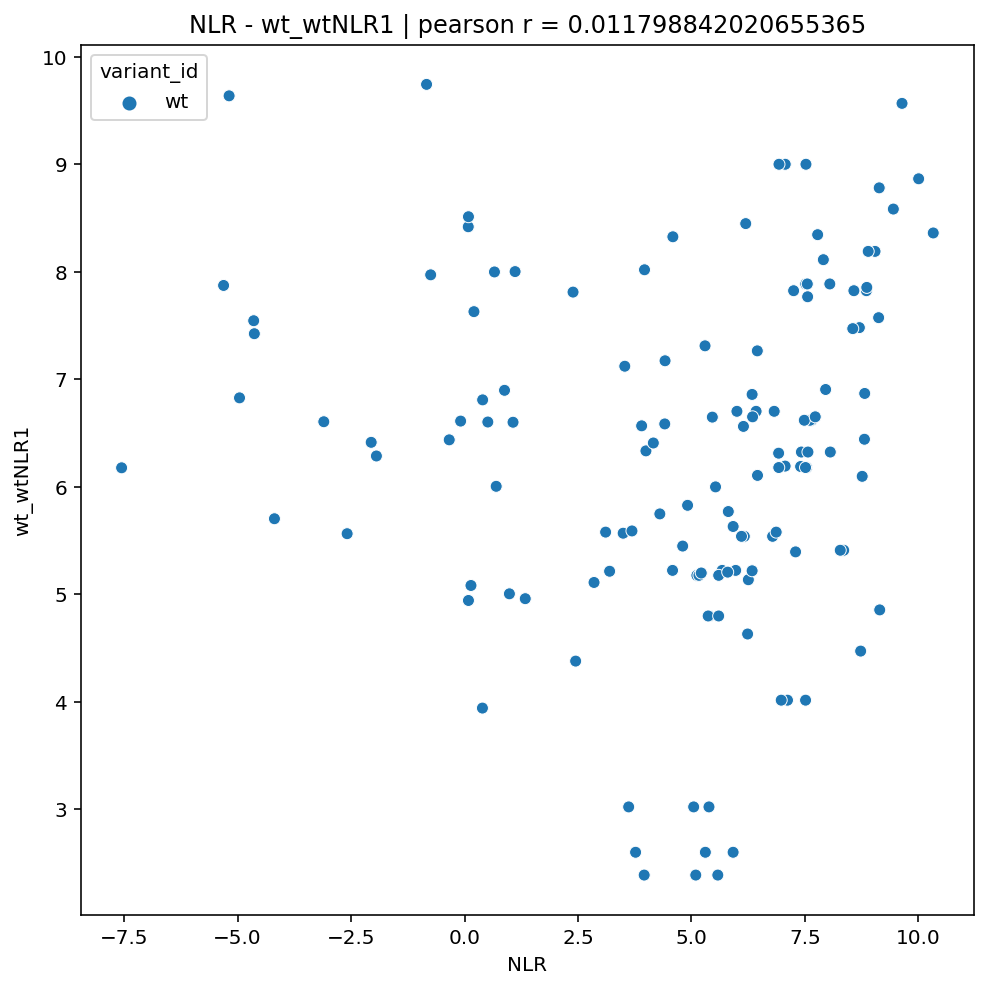

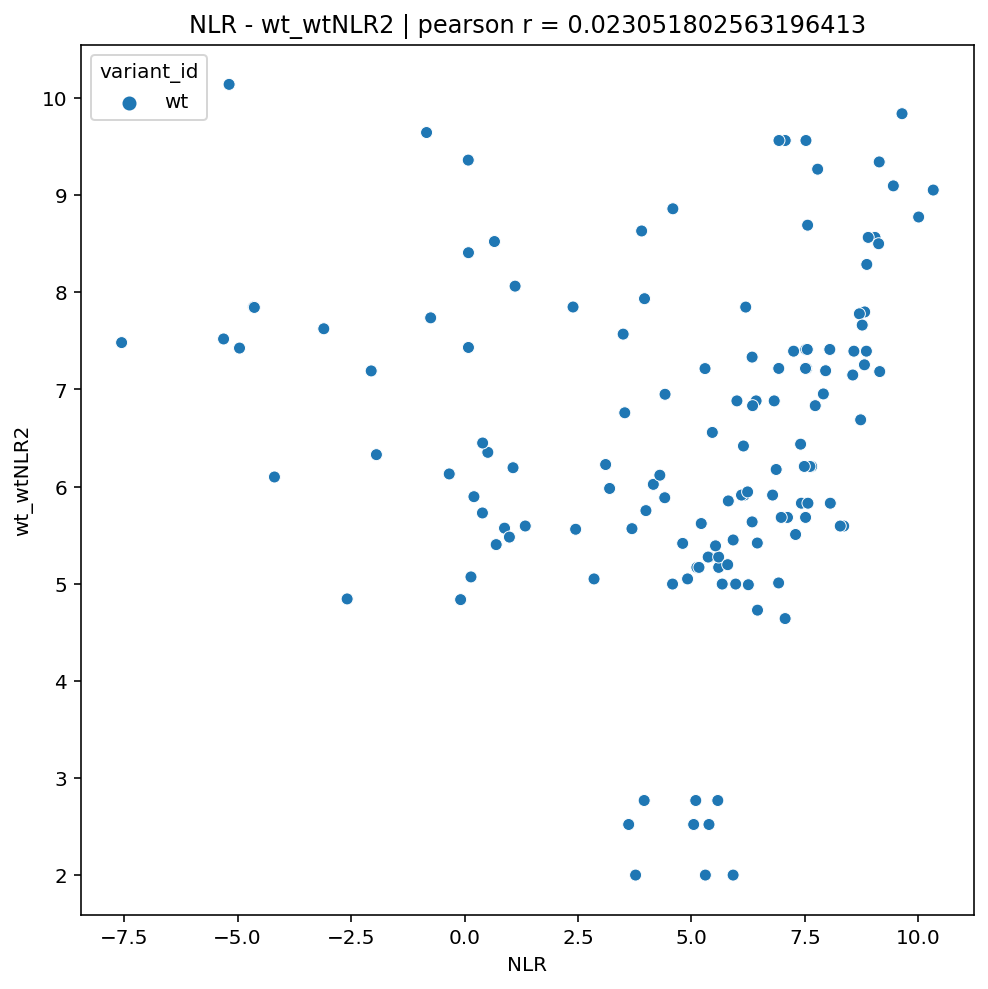

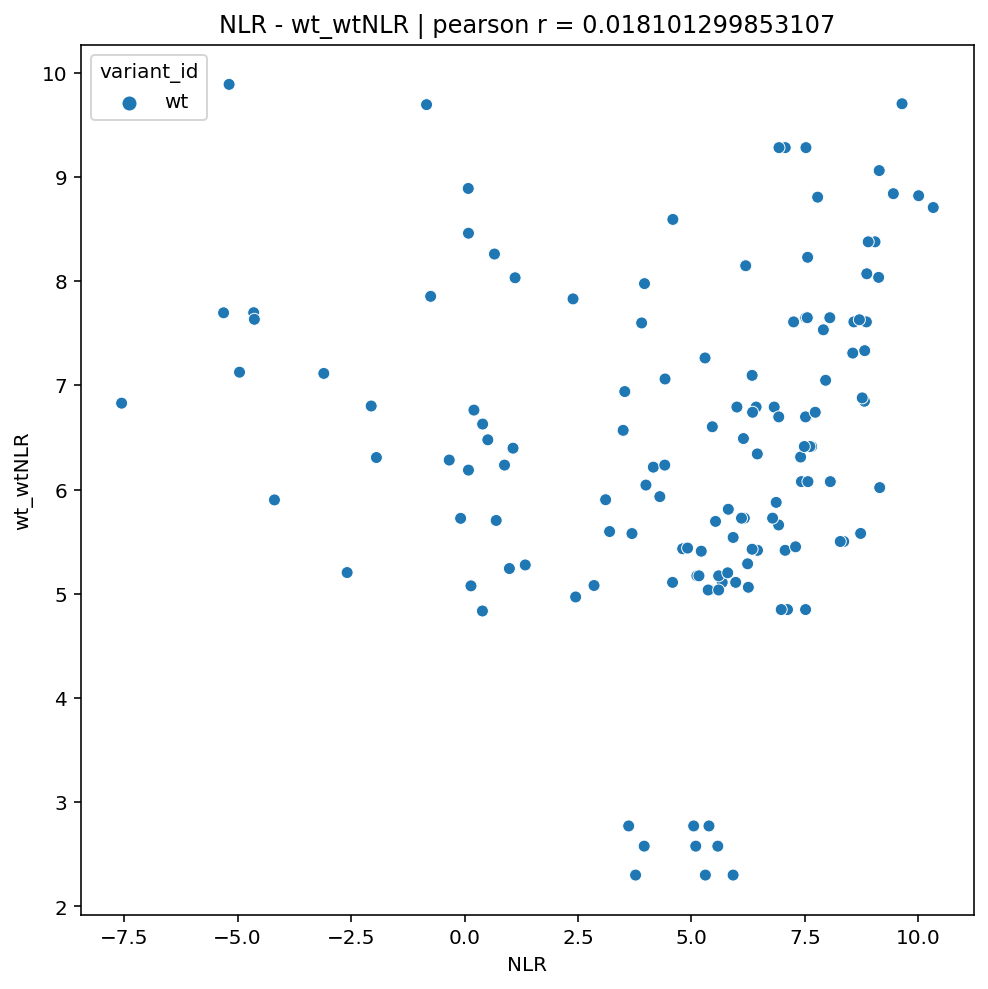

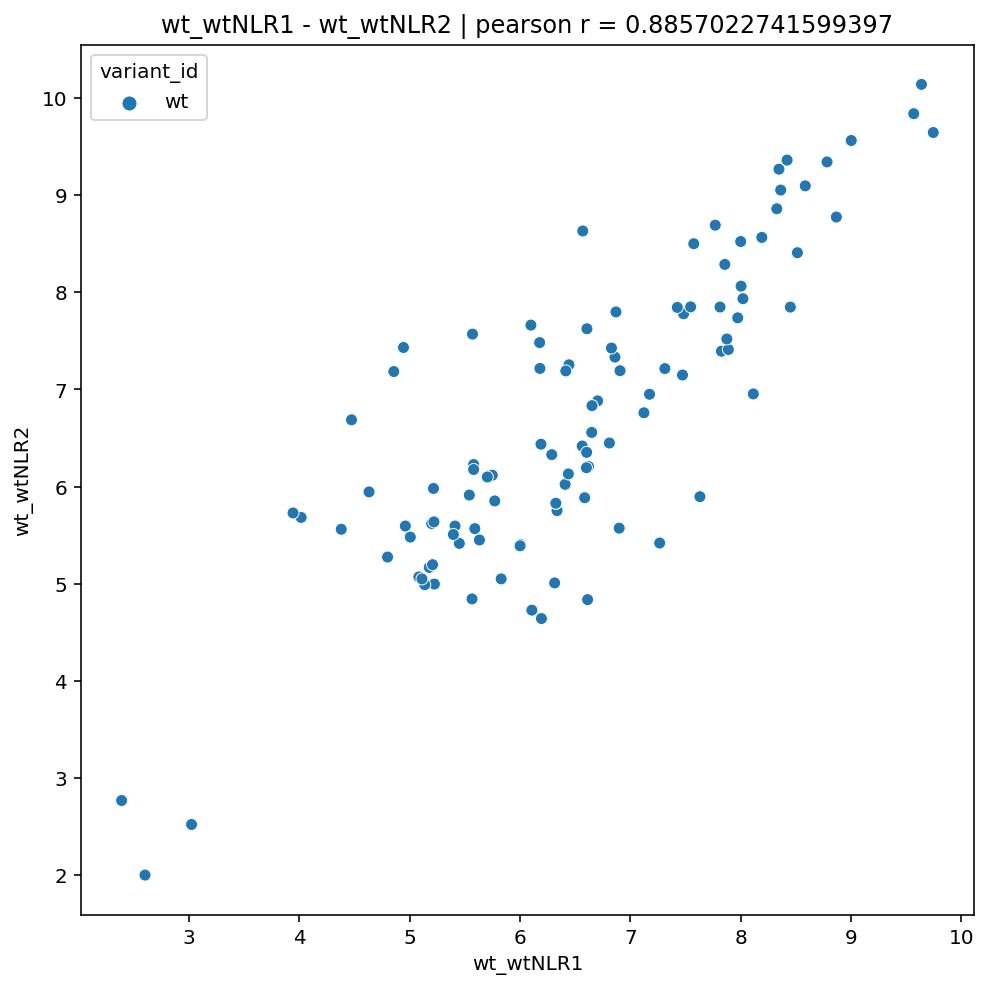

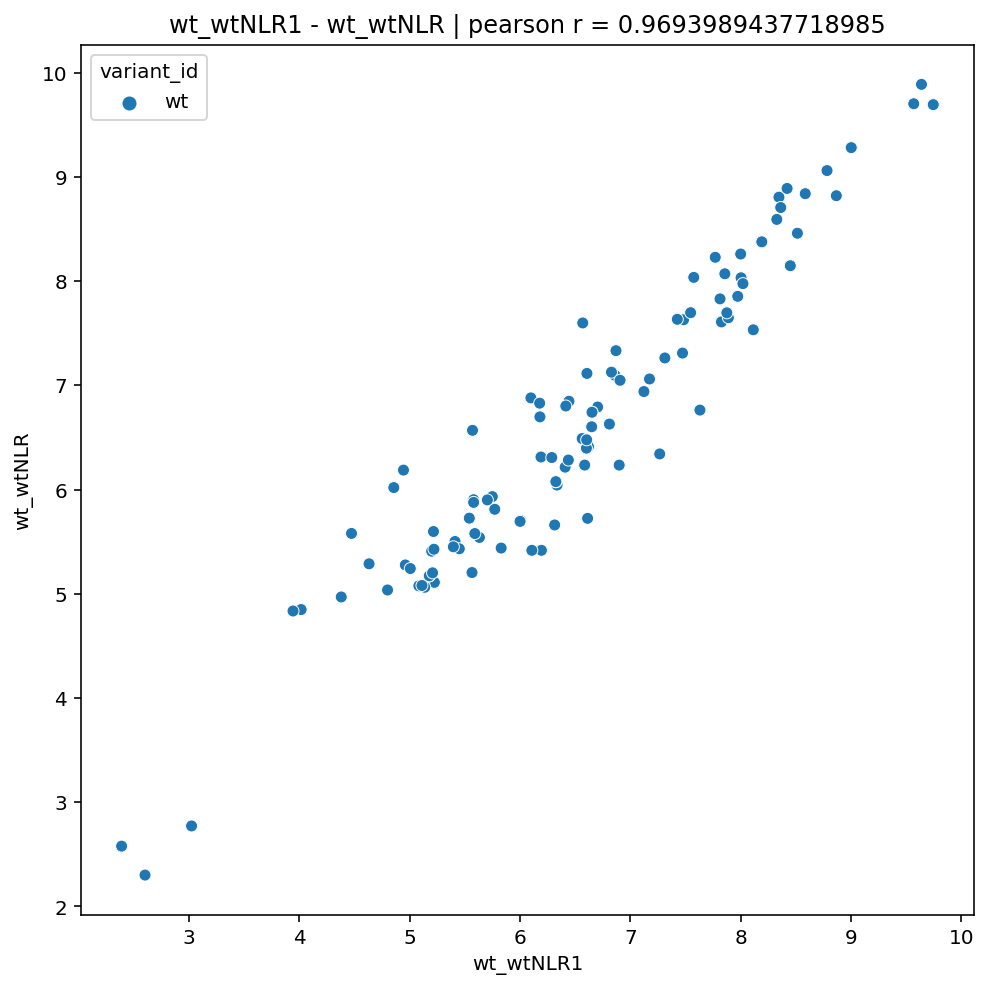

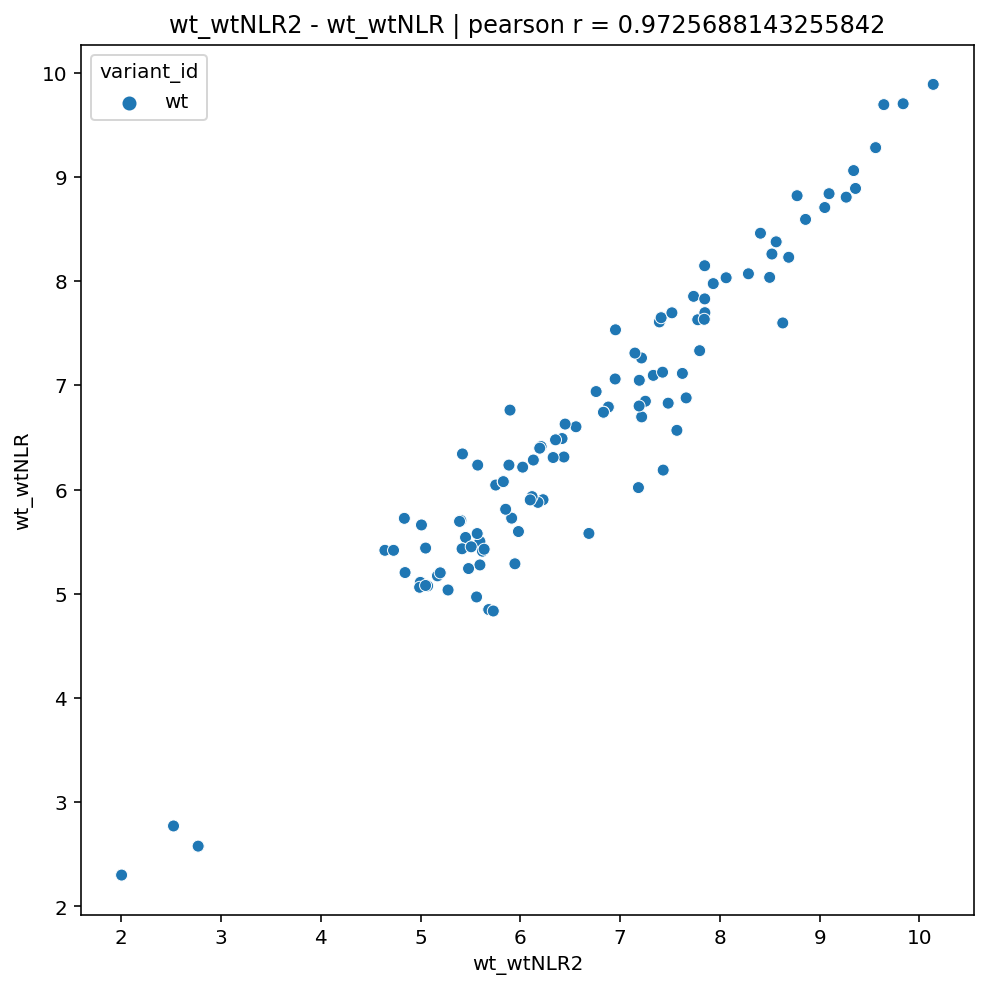

In [103]:
df = normalized_df[normalized_df.variant_id == 'wt']

compared = set()
for xp1 in ['NLR_xp1','NLR_xp2','NLR','wt_wtNLR1','wt_wtNLR2','wt_wtNLR']:
    for xp2 in ['NLR_xp1','NLR_xp2','NLR','wt_wtNLR1','wt_wtNLR2','wt_wtNLR']:
        if xp1 != xp2 and tuple(sorted([xp1,xp2])) not in compared:
            
            a = df[(~df[xp1].isnull())&(~df[xp2].isnull())][xp1]
            b = df[(~df[xp1].isnull())&(~df[xp2].isnull())][xp2]
            pearson_corr = pearsonr(a, b)
            
            compared.add(tuple(sorted([xp1,xp2])))
            plt.figure(figsize=(8,8))
            plt.title(f'{xp1} - {xp2} | pearson r = {pearson_corr[0]}')
            sns.scatterplot(data=df, x=xp1,y=xp2, hue='variant_id');
            plt.show()


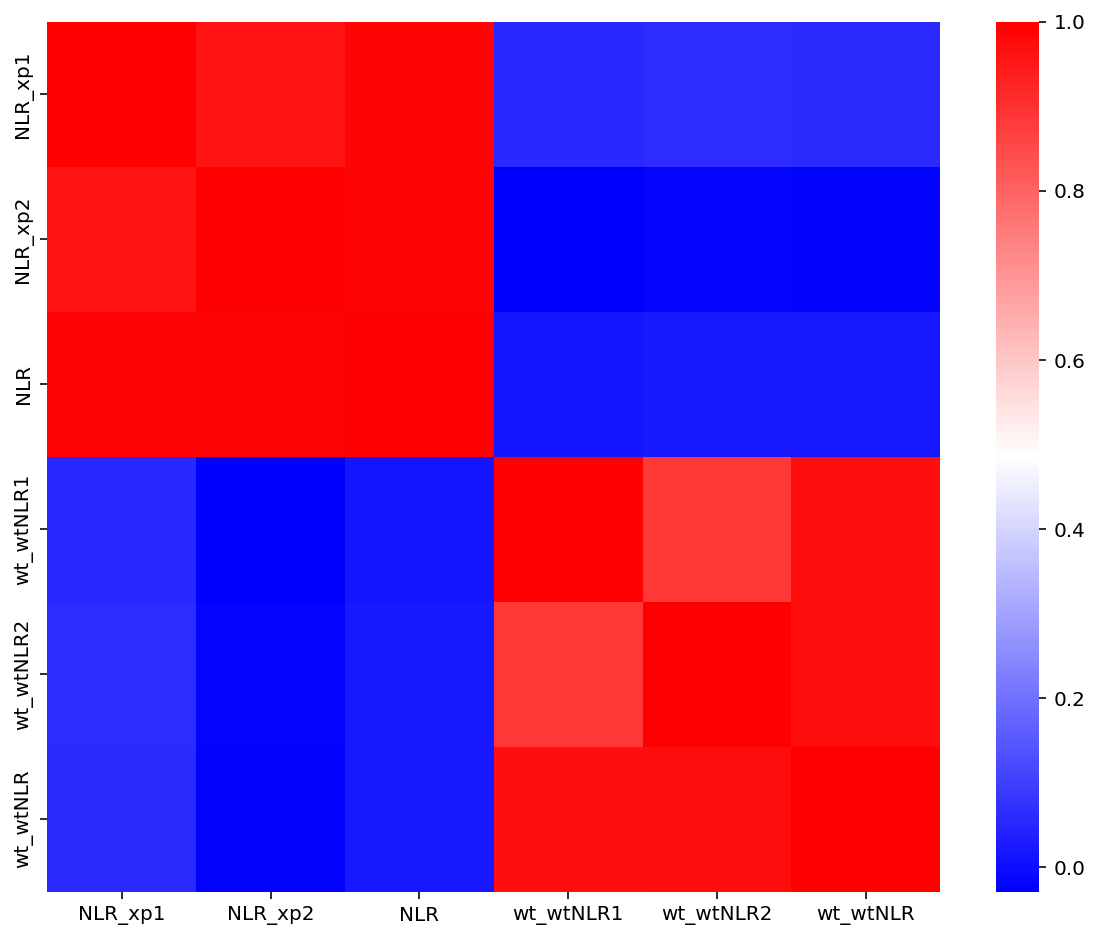

In [104]:
res = {xp:{} for xp in ['NLR_xp1', 'NLR_xp2','NLR','wt_wtNLR1','wt_wtNLR2','wt_wtNLR']}


for xp_i in ['NLR_xp1', 'NLR_xp2','NLR','wt_wtNLR1','wt_wtNLR2','wt_wtNLR']:
    for xp_j in ['NLR_xp1', 'NLR_xp2','NLR','wt_wtNLR1','wt_wtNLR2','wt_wtNLR']:
            
        a = df[(~df[xp_i].isnull())&(~df[xp_j].isnull())][xp_i]
        b = df[(~df[xp_i].isnull())&(~df[xp_j].isnull())][xp_j]
        pearson_corr = pearsonr(a,b)
        res[xp_i][xp_j] = pearson_corr[0]
                     
plt.figure(figsize=(10,8))
sns.heatmap(pd.DataFrame(res),cmap='bwr');

## Retest table to share with Caroline

In [105]:
retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2,previous_apwt,wt_xp1r1,wt_xp1r2,wt_xp2r1,wt_xp2r2,wt_xp1,wt_xp2,SG1,SG2,SG3
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06,825404.25,192581.0,209559.0,209762.0,105286.0,201070.0,157524.0,451586.0,599322.0,749721.0
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,159608.0,102775.0,137461.0,186214.0,208374.0,229324,False,False,1.332813e+05,2.079707e+05,325.25,20545.0,21331.0,15983.0,16701.0,20938.0,16342.0,373.0,427.0,345.0
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,72620.0,89714.0,54138.0,87449.0,113606.0,116952,False,False,7.215733e+04,1.060023e+05,77064.25,84213.0,88493.0,28595.0,22338.0,86353.0,25466.5,383567.0,978929.0,911115.0
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04,23521.50,38327.0,36896.0,10561.0,11943.0,37611.5,11252.0,11082.0,16422.0,22999.0
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,11537.0,9880.0,12735.0,15277.0,16560.0,18936,False,False,1.138400e+04,1.692433e+04,242.50,9603.0,11230.0,7626.0,8793.0,10416.5,8209.5,243.0,354.0,314.0


In [109]:
col = ['N1_orf_id', 'N1_symbol', 'N2_orf_id', 'N2_symbol', 'N2_mut_id',
       'variant_id', 'retest_pla', 'retest_pos',  'xp1', 'xp2', 'empty_N1_xp1', 'empty_N2_xp1', 'empty_N1_xp2',
       'empty_N2_xp2']


to_share = normalized_df[col].copy()
to_share.rename(columns={'xp1':'N1N2_xp1', 'xp2':'N1N2_xp2'},inplace=True)
to_share.to_csv('/Volumes/GoogleDrive/My Drive/Edgotyping_shared/experiment_data_processing/mN2H_experiment/20210823_vus_apwt/mN2H_allele_edgotyping_raw_data.csv')
to_share.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,N1N2_xp1,N1N2_xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667


## Update database

In [ ]:
condition_columns = ['retest_pla', 'retest_pos', 'standard_batch'] #has to be ordered

condition_col_values_d = {(retest_pla, retest_pos, 'VUSAPWT1B1'):{'db_validated':db_validated if db_validated == db_validated else 0} for retest_pla,retest_pos,db_validated in zip(VUSAPWT1B1.retest_pla,VUSAPWT1B1.retest_pos,VUSAPWT1B1.db_validated)}

#update_column('vus', 'retest', condition_columns, condition_col_values_d)

In [ ]:
retest_df.columns

In [ ]:
col = ['retest_pla', 'retest_pos', 'standard_batch','xp1', 'xp2']

condition_columns = ['retest_pla', 'retest_pos', 'standard_batch'] 

condition_col_values_d = {(retest_pla, retest_pos, standard_batch):{'N2H_raw_r01':xp1, 'N2H_raw_r02':xp2} for retest_pla, retest_pos,standard_batch,xp1, xp2 in zip(retest_df.retest_pla,
                                                                                                                                                   retest_df.retest_pos,
                                                                                                                                                   retest_df.standard_batch,
                                                                                                                                                   retest_df.xp1,
                                                                                                                                                    retest_df.xp2)}
update_column('vus', 'retest', condition_columns, condition_col_values_d)
                                                                                                                                                  
                         

In [ ]:
retest_df[retest_df.N2_symbol=='PEX16']

## Perturbations

In [ ]:
sns.kdeplot(data=normalized_df[normalized_df.variant_id.isin(['RRS','wt','allele','PRS'])],x='zNLR1',hue='variant_id');
plt.xlabel('Z-score')

In [ ]:
normalized_df['pair'] = tuple(zip(normalized_df.N1_orf_id, normalized_df.N2_orf_id))

df = normalized_df[((normalized_df.variant_id.isin(['wt','allele']))&(normalized_df.pair.isin(positive_wt)))|
                   (normalized_df.variant_id.isin(['PRS','RRS']))
                  ].copy()

sns.kdeplot(data=df,x='zNLR1',hue='variant_id');
plt.xlabel('Z-score')

In [ ]:
normalized_df.variant_id.value_counts()

In [ ]:
len(normalized_df[(normalized_df.variant_id=='wt')])

In [ ]:
df = normalized_df[(normalized_df.variant_id.isin(['wt','allele']))].copy()
df['pair'] = tuple(zip(df.N1_orf_id, df.N2_orf_id))

positive_wt = tuple(zip(df[(df.variant_id == 'wt')&(df.NLR > 5)].N1_orf_id, df[(df.variant_id == 'wt')&(df.NLR > 5)].N2_orf_id))

len(positive_wt)

In [ ]:
df[(df.variant_id=='wt')&(df.NLR > 5)].N2_orf_id.nunique()

In [ ]:
df[(df.variant_id=='wt')].N2_orf_id.nunique()

In [ ]:
((df.variant_id == 'allele')&(df.pair.isin(positive_wt))).sum()

In [ ]:
((df.variant_id == 'allele')).sum()

In [ ]:
df[((df.variant_id == 'allele')&(df.pair.isin(positive_wt)))].N2_mut_id.nunique()

In [ ]:
df[(df.variant_id == 'allele')].N2_mut_id.nunique()

In [ ]:
len(normalized_df[(normalized_df.variant_id=='allele')&(normalized_df.N2_orf_id.isin(l))])

In [ ]:
normalized_df[(normalized_df.variant_id=='allele')&(normalized_df.N2_orf_id.isin(l))].N2_orf_id.nunique()

In [ ]:
len(normalized_df[(normalized_df.variant_id=='allele')&(normalized_df.NLR > 5)&(normalized_df.N2_orf_id.isin(l))])

In [ ]:
normalized_df

In [ ]:
normalized_df[(normalized_df.variant_id=='wt')&(normalized_df.)]

In [ ]:
normalized_df[normalized_df.variant_id=='allele'].head()

In [ ]:
help(pearsonr)

In [ ]:
for pla in range(5,24):
    df = normalized_df[(normalized_df.retest_pla == pla)&(normalized_df.variant_id == 'wt')]
    
    a = df[(~df.NLR.isnull())&(~df.wt_wtNLR.isnull())].NLR
    b = df[(~df.NLR.isnull())&(~df.wt_wtNLR.isnull())].wt_wtNLR
    pearson_corr = pearsonr(a, b)
    
    print(pla, len(a), pearson_corr[0], pearson_corr[1], pearson_corr)